# NYPD Complaint Data - Analysis

Este conjunto de datos incluye todos los delitos graves (felony), menores (misdemeanor) y por infracciones (violation) válidos denunciados al Departamento de Policía de la Ciudad de Nueva York (NYPD) desde Enero a Junio de 2026.

In [1]:
import pandas as pd
from pandas.api.types import CategoricalDtype
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as st
from scipy.stats import describe
import missingno as msno
import statsmodels.api as sm
from IPython.display import Image
import matplotlib.dates as mdates
from matplotlib.patches import Circle, Patch, Wedge
from matplotlib.ticker import FuncFormatter

# Human-readable labels shared by all chart helpers.
PLOT_LABELS = {
    'CMPLNT_NUM': 'Número de denuncia',
    'ADDR_PCT_CD': 'Precinto policial',
    'BORO_NM': 'Municipio (borough)',
    'CRM_ATPT_CPTD_CD': 'Resultado del hecho (intento/completado)',
    'JURISDICTION_CODE': 'Código de jurisdicción',
    'JURIS_DESC': 'Descripción de jurisdicción',
    'KY_CD': 'Código del delito (KY_CD)',
    'LAW_CAT_CD': 'Categoría legal',
    'LOC_OF_OCCUR_DESC': 'Lugar de ocurrencia',
    'PATROL_BORO': 'Borough de patrullaje',
    'PD_CD': 'Código de clasificación policial (PD_CD)',
    'PD_DESC': 'Descripción del código policial',
    'PREM_TYP_DESC': 'Tipo de lugar de ocurrencia',
    'OFNS_DESC': 'Descripción del delito',
    'SUSP_AGE_GROUP': 'Grupo etario del sospechoso',
    'SUSP_RACE': 'Raza del sospechoso',
    'SUSP_SEX': 'Sexo del sospechoso',
    'VIC_AGE_GROUP': 'Grupo etario de la víctima',
    'VIC_RACE': 'Raza de la víctima',
    'VIC_SEX': 'Sexo de la víctima',
    'TRANSIT_DISTRICT': 'Distrito de tránsito',
    'X_COORD_CD': 'Coordenada X (pies)',
    'Y_COORD_CD': 'Coordenada Y (pies)',
    'Latitude': 'Latitud',
    'Longitude': 'Longitud',
    'CMPLNT_FR_DT_FORMATTED': 'Fecha de ocurrencia',
    'RPT_DT_FORMATTED': 'Fecha de reporte',
    'CMPLNT_FR_TM': 'Hora de ocurrencia',
    'HOUR_PLOT': 'Hora del día',
    'WEEKDAY_PLOT': 'Día de la semana',
    'KY_CD_LABEL_PLOT': 'Código del delito (KY_CD) y descripción',
    'PD_CD_LABEL_PLOT': 'Código policial (PD_CD) y descripción',
    'JURISDICTION_CODE_LABEL_PLOT': 'Código de jurisdicción y descripción'
}

def plot_label(column):
    if column is None:
        return ''
    return PLOT_LABELS.get(
        column, str(column).replace('_PLOT', '').replace('_', ' ')
    )


## Algunas funciones útiles para graficar obtenidas de los notebooks de las clases

In [2]:
# Función para graficar
def plot_histograma(data, column, figsize=(6, 3), bins=15, kde=True, mvd=True, shade=True, snk=False):
    skewness = (data[column]).skew()
    kurtosis = (data[column]).kurt()
    media = (data[column]).mean()
    var = (data[column]).var()
    std = (data[column]).std()
    plt.figure(figsize=figsize)
    plt.grid(axis='y')
    sns.histplot(data[column], bins=bins, kde=kde)
    if snk:
        plt.figtext(0.7, 0.8, f'Asimetría: {skewness:.2f}', fontsize=10, color='blue')
        plt.figtext(0.715, 0.73, f'Curtosis: {kurtosis:.2f}', fontsize=10, color='blue')
        plt.axvline(media, color='red', linestyle='--', label='Media')
 

    # Sombreado
    if mvd and shade:
        plt.axvspan(media - std, media + std, alpha=0.1, color='orange', label='±1 Std')
        plt.axvline(media + std, color='orange', linestyle=':', label='+1 Std')
        plt.axvline(media - std, color='orange', linestyle=':', label='-1 Std')
        plt.figtext(0.15, 0.80, f'Media: {media:.2f}', fontsize=10, color='red')
        plt.figtext(0.15, 0.73, f'Var:   {var:.2f}',   fontsize=10, color='red')
        plt.figtext(0.15, 0.66, f'Std:   {std:.2f}',   fontsize=10, color='orange')

    

    plt.title(f'Variable: {plot_label(column)}')
    plt.xlabel(plot_label(column))
    plt.ylabel('Frecuencia')
    plt.show()
    
    return

In [3]:
def cuartiles(variable):
    Q1 = variable.quantile(0.25)
    Q2 = variable.quantile(0.50)  # Percentile 5-0 - Equivalente a la mediana
    Q3 = variable.quantile(0.75)
    return Q1, Q2, Q3

In [4]:
def print_categorias(dataframe, columna):
    print(f"Cantidad de categorías que tiene la variable '{columna}': {dataframe[columna].nunique()}\n")
    print(f"Nombres de categorías presentes en la variable '{columna}': {dataframe[columna].unique()}\n")
    
    freq = dataframe[columna].value_counts()
    freq_rel = dataframe[columna].value_counts(normalize=True).mul(100).round(2)
    
    freq_tabla = pd.DataFrame({'Frecuencia absoluta': freq, 'Frecuencia relativa (%)': freq_rel})
    
    print(f"Frecuencias de cada categoría en la variable '{columna}':\n{freq_tabla}\n")

In [6]:
def plot_pie_by_column(data, column, ax=None, startangle=90, palette='pastel', title=None):
    counts = data[column].value_counts()
    
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 3))
    
    ax.pie(
        counts,
        labels=counts.index,
        autopct='%1.1f%%',
        startangle=startangle,
        colors=sns.color_palette(palette)
    )
    ax.set_title(title if title else f'Distribución de {plot_label(column)}')
    ax.axis('equal') # Asegura que el gráfico sea circular

In [7]:
def plot_frecuencias_relativas(data, column, ax=None, palette='viridis', figsize=(9, 4), title=None):
    total = len(data)
    relative_freq = data[column].value_counts() / total

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)

    sns.barplot(x=relative_freq.values, y=relative_freq.index, hue=relative_freq.index, 
                palette=palette, ax=ax, legend=False)
    
    ax.set_title(title if title else f'Frecuencias relativas de {plot_label(column)}')
    ax.set_xlabel('Frecuencia relativa')
    ax.set_ylabel(plot_label(column))

In [8]:
def plot_violin_box(data, num_col, cat_col, figsize=(12, 4), palette='pastel', title=None):
    fig, axes = plt.subplots(1, 2, figsize=figsize, sharey=True)

    # Violin plot
    sns.violinplot(data=data, x=cat_col, y=num_col, hue=cat_col,
                   palette=palette, ax=axes[0], legend=False)
    axes[0].set_title(f'Violin: {plot_label(num_col)} vs. {plot_label(cat_col)}')
    axes[0].grid(axis='y', ls='--')
    axes[0].set_xlabel(plot_label(cat_col))
    axes[0].set_ylabel(plot_label(num_col))

    # Box plot
    sns.boxplot(data=data, x=cat_col, y=num_col, hue=cat_col,
                palette=palette, ax=axes[1], legend=False)
    axes[1].set_title(f'Boxplot: {plot_label(num_col)} vs. {plot_label(cat_col)}')
    axes[1].grid(axis='y', ls='--')
    axes[1].set_xlabel(plot_label(cat_col))

    plt.suptitle(title if title else f'{plot_label(num_col)} vs {plot_label(cat_col)}', fontsize=13)
    plt.tight_layout()
    plt.show()

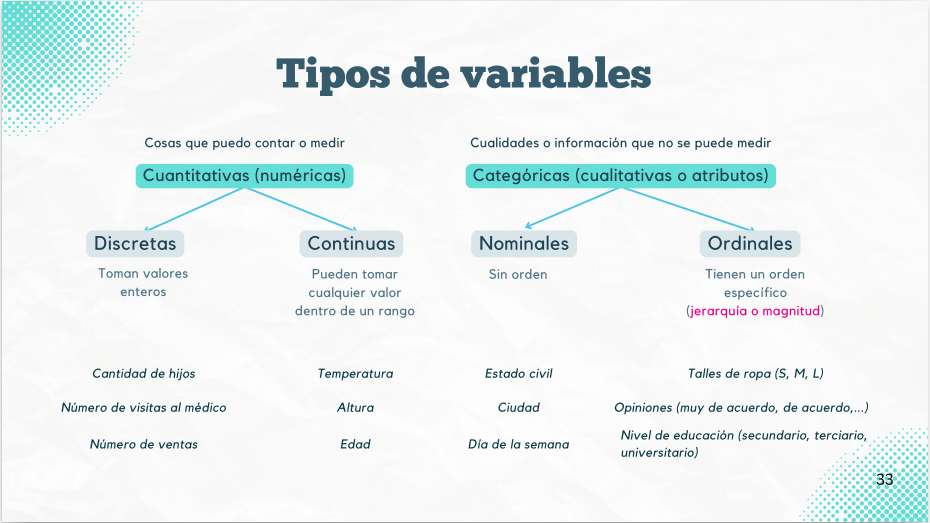

In [ ]:
image_path = '../clases/tipos_de_variables.png'
Image(filename=image_path)

## Cantidad de filas

- Total: 279512

## Columnas

| Código | Descripción | Tipo de dato |
|---|---|---|
| `CMPLNT_NUM` | Randomly generated persistent ID for each complaint | categórica nominal |
| `ADDR_PCT_CD` | The precinct in which the incident occurred | categórica nominal |
| `BORO_NM` | The name of the borough in which the incident occurred (`BORO` in the data dictionary) | categórica nominal |
| `CMPLNT_FR_DT` | Exact date of occurrence for the reported event (or starting date of occurrence, if `CMPLNT_TO_DT` exists) | categórica ordinal |
| `CMPLNT_FR_TM` | Exact time of occurrence for the reported event (or starting time of occurrence, if `CMPLNT_TO_TM` exists) | categórica ordinal |
| `CMPLNT_TO_DT` | Ending date of occurrence for the reported event, if exact time of occurrence is unknown | categórica ordinal |
| `CMPLNT_TO_TM` | Ending time of occurrence for the reported event, if exact time of occurrence is unknown | categórica ordinal |
| `CRM_ATPT_CPTD_CD` | Indicator of whether crime was successfully completed or attempted, but failed or was interrupted prematurely | categórica nominal |
| `HADEVELOPT` | Name of NYCHA housing development of occurrence, if applicable | categórica nominal |
| `HOUSING_PSA` | Development Level Code | categórica nominal |
| `JURISDICTION_CODE` | Jurisdiction responsible for incident. Either internal, like Police (0), Transit (1), and Housing (2); or external (3), like Correction, Port Authority, etc. | categórica nominal |
| `JURIS_DESC` | Description of the jurisdiction code | categórica nominal |
| `KY_CD` | Three digit offense classification code | categórica nominal |
| `LAW_CAT_CD` | Level of offense: felony, misdemeanor, violation | categórica ordinal |
| `LOC_OF_OCCUR_DESC` | Specific location of occurrence in or around the premises; inside, opposite of, front of, rear of | categórica nominal |
| `OFNS_DESC` | Description of offense corresponding with key code | categórica nominal |
| `PARKS_NM` | Name of NYC park, playground or greenspace of occurrence, if applicable (state parks are not included) | categórica nominal |
| `PATROL_BORO` | The name of the patrol borough in which the incident occurred | categórica nominal |
| `PD_CD` | Three digit internal classification code (more granular than Key Code) | categórica nominal |
| `PD_DESC` | Description of internal classification corresponding with PD code (more granular than Offense Description) | categórica nominal |
| `PREM_TYP_DESC` | Specific description of premises; grocery store, residence, street, etc. | categórica nominal |
| `RPT_DT` | Date event was reported to police | categórica ordinal |
| `STATION_NAME` | Transit station name | categórica nominal |
| `SUSP_AGE_GROUP` | Suspect’s Age Group | categórica ordinal |
| `SUSP_RACE` | Suspect’s Race Description | categórica nominal |
| `SUSP_SEX` | Suspect’s Sex Description | categórica nominal |
| `TRANSIT_DISTRICT` | Transit district in which the offense occurred | categórica nominal |
| `VIC_AGE_GROUP` | Victim’s Age Group | categórica ordinal |
| `VIC_RACE` | Victim’s Race Description | categórica nominal |
| `VIC_SEX` | Victim’s Sex Description (`D` = Business/Organization, `E` = PSNY/People of the State of New York, `F` = Female, `M` = Male) | categórica nominal |
| `X_COORD_CD` | X-coordinate for New York State Plane Coordinate System, Long Island Zone, NAD 83, units feet (FIPS 3104) | cuantitativa continua |
| `Y_COORD_CD` | Y-coordinate for New York State Plane Coordinate System, Long Island Zone, NAD 83, units feet (FIPS 3104) | cuantitativa continua |
| `Latitude` | Midblock Latitude coordinate for Global Coordinate System, WGS 1984, decimal degrees (EPSG 4326) | cuantitativa continua |
| `Longitude` | Midblock Longitude coordinate for Global Coordinate System, WGS 1984, decimal degrees (EPSG 4326) | cuantitativa continua |
| `Lat_Lon` | Combined latitude and longitude coordinates; this field is not described in the data dictionary | categorica nominal |
| `New Georeferenced Column` | Additional georeferenced location field; this field is not described in the data dictionary | categorica nominal |

Lo siguiente fué extraido de un pdf que viene con el dataset llamado NYPD_Complaint_Incident_Level_Data_Footnotes:

- Information is accurate as of the date it was queried from the system of record,
but should be considered a close approximation of current records, due to
complaint revisions and updates.
- **Data is available as of the date that technological enhancements to information
systems allowed for data capture. Null values appearing frequently in certain
fields may be attributed to changes on official department forms where data was
previously not collected. Null values may also appear in instances where
information was not available or unknown at the time of the report and should be
considered as either “Unknown/Not Available/Not Reported.”**
- Crime complaints which involve multiple offenses are classified according to the
most serious offense. Attempted crimes are recorded regardless of whether or
not the criminal act was successful, except in the instance of Attempted Murder,
which is recorded as Felony Assault.
- When a complaint contains only a From Datetime, this represents the exact
datetime when the crime incident was reported to occur. In the event a
complaint has both a From Datetime and a To Datetime, a time range (rather
than an exact time) was specified for the occurrence of the crime. In rare cases,
records containing only a To Datetime indicate only a known endpoint to the
crime.
- The Report Date represents the date the incident was actually reported to the
NYPD. This dataset is released based on the date the incident was reported,
not necessarily when it occurred. Some crimes may have occurred years before
they were reported.
- There is one exception to the above report date rule: if an incident eventually
results in a victim’s death, the incident is upgraded to a murder and the report
date is recorded as the date of the victim’s death, rather than the original report
date of the incident.
- The Complaint Time is based on the 24-hour clock. 00:01:00 hours represents
12:01am, 13:59:00 hours represents 1:59pm, etc.
- Arrests occurring near an intersection are represented by the X coordinate and
Y coordinates of the intersection. Arrests occurring anywhere other than at an
intersection are geo-located to the middle of the nearest street segment where
appropriate.
- Any attempt to match the approximate location of the incident to an exact
address or link to other datasets is not recommended.
- To further protect victim identities, rape and sex crime offenses have been
located as occurring at the police station house within the precinct of
occurrence.
- Many other offenses that were not able to be geo-coded (for example, due to an
invalid address) have been located as occurring at the police station house
within the precinct of occurrence.
- Offenses occurring in open areas such as parks or beaches may be geo-coded
as occurring on streets or intersections bordering the area.
- Offenses occurring on a moving train on transit systems are geo-coded as
occurring at the train’s next stop.
- The NYC subway system is divided by transit district boundaries which behave
similar to precinct boundaries. Staten Island Rapid Transit does not fall under
the NYPD transit jurisdiction but instead falls under MTA jurisdiction.
- All offenses occurring within the jurisdiction of the Department of Correction
have been geo-coded as occurring on Riker’s Island.
- X and Y Coordinates are in NAD 1983 State Plane New York Long Island Zone
Feet (EPSG 2263).
- Latitude and Longitude Coordinates are provided in Global Coordinate System
WGS 1984 decimal degrees (EPSG 4326).
- These data represent criminal offenses according to New York State Penal Law
definitions, not FBI Uniform Crime Report definitions, and are therefore not
comparable to UCR reported crime.
- Errors in data transcription may result in nominal data inconsistencies.
- The CSV file should be opened using an appropriate tool for data exploration,
e.g. SPSS, SAS, Tableau, etc. If using MS Excel, be sure to use the tools for
importing external data, otherwise inconsistencies may occur when viewing the
data.
- Only valid complaints are included in this release. Complaints deemed
unfounded due to reporter error or misinformation are excluded from the data
set, as they are not reflected in official figures nor are they considered to have
actually occurred in a criminal context. Similarly, complaints that were voided
due to internal error are also excluded from the data set.
- Investigation reports have been excluded to better ensure relevance and reduce
extraneous material. These represent complaint reports taken that do not
indicate or imply that any criminal activity has occurred; for example, a natural
death of an elderly person in a nursing home or a report of lost property that has
not been stolen.
- Some mala prohibita offenses do not require a complaint report and may not be
represented accurately, or at all, in this dataset. These incidents are generally
tracked using other Department forms, including arrests and summonses. These
include (but are not limited to) certain drug, trespassing, theft of service, and
prostitution offenses.

### Conclusiones:

Todos los items son importantes, pero el 2do nos confirma que podemos considerar los null como "Unknown/Not Available/Not Reported."

In [164]:
df_data = pd.read_csv('../datasets/NYPD-Complaint-Data-Current-2026/NYPD_Complaint_Data_Current_(Year_To_Date)_20261024.csv')

/tmp/ipykernel_2747609/2569744544.py:1: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df_data = pd.read_csv('../datasets/NYPD-Complaint-Data-Current-2026/NYPD_Complaint_Data_Current_(Year_To_Date)_20261024.csv')


In [165]:
df_data.head(50)

,CMPLNT_NUM,ADDR_PCT_CD,BORO_NM,CMPLNT_FR_DT,CMPLNT_FR_TM,CMPLNT_TO_DT,CMPLNT_TO_TM,CRM_ATPT_CPTD_CD,HADEVELOPT,HOUSING_PSA,...,TRANSIT_DISTRICT,VIC_AGE_GROUP,VIC_RACE,VIC_SEX,X_COORD_CD,Y_COORD_CD,Latitude,Longitude,Lat_Lon,New Georeferenced Column
0,321141941,123,STATEN ISLAND,03/02/2026,00:08:00,03/02/2026,00:20:00,COMPLETED,(null),NaN,...,NaN,25-44,UNKNOWN,L,934887.0,131256.0,40.526814,-74.177565,"(40.526814, -74.177565)",POINT (-74.177565 40.526814)
1,326554809,123,STATEN ISLAND,06/12/2026,12:50:00,06/12/2026,13:00:00,COMPLETED,(null),NaN,...,NaN,45-64,BLACK,F,935052.0,133094.0,40.531862,-74.176985,"(40.531862, -74.176985)",POINT (-74.176985 40.531862)
2,324298851,122,STATEN ISLAND,04/30/2026,05:30:00,NaN,(null),COMPLETED,(null),NaN,...,NaN,45-64,WHITE,M,939698.0,139876.0,40.550500,-74.160315,"(40.5505, -74.160315)",POINT (-74.160315 40.5505)
3,325042430,70,BROOKLYN,05/13/2026,20:53:00,05/13/2026,22:00:00,COMPLETED,(null),NaN,...,NaN,25-44,WHITE,F,998350.0,162810.0,40.613550,-73.949214,"(40.61355, -73.949214)",POINT (-73.949214 40.61355)
4,319580923,120,STATEN ISLAND,01/28/2026,19:52:00,NaN,(null),COMPLETED,(null),NaN,...,NaN,UNKNOWN,UNKNOWN,E,960501.0,165680.0,40.621408,-74.085548,"(40.621408, -74.085548)",POINT (-74.085548 40.621408)
5,321834098,121,STATEN ISLAND,02/28/2026,18:27:00,02/28/2026,19:05:00,COMPLETED,(null),NaN,...,NaN,UNKNOWN,UNKNOWN,D,937288.0,151471.0,40.582314,-74.169068,"(40.582314, -74.169068)",POINT (-74.169068 40.582314)
6,325801654,60,BROOKLYN,05/28/2026,20:45:00,05/28/2026,20:48:00,COMPLETED,(null),NaN,...,NaN,25-44,BLACK,F,987162.0,150157.0,40.578831,-73.989517,"(40.578831, -73.989517)",POINT (-73.989517 40.578831)
7,321843761,122,STATEN ISLAND,03/07/2026,10:00:00,03/07/2026,11:00:00,COMPLETED,(null),1279.0,...,NaN,65+,BLACK,M,955720.0,152880.0,40.586260,-74.102718,"(40.58626, -74.102718)",POINT (-74.102718 40.58626)
8,319133230,60,BROOKLYN,01/19/2026,16:15:00,01/19/2026,16:25:00,COMPLETED,(null),NaN,...,NaN,UNKNOWN,UNKNOWN,E,986258.0,148108.0,40.573198,-73.992772,"(40.57319794, -73.99277199)",POINT (-73.99277199 40.57319794)
9,319438295,60,BROOKLYN,01/25/2026,10:30:00,01/25/2026,10:35:00,COMPLETED,(null),NaN,...,NaN,25-44,WHITE,F,990985.0,151100.0,40.581419,-73.975753,"(40.581419, -73.975753)",POINT (-73.975753 40.581419)


In [166]:
# Allow df.info() to print structural data for an unlimited number of columns
# pd.set_option('display.max_info_columns', 100)

In [167]:
df_data.info(max_cols=None)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 279513 entries, 0 to 279512
Data columns (total 36 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   CMPLNT_NUM                279513 non-null  object 
 1   ADDR_PCT_CD               279513 non-null  int64  
 2   BORO_NM                   279513 non-null  object 
 3   CMPLNT_FR_DT              279513 non-null  object 
 4   CMPLNT_FR_TM              279513 non-null  object 
 5   CMPLNT_TO_DT              268607 non-null  object 
 6   CMPLNT_TO_TM              279513 non-null  object 
 7   CRM_ATPT_CPTD_CD          279513 non-null  object 
 8   HADEVELOPT                279513 non-null  object 
 9   HOUSING_PSA               18306 non-null   float64
 10  JURISDICTION_CODE         279513 non-null  int64  
 11  JURIS_DESC                279513 non-null  object 
 12  KY_CD                     279513 non-null  int64  
 13  LAW_CAT_CD                279513 non-null  o

Habrá que formatear las columnas según el tipo de dato que sean, ya que muchas serán tratadas como numéricas cuando deberían ser categóricas.

In [168]:
df_data.describe(include='all')

,CMPLNT_NUM,ADDR_PCT_CD,BORO_NM,CMPLNT_FR_DT,CMPLNT_FR_TM,CMPLNT_TO_DT,CMPLNT_TO_TM,CRM_ATPT_CPTD_CD,HADEVELOPT,HOUSING_PSA,...,TRANSIT_DISTRICT,VIC_AGE_GROUP,VIC_RACE,VIC_SEX,X_COORD_CD,Y_COORD_CD,Latitude,Longitude,Lat_Lon,New Georeferenced Column
count,279513,279513.000000,279513,279513,279513,268607,279513,279513,279513,18306.000000,...,17772.000000,279513,279513,279513,2.795120e+05,279512.000000,279513.000000,279513.000000,279513,279513
unique,279513,NaN,6,1593,1440,1127,1441,2,25,NaN,...,NaN,19,8,5,NaN,NaN,NaN,NaN,55351,55351
top,321141941,NaN,BROOKLYN,04/15/2026,12:00:00,04/15/2026,(null),COMPLETED,(null),NaN,...,NaN,UNKNOWN,UNKNOWN,F,NaN,NaN,NaN,NaN,"(40.68405249, -73.97745785)",POINT (-73.97745785 40.68405249)
freq,1,NaN,80653,1821,5460,1726,10770,276232,278572,NaN,...,NaN,95449,100902,99072,NaN,NaN,NaN,NaN,682,682
mean,NaN,63.722152,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10648.009614,...,17.922744,NaN,NaN,NaN,1.005879e+06,208052.835474,40.737543,-73.921599,NaN,NaN
std,NaN,34.461589,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21538.722705,...,12.757807,NaN,NaN,NaN,2.151869e+04,30279.203689,0.113336,0.159180,NaN,NaN
min,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,218.000000,...,1.000000,NaN,NaN,NaN,-7.400000e+01,121152.000000,0.000000,-74.254439,NaN,NaN
25%,NaN,40.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,463.000000,...,4.000000,NaN,NaN,NaN,9.920630e+05,185194.000000,40.674960,-73.971783,NaN,NaN
50%,NaN,63.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,723.000000,...,20.000000,NaN,NaN,NaN,1.005454e+06,207065.000000,40.734963,-73.923489,NaN,NaN
75%,NaN,100.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2785.000000,...,32.000000,NaN,NaN,NaN,1.017771e+06,235918.000000,40.814191,-73.878964,NaN,NaN


In [169]:
df_data.dropna(subset=['HADEVELOPT']).head(5)

,CMPLNT_NUM,ADDR_PCT_CD,BORO_NM,CMPLNT_FR_DT,CMPLNT_FR_TM,CMPLNT_TO_DT,CMPLNT_TO_TM,CRM_ATPT_CPTD_CD,HADEVELOPT,HOUSING_PSA,...,TRANSIT_DISTRICT,VIC_AGE_GROUP,VIC_RACE,VIC_SEX,X_COORD_CD,Y_COORD_CD,Latitude,Longitude,Lat_Lon,New Georeferenced Column
0,321141941,123,STATEN ISLAND,03/02/2026,00:08:00,03/02/2026,00:20:00,COMPLETED,(null),NaN,...,NaN,25-44,UNKNOWN,L,934887.0,131256.0,40.526814,-74.177565,"(40.526814, -74.177565)",POINT (-74.177565 40.526814)
1,326554809,123,STATEN ISLAND,06/12/2026,12:50:00,06/12/2026,13:00:00,COMPLETED,(null),NaN,...,NaN,45-64,BLACK,F,935052.0,133094.0,40.531862,-74.176985,"(40.531862, -74.176985)",POINT (-74.176985 40.531862)
2,324298851,122,STATEN ISLAND,04/30/2026,05:30:00,NaN,(null),COMPLETED,(null),NaN,...,NaN,45-64,WHITE,M,939698.0,139876.0,40.550500,-74.160315,"(40.5505, -74.160315)",POINT (-74.160315 40.5505)
3,325042430,70,BROOKLYN,05/13/2026,20:53:00,05/13/2026,22:00:00,COMPLETED,(null),NaN,...,NaN,25-44,WHITE,F,998350.0,162810.0,40.613550,-73.949214,"(40.61355, -73.949214)",POINT (-73.949214 40.61355)
4,319580923,120,STATEN ISLAND,01/28/2026,19:52:00,NaN,(null),COMPLETED,(null),NaN,...,NaN,UNKNOWN,UNKNOWN,E,960501.0,165680.0,40.621408,-74.085548,"(40.621408, -74.085548)",POINT (-74.085548 40.621408)


In [170]:
# (null) no es un valor nulo es el string nulo y por eso dropna de esa columna no hace nada cone sos valores
df_data[df_data['HADEVELOPT'] != '(null)'].head(5)

,CMPLNT_NUM,ADDR_PCT_CD,BORO_NM,CMPLNT_FR_DT,CMPLNT_FR_TM,CMPLNT_TO_DT,CMPLNT_TO_TM,CRM_ATPT_CPTD_CD,HADEVELOPT,HOUSING_PSA,...,TRANSIT_DISTRICT,VIC_AGE_GROUP,VIC_RACE,VIC_SEX,X_COORD_CD,Y_COORD_CD,Latitude,Longitude,Lat_Lon,New Georeferenced Column
203,321067425,60,BROOKLYN,02/27/2026,04:00:00,02/27/2026,04:20:00,COMPLETED,MARLBORO,252.0,...,NaN,65+,BLACK,F,989304.0,154751.0,40.591440,-73.981801,"(40.59144, -73.981801)",POINT (-73.981801 40.59144)
308,323572919,61,BROOKLYN,04/16/2026,13:00:00,04/16/2026,13:05:00,COMPLETED,NOSTRAND,255.0,...,NaN,65+,BLACK,F,1001791.0,155776.0,40.594238,-73.936841,"(40.594238, -73.936841)",POINT (-73.936841 40.594238)
448,321938679,61,BROOKLYN,03/17/2026,03:25:00,03/17/2026,05:51:00,COMPLETED,SHEEPSHEAD BAY,276.0,...,NaN,45-64,WHITE,F,1000878.0,155643.0,40.593873,-73.940128,"(40.593873, -73.940128)",POINT (-73.940128 40.593873)
520,324695413,61,BROOKLYN,05/07/2026,22:40:00,05/07/2026,22:47:00,COMPLETED,NOSTRAND,255.0,...,NaN,UNKNOWN,UNKNOWN,E,1001791.0,155776.0,40.594238,-73.936841,"(40.594238, -73.936841)",POINT (-73.936841 40.594238)
650,321577761,60,BROOKLYN,03/10/2026,09:45:00,03/10/2026,10:00:00,COMPLETED,MARLBORO,252.0,...,NaN,25-44,WHITE,M,989304.0,154751.0,40.591440,-73.981801,"(40.59144, -73.981801)",POINT (-73.981801 40.59144)


OBSERVACIÓN: (null) es un string

### Analisis de algunas columnas

In [171]:
df_data["ADDR_PCT_CD"].value_counts().sort_values(ascending=False)

ADDR_PCT_CD
75     9436
40     7468
14     6910
44     6700
46     6594
       ... 
26     1437
123    1403
76     1387
100    1257
22      142
Name: count, Length: 78, dtype: int64

In [172]:
df_data["BORO_NM"].value_counts().sort_values(ascending=False)

BORO_NM
BROOKLYN         80653
MANHATTAN        64242
BRONX            63163
QUEENS           59862
STATEN ISLAND    10807
(null)             786
Name: count, dtype: int64

Desbalanceo en state island con menos y brooklyn con mas valores. Sirve para simplemente comparar donde más y donde menos pero no para comparar entre comunas

In [173]:
df_data["CRM_ATPT_CPTD_CD"].value_counts().sort_values(ascending=False)

CRM_ATPT_CPTD_CD
COMPLETED    276232
ATTEMPTED      3281
Name: count, dtype: int64

Los cometidos son muchos menos en comparacion. Del total representan el 1.17% (0.0117)

In [174]:
df_data["JURISDICTION_CODE"].value_counts().sort_values(ascending=False)

JURISDICTION_CODE
0     239932
2      18145
1      17743
3       1450
17      1048
72       322
97       303
11       185
51       107
73        90
14        56
7         53
88        35
4         17
12        13
13         4
87         4
52         4
85         2
Name: count, dtype: int64

In [175]:
df_data["JURIS_DESC"].value_counts().sort_values(ascending=False)

JURIS_DESC
N.Y. POLICE DEPT                    239932
N.Y. HOUSING POLICE                  18145
N.Y. TRANSIT POLICE                  17743
PORT AUTHORITY                        1450
MTA POLICE DEPT                       1048
DEPT OF CORRECTIONS                    322
OTHER                                  303
N.Y. STATE POLICE                      185
N.Y.C. DEPT OF HOMELESS SERVICES       107
DISTRICT ATTORNEY OFFICE                90
HEALTH & HOSP CORP                      56
AMTRACK                                 53
NYC PARKS                               35
TRI-BORO BRDG TUNNL                     17
N.Y. STATE PARKS                        13
U.S. PARK POLICE                         4
NEW YORK CITY SHERIFF OFFICE             4
N.Y.C. DEPT OF PROBATION                 4
NYS DEPT TAX AND FINANCE                 2
Name: count, dtype: int64

Jurisdisction code sirve, pero esta totalmente desbalanceado

In [176]:
df_data["KY_CD"].value_counts().sort_values(ascending=False)

KY_CD
341    48486
578    43147
344    29863
109    21665
106    14802
       ...  
455        2
366        2
102        2
571        1
881        1
Name: count, Length: 66, dtype: int64

In [177]:
df_data["OFNS_DESC"].value_counts().sort_values(ascending=False)

OFNS_DESC
PETIT LARCENY                       48486
HARRASSMENT 2                       43147
ASSAULT 3 & RELATED OFFENSES        29863
GRAND LARCENY                       21665
CRIMINAL MISCHIEF & RELATED OF      16444
FELONY ASSAULT                      14802
VEHICLE AND TRAFFIC LAWS            14224
MISCELLANEOUS PENAL LAW              9941
DANGEROUS DRUGS                      9480
OFF. AGNST PUB ORD SENSBLTY &        8553
OTHER OFFENSES RELATED TO THEFT      7831
ROBBERY                              6397
GRAND LARCENY OF MOTOR VEHICLE       5833
BURGLARY                             5385
OFFENSES AGAINST PUBLIC ADMINI       5145
SEX CRIMES                           5141
DANGEROUS WEAPONS                    4443
FORGERY                              3184
OTHER STATE LAWS                     2491
CRIMINAL TRESPASS                    2430
ADMINISTRATIVE CODE                  2300
INTOXICATED & IMPAIRED DRIVING       1938
FRAUDS                               1677
THEFT-FRAUD             

Aca los que son menos, pueden o son los mas graves, como por ejemplo MURDER

In [178]:
df_data["LAW_CAT_CD"].value_counts().sort_values(ascending=False)

LAW_CAT_CD
MISDEMEANOR    145780
FELONY          88009
VIOLATION       45724
Name: count, dtype: int64

In [179]:
df_data["LOC_OF_OCCUR_DESC"].value_counts().sort_values(ascending=False)

LOC_OF_OCCUR_DESC
INSIDE         142764
FRONT OF        64962
(null)          64180
OPPOSITE OF      4204
REAR OF          3326
OUTSIDE            77
Name: count, dtype: int64

Hay que poner un nombre a null (desconocido estaria bien o no especificado), y cambiara front of, opposite of y rear para que sea mas claro

In [180]:
df_data["PATROL_BORO"].value_counts().sort_values(ascending=False)

PATROL_BORO
PATROL BORO BKLYN NORTH      40674
PATROL BORO BKLYN SOUTH      39965
PATROL BORO MAN SOUTH        33953
PATROL BORO BRONX SOUTH      32449
PATROL BORO QUEENS NORTH     31487
PATROL BORO MAN NORTH        30928
PATROL BORO BRONX NORTH      30717
PATROL BORO QUEENS SOUTH     28530
PATROL BORO STATEN ISLAND    10809
(null)                           1
Name: count, dtype: int64

In [181]:
df_data["PD_CD"].value_counts().sort_values(ascending=False)

PD_CD
638.0    34157
101.0    22837
333.0    20251
109.0    10770
922.0     9963
         ...  
821.0        1
846.0        1
261.0        1
285.0        1
513.0        1
Name: count, Length: 356, dtype: int64

Hay que ver si este o KY_CODE, al ser mas granular, da mas info util? el desbalanceo empeora o mejora? si empeora, es mas facil de quizas descartar ciertos codes que no nos interesen?

In [182]:
df_data["PD_DESC"].value_counts().sort_values(ascending=False).head(30)

PD_DESC
HARASSMENT,SUBD 3,4,5                                            34157
ASSAULT 3                                                        22837
LARCENY,PETIT FROM STORE-SHOPL                                   20251
ASSAULT 2,1,UNCLASSIFIED                                         10770
TRAFFIC,UNCLASSIFIED MISDEMEAN                                    9963
HARASSMENT,SUBD 1,CIVILIAN                                        8990
AGGRAVATED HARASSMENT 2                                           7628
THEFT OF SERVICES, UNCLASSIFIE                                    7530
CRIMINAL CONTEMPT 1                                               6313
LARCENY,PETIT FROM BUILDING,UNATTENDED, PACKAGE THEFT INSIDE      6292
MENACING,UNCLASSIFIED                                             5488
CONTROLLED SUBSTANCE, POSSESSI                                    5428
CRIMINAL MISCHIEF,UNCLASSIFIED 4                                  5021
LARCENY,PETIT FROM OPEN AREAS,                                    424

In [183]:
df_data["PREM_TYP_DESC"].value_counts().sort_values(ascending=False).head(30)

PREM_TYP_DESC
STREET                          81801
RESIDENCE - APT. HOUSE          64689
RESIDENCE-HOUSE                 24576
RESIDENCE - PUBLIC HOUSING      18283
TRANSIT - NYC SUBWAY            17180
CHAIN STORE                     13094
OTHER                            5042
COMMERCIAL BUILDING              4778
HOMELESS SHELTER                 4770
DEPARTMENT STORE                 4667
GROCERY/BODEGA                   3838
DRUG STORE                       3084
BAR/NIGHT CLUB                   2362
PARK/PLAYGROUND                  2209
RESTAURANT/DINER                 2101
CLOTHING/BOUTIQUE                2079
PUBLIC SCHOOL                    1727
FAST FOOD                        1539
FOOD SUPERMARKET                 1235
HOTEL/MOTEL                      1191
HOSPITAL                         1173
(null)                           1140
TRANSIT FACILITY (OTHER)         1102
PARKING LOT/GARAGE (PUBLIC)      1017
PUBLIC BUILDING                   936
AIRPORT TERMINAL                  90

Este suena muy util! sobre todo para cruzarlo con el tipo de ofensa/denuncia/ y otros features

In [184]:
df_data["SUSP_AGE_GROUP"].value_counts().sort_values(ascending=False)

SUSP_AGE_GROUP
UNKNOWN    101399
25-44       87434
45-64       32742
(null)      26730
18-24       20433
<18          6425
65+          4333
2026            5
-3              2
-953            1
-963            1
-52             1
-957            1
-1              1
1016            1
-63             1
964             1
-962            1
1022            1
Name: count, dtype: int64

Hay que sanitizar (que es un age group < 0 ?), normalizar: 25-44 es rango, pero luego tenes <18 o tenes 65+

In [185]:
df_data["SUSP_RACE"].value_counts().sort_values(ascending=False)

SUSP_RACE
BLACK                             89052
UNKNOWN                           74192
WHITE HISPANIC                    41728
(null)                            26730
WHITE                             21345
BLACK HISPANIC                    15293
ASIAN / PACIFIC ISLANDER          10451
AMERICAN INDIAN/ALASKAN NATIVE      722
Name: count, dtype: int64

Que hacemos con los null? los ponemos como unknown? los quitamos?

In [186]:
df_data["SUSP_SEX"].value_counts().sort_values(ascending=False)

SUSP_SEX
M         150289
U          58337
F          44157
(null)     26730
Name: count, dtype: int64

In [187]:
df_data["VIC_AGE_GROUP"].value_counts().sort_values(ascending=False)

VIC_AGE_GROUP
UNKNOWN    95449
25-44      92603
45-64      45759
18-24      21210
65+        14150
<18        10328
-970           2
-47            1
-957           1
-60            1
939            1
-938           1
968            1
949            1
-969           1
-968           1
928            1
-926           1
-960           1
Name: count, dtype: int64

In [188]:
df_data["VIC_RACE"].value_counts().sort_values(ascending=False)

VIC_RACE
UNKNOWN                           100902
BLACK                              65629
WHITE HISPANIC                     44044
WHITE                              34626
ASIAN / PACIFIC ISLANDER           20542
BLACK HISPANIC                     12293
AMERICAN INDIAN/ALASKAN NATIVE      1326
(null)                               151
Name: count, dtype: int64

In [189]:
df_data["VIC_SEX"].value_counts().sort_values(ascending=False)

VIC_SEX
F    99072
M    87495
E    55796
D    35675
L     1475
Name: count, dtype: int64

Se ve claramente como hay mas mujeres victimas y hombres que cometen el delito, pero al haber tantos valores incompletos null o unknown, es peligroso realizar afirmaciones sin caer en sesgos.

- `D` = Business/Organization, `E` = PSNY/People of the State of New York, `F` = Female, `M` = Male, `L` = LGTBIQ+
- Para los age group, tanto del sospechoso como de la victima, hay que entender los valores que no son rangos de edad
    - En el caso del sospechoso es menos claro
    - En el caso de la victima puede deberse a que pertenece a alguna de las cegorias que no son personas físicas: `D`, `E`

-----

### Analisis de datos faltantes

<Axes: >

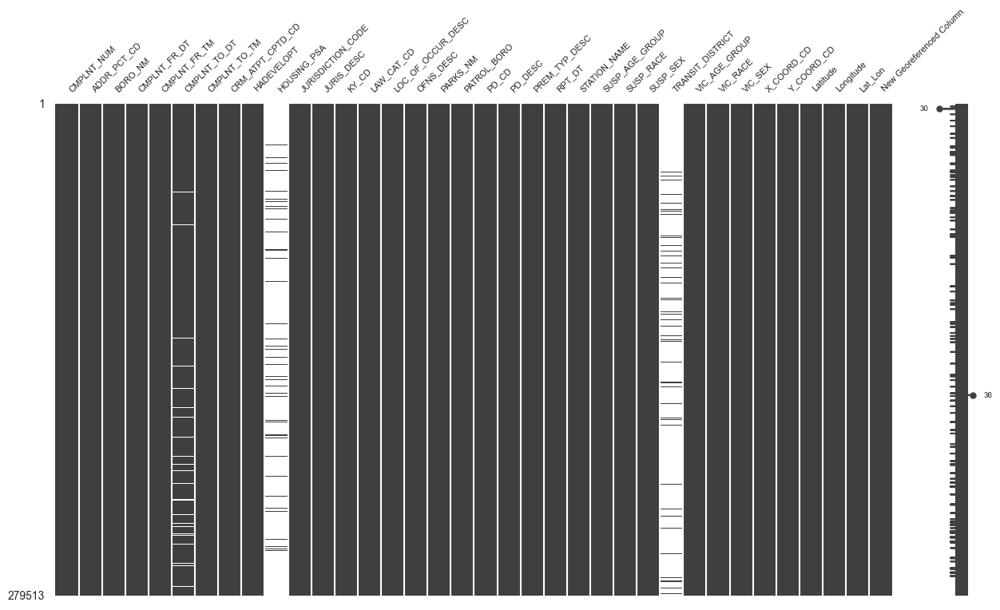

In [190]:
# Matriz de valores faltantes
msno.matrix(df_data, figsize=(15,8), fontsize=8)

Hay muchos valores nulos en HOUSING_PSA y en TRANSIT_DISTRICT

In [191]:
import pandas as pd

def resumen_valores_faltantes(df):
    resumen = []
    n_total = len(df)
    
    for col in df.columns:
        serie = df[col]
        n_nulos = serie.isna().sum()
        n_unique = df[col].nunique()
        
        if serie.dtype == object:
            str_lower = serie.astype(str).str.strip().str.lower()
            n_unknown = (str_lower == 'unknown').sum()
            n_null_str = (str_lower == '(null)').sum()
        else:
            n_unknown = 0
            n_null_str = 0
        
        total_especiales = n_nulos + n_unknown + n_null_str
        
        resumen.append({
            'columna': col,
            'NaN': n_nulos,
            'unknown': n_unknown,
            '(null)': n_null_str,
            'total_faltantes': total_especiales,
            'pct_faltantes': str(round(total_especiales / n_total * 100, 2)) + '%',
            'valores_distintos': n_unique
        })
    
    return pd.DataFrame(resumen)

# Uso:
df_resumen = resumen_valores_faltantes(df_data)
df_resumen[df_resumen['total_faltantes'] > 0]

,columna,NaN,unknown,(null),total_faltantes,pct_faltantes,valores_distintos
2,BORO_NM,0,0,786,786,0.28%,6
5,CMPLNT_TO_DT,10906,0,0,10906,3.9%,1127
6,CMPLNT_TO_TM,0,0,10770,10770,3.85%,1441
8,HADEVELOPT,0,0,278572,278572,99.66%,25
9,HOUSING_PSA,261207,0,0,261207,93.45%,333
14,LOC_OF_OCCUR_DESC,0,0,64180,64180,22.96%,6
15,OFNS_DESC,0,0,3,3,0.0%,55
16,PARKS_NM,0,0,278082,278082,99.49%,363
17,PATROL_BORO,0,0,1,1,0.0%,10
18,PD_CD,128,0,0,128,0.05%,356


- Casi la totalidad de los valores de HADEVELOPT, HOUSING_PSA, PARKS_NM, STATION_NAME y TRANSIT_DISTRICT son nulos. Por lo que se descartarán.
- Respecto de SUSP_AGE_GROUP, SUSP_RACE, SUSP_SEX, VIC_AGE_GROUP, VIC_RACE y VIC_SEX, tambien contienen un gran porcentaje de valores nulos.
- Respecto de LOC_OF_OCCUR_DESC, si bien tiene un porcentaje moderado de valores nulos (string null), no se descartará porque podría ser útil para el modelado. Describe la ubicación donde ocurrió el incidente dentro del sitio (inside, opposite of, front of, rear of)

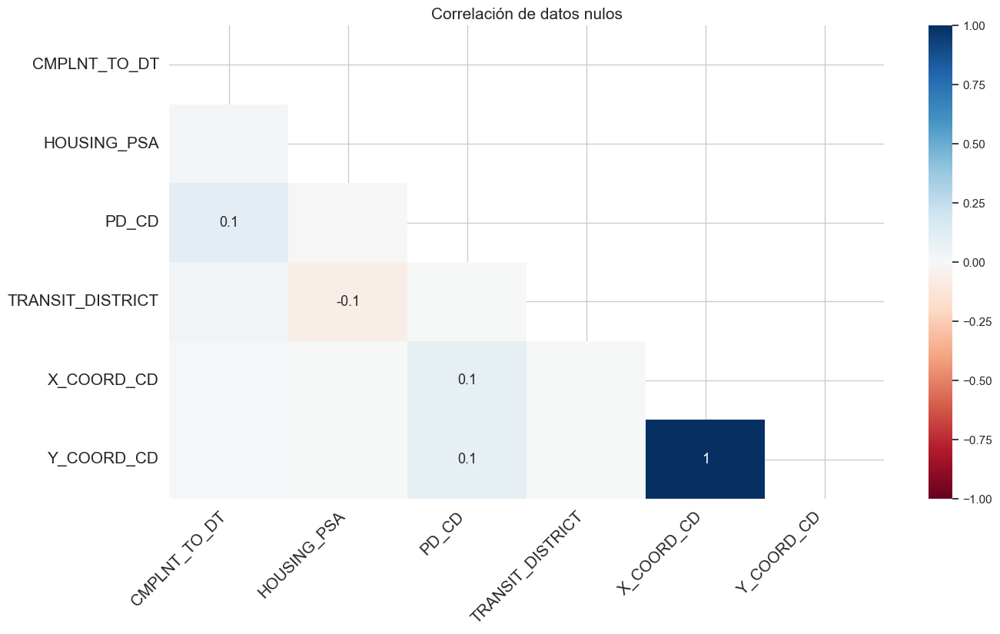

In [192]:
msno.heatmap(df_data, fontsize=15, figsize=(15,8), n=36)
plt.title("Correlación de datos nulos", fontsize=15)
plt.show()

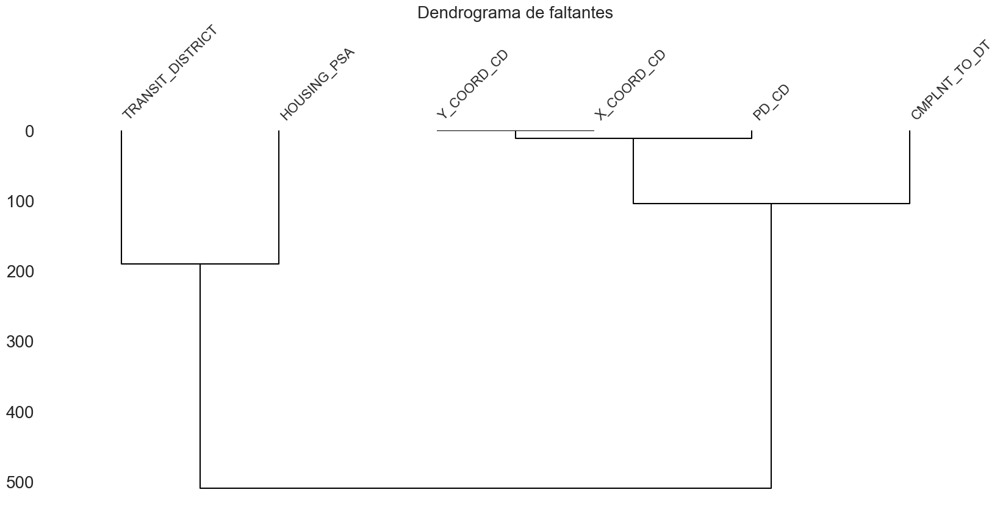

In [193]:
# Solo dibujamos columnas con nulos
cols_with_nulls = df_data.columns[df_data.isna().any()]
msno.dendrogram(df_data[cols_with_nulls], figsize=(20, 8))
plt.title('Dendrograma de faltantes', fontsize=20)
plt.show()

- Los faltantes de TRANSIT_DISTRICT y HOUSING_PSA, que son muchos (93.64% y 93.45% respectivamente), se parecen bastante basicamente porque cuando uno sea null el otro probablemente también lo sea.
- Luego los valores null en Y_COORD_CD y X_COORD_CD tiene sentido que esten juntos también, ya que son valores geográficos (similar a coordenadas pero en un plano), y si uno es null, el otro también.
- Notar que a pesar de que en Lat_Lon, New Georefenced Column, hay una linea marcada negra, no poseen valores null.
- Parece que puede haber alguna relación entre los nulls del item anterior con los de PD_CD pero hay 128 nulls en PD_CD frente a un solo null para Y_COORD_CD, X_COORD_CD. Así que es poco probable que haya algún tipo de relación directa.
- Es más difícil extraer algún tipo de conclusión entre CMPLNT_TO_DT y PD_CD, porque no hay relación cercana entre las columnas a nivel dendograma, y esto es porque el porcentaje de nulls es muy distinto: CMPLNT_TO_DT posee 3.9% de nulls y PD_CD 0.05%. 

Mas alla de todo esto, hay otros valores null que no se están incluyendo, que son los (null) string. Vamos a crear una copia del dataset donde los vamos a convertir a null y observar como cambia el dendograma.

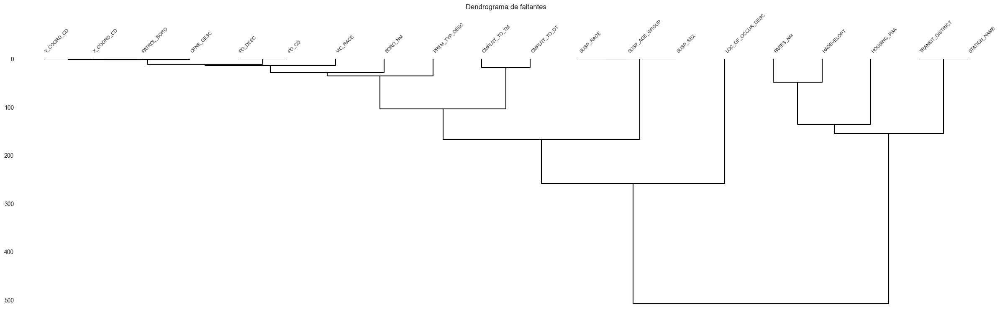

In [194]:
df_missing = df_data.copy()

null_markers = {'(null)'}

for col in df_missing.select_dtypes(include=['object', 'string']).columns:
    is_marker = (
        df_missing[col].astype('string').str.strip().str.casefold()
        .isin(null_markers)
    )
    df_missing[col] = df_missing[col].mask(is_marker)

# Solo dibujamos columnas con nulos
cols_with_nulls = df_missing.columns[df_missing.isna().any()]

msno.dendrogram(df_missing[cols_with_nulls], figsize=(30, 8), fontsize=8)
plt.title('Dendrograma de faltantes')
plt.show()

Ahora tenemos mucha mas información de valores faltantes.

Notar que no se incluyen los unknown, ya que ténicamente no son valores faltantes.

- Tiene sentido que sin codigo de delito policial PD_CD, PD_DESC no tenga valor.
- Hay 3 valores null en OFNS_DESC sin que KY_CD no sea null, la relacion de este último con el BORO_NM no es clara, ya que la cantidad de valores null de este último es mucho mayor (786)
- Tiene sentido que haya relación entre CMPLNT_TO_DT y CMPLNT_TO_TM. Si no hay uno, probablemente no esté completo el otro. Habrá que ver si es 1:1 aunque no tendria porque serlo necesariamente.
- Lo mismo sucede con SUSP_RACE, SUSP_SEX y SUSP_AGE_GROUP, ya que es información descriptiva de la victima y también, si uno no esta completo, probablemente los otros tampoco lo estén, aunque nuevamente, es probable que no sea 1:1:1
- PARKS_NM tiene 99.49% de valores null, HADEVELOPT tiene un 99.66%, y por eso aparecen relacionados. Son casi todos nulls así que casi siempre coincidirán. Su distancia a HOUSING_PSA tiene el mismo análisis momentaneamente.
- TRANSIT_DISTRICT, 93.64% de nulls, y STATION_NAME también 93.64%, es interesante, a pesar de ser valores altos, son exactamente el mismo porcentaje de nulls. Posiblemente siempre que uno es nulo el otro también. Que tipo de relación será?

-----

### Relacion de los valores faltantes

* MCAR: la falta del dato es aleatoria y no depende de ninguna variable.
* MAR: la falta del dato depende de otras variables observadas.
* MNAR: la falta del dato depende de del dato en sí mismo.
* Estructural: no es realmente un faltante, sino un dato que no existe.

In [195]:
def nulos_por_grupo(df, grupo_cols, target_col):
    agrupar_nulos = (
        df.groupby(grupo_cols, observed=True)[target_col]
        .apply(lambda x: x.isnull().mean() * 100)
        .reset_index(name=f'porcentaje_nulos_{target_col}')
    )
    return agrupar_nulos.sort_values(f'porcentaje_nulos_{target_col}', ascending=False)

### Analizamos los null en CMPLNT_TO_DT

In [196]:
nulos_cmplnt_to_dt_per_law_cat_cd = nulos_por_grupo(df_data, 'LAW_CAT_CD', 'CMPLNT_TO_DT')
nulos_cmplnt_to_dt_per_law_cat_cd = nulos_cmplnt_to_dt_per_law_cat_cd[nulos_cmplnt_to_dt_per_law_cat_cd['porcentaje_nulos_CMPLNT_TO_DT'] > 0]
print("Nulos en CMPLNT_TO_DT por LAW_CAT_CD:\n", nulos_cmplnt_to_dt_per_law_cat_cd, "\n")

Nulos en CMPLNT_TO_DT por LAW_CAT_CD:
     LAW_CAT_CD  porcentaje_nulos_CMPLNT_TO_DT
1  MISDEMEANOR                       4.373028
0       FELONY                       3.428058
2    VIOLATION                       3.311171 



- No parece haber relación directa con este nivel de granularidad

In [197]:
nulos_cmplnt_to_dt_per_boro = nulos_por_grupo(df_data, 'BORO_NM', 'CMPLNT_TO_DT')
nulos_cmplnt_to_dt_per_boro = nulos_cmplnt_to_dt_per_boro[nulos_cmplnt_to_dt_per_boro['porcentaje_nulos_CMPLNT_TO_DT'] > 0]
print("Nulos en CMPLNT_TO_DT por BORO_NM:\n", nulos_cmplnt_to_dt_per_boro, "\n")

Nulos en CMPLNT_TO_DT por BORO_NM:
          BORO_NM  porcentaje_nulos_CMPLNT_TO_DT
0         (null)                      70.229008
1          BRONX                      10.149930
5  STATEN ISLAND                       2.128250
2       BROOKLYN                       2.075558
4         QUEENS                       1.678861
3      MANHATTAN                       1.609539 



In [198]:
nulos_cmplnt_to_dt_per_boro_and_law_cat = nulos_por_grupo(df_data, ['LAW_CAT_CD', 'BORO_NM'], 'CMPLNT_TO_DT')
nulos_cmplnt_to_dt_per_boro_and_law_cat = nulos_cmplnt_to_dt_per_boro_and_law_cat[nulos_cmplnt_to_dt_per_boro_and_law_cat['porcentaje_nulos_CMPLNT_TO_DT'] > 0]
print("Nulos en CMPLNT_TO_DT por BORO_NM y LAW_CAT_CD:\n", nulos_cmplnt_to_dt_per_boro_and_law_cat, "\n")

Nulos en CMPLNT_TO_DT por BORO_NM y LAW_CAT_CD:
      LAW_CAT_CD        BORO_NM  porcentaje_nulos_CMPLNT_TO_DT
6   MISDEMEANOR         (null)                      70.512821
0        FELONY         (null)                      33.333333
12    VIOLATION          BRONX                      10.479407
7   MISDEMEANOR          BRONX                      10.323761
1        FELONY          BRONX                       9.699872
11  MISDEMEANOR  STATEN ISLAND                       2.677165
8   MISDEMEANOR       BROOKLYN                       2.659536
10  MISDEMEANOR         QUEENS                       2.102463
3        FELONY      MANHATTAN                       1.717750
9   MISDEMEANOR      MANHATTAN                       1.697616
5        FELONY  STATEN ISLAND                       1.680108
2        FELONY       BROOKLYN                       1.552098
4        FELONY         QUEENS                       1.343691
16    VIOLATION  STATEN ISLAND                       1.275992
13    VIOLATION      

In [199]:
def null_string_por_grupo(df, grupo_cols, target_col):
    agrupar_nulos = (
        df.groupby(grupo_cols, observed=True)[target_col]
        .apply(lambda x: (x == '(null)').mean() * 100)
        .reset_index(name=f'porcentaje_nulos_{target_col}')
    )
    return agrupar_nulos.sort_values(by=f'porcentaje_nulos_{target_col}', ascending=False)

-----

### Analizamos los string null en CMPLNT_TO_TM

In [200]:
nulos_cmplnt_to_per_law_cat = null_string_por_grupo(df_data, 'LAW_CAT_CD', 'CMPLNT_TO_TM')
nulos_cmplnt_to_per_law_cat = nulos_cmplnt_to_per_law_cat[nulos_cmplnt_to_per_law_cat['porcentaje_nulos_CMPLNT_TO_TM'] > 0]
print("Nulos en CMPLNT_TO_TM por LAW_CAT_CD:\n", nulos_cmplnt_to_per_law_cat, "\n")

Nulos en CMPLNT_TO_TM por LAW_CAT_CD:
     LAW_CAT_CD  porcentaje_nulos_CMPLNT_TO_TM
1  MISDEMEANOR                       4.329126
0       FELONY                       3.392835
2    VIOLATION                       3.221503 



In [201]:
nulos_cmplnt_to_per_boro = null_string_por_grupo(df_data, 'BORO_NM', 'CMPLNT_TO_TM')
nulos_cmplnt_to_per_boro = nulos_cmplnt_to_per_boro[nulos_cmplnt_to_per_boro['porcentaje_nulos_CMPLNT_TO_TM'] > 0]
print("Nulos en CMPLNT_TO_TM por BORO_NM:\n", nulos_cmplnt_to_per_boro, "\n")

Nulos en CMPLNT_TO_TM por BORO_NM:
          BORO_NM  porcentaje_nulos_CMPLNT_TO_TM
0         (null)                      70.229008
1          BRONX                      10.078685
5  STATEN ISLAND                       2.137503
2       BROOKLYN                       2.039602
4         QUEENS                       1.610371
3      MANHATTAN                       1.575293 



In [202]:
nulos_cmplnt_to_tm_per_boro_and_law_cat = null_string_por_grupo(df_data, ['LAW_CAT_CD', 'BORO_NM'], 'CMPLNT_TO_TM')
nulos_cmplnt_to_tm_per_boro_and_law_cat = nulos_cmplnt_to_tm_per_boro_and_law_cat[nulos_cmplnt_to_tm_per_boro_and_law_cat['porcentaje_nulos_CMPLNT_TO_TM'] > 0]
print("Nulos en CMPLNT_TO_TM por LAW_CAT_CD y BORO_NM:\n", nulos_cmplnt_to_tm_per_boro_and_law_cat, "\n")

Nulos en CMPLNT_TO_TM por LAW_CAT_CD y BORO_NM:
      LAW_CAT_CD        BORO_NM  porcentaje_nulos_CMPLNT_TO_TM
6   MISDEMEANOR         (null)                      70.512821
0        FELONY         (null)                      33.333333
12    VIOLATION          BRONX                      10.366826
7   MISDEMEANOR          BRONX                      10.283446
1        FELONY          BRONX                       9.601145
11  MISDEMEANOR  STATEN ISLAND                       2.729659
8   MISDEMEANOR       BROOKLYN                       2.621166
10  MISDEMEANOR         QUEENS                       2.031083
3        FELONY      MANHATTAN                       1.712938
5        FELONY  STATEN ISLAND                       1.680108
9   MISDEMEANOR      MANHATTAN                       1.651265
2        FELONY       BROOKLYN                       1.556108
4        FELONY         QUEENS                       1.285954
16    VIOLATION  STATEN ISLAND                       1.181474
13    VIOLATION      

- La mayoria de entradas sin ciudad de procedencia del delito son las que no tienen fecha y hora de compleción del mismo.
- Tambien se observa que Bronx tiene un 10% de delitos sin fecha y hora de compleción.

-----

### Analizamos los string null en OFNS_DESC

In [203]:
nulos_ofns_desc_per_ky_cd = null_string_por_grupo(df_data, 'KY_CD', 'OFNS_DESC')
nulos_ofns_desc_per_ky_cd = nulos_ofns_desc_per_ky_cd[nulos_ofns_desc_per_ky_cd['porcentaje_nulos_OFNS_DESC'] > 0]
print("Nulos en OFNS_DESC por KY_CD:\n", nulos_ofns_desc_per_ky_cd, "\n")

Nulos en OFNS_DESC por KY_CD:
     KY_CD  porcentaje_nulos_OFNS_DESC
53    363                    0.740741
23    126                    0.020775 



Que códigos son? con que descripción podemos completarlos?

-----

### Analizamos los string null en LOC_OF_OCCUR_DESC (fron, back, rear, etc)

In [204]:
nulos_loc_of_occur_per_law_cat = null_string_por_grupo(df_data, 'LAW_CAT_CD', 'LOC_OF_OCCUR_DESC')
nulos_loc_of_occur_per_law_cat = nulos_loc_of_occur_per_law_cat[nulos_loc_of_occur_per_law_cat['porcentaje_nulos_LOC_OF_OCCUR_DESC'] > 0]
print("Nulos en LOC_OF_OCCUR_DESC por LAW_CAT_CD:\n", nulos_loc_of_occur_per_law_cat, "\n")

Nulos en LOC_OF_OCCUR_DESC por LAW_CAT_CD:
     LAW_CAT_CD  porcentaje_nulos_LOC_OF_OCCUR_DESC
1  MISDEMEANOR                           28.092331
0       FELONY                           19.218489
2    VIOLATION                           13.806754 



In [205]:
nulos_loc_of_occur_per_boro = null_string_por_grupo(df_data, 'BORO_NM', 'LOC_OF_OCCUR_DESC')
nulos_loc_of_occur_per_boro = nulos_loc_of_occur_per_boro[nulos_loc_of_occur_per_boro['porcentaje_nulos_LOC_OF_OCCUR_DESC'] > 0]
print("Nulos en LOC_OF_OCCUR_DESC por BORO_NM:\n", nulos_loc_of_occur_per_boro, "\n")

Nulos en LOC_OF_OCCUR_DESC por BORO_NM:
          BORO_NM  porcentaje_nulos_LOC_OF_OCCUR_DESC
0         (null)                           99.109415
2       BROOKLYN                           25.841568
4         QUEENS                           22.436604
3      MANHATTAN                           21.725662
1          BRONX                           21.490430
5  STATEN ISLAND                           14.777459 



En particular, las entradas sin descripcion del lugar de ocurrencia del delito (fron, back, rear, etc.), no poseen una ciudad.

In [206]:
nulos_loc_of_occur_per_law_cat_and_boro = null_string_por_grupo(df_data, ['LAW_CAT_CD', 'BORO_NM'], 'LOC_OF_OCCUR_DESC')
nulos_loc_of_occur_per_law_cat_and_boro = nulos_loc_of_occur_per_law_cat_and_boro[nulos_loc_of_occur_per_law_cat_and_boro['porcentaje_nulos_LOC_OF_OCCUR_DESC'] > 0]
print("Nulos en LOC_OF_OCCUR_DESC por LAW_CAT_CD y BORO_NM:\n", nulos_loc_of_occur_per_law_cat_and_boro, "\n")

Nulos en LOC_OF_OCCUR_DESC por LAW_CAT_CD y BORO_NM:
      LAW_CAT_CD        BORO_NM  porcentaje_nulos_LOC_OF_OCCUR_DESC
6   MISDEMEANOR         (null)                           99.358974
0        FELONY         (null)                           66.666667
8   MISDEMEANOR       BROOKLYN                           31.919231
7   MISDEMEANOR          BRONX                           27.560007
10  MISDEMEANOR         QUEENS                           26.751241
9   MISDEMEANOR      MANHATTAN                           24.957270
2        FELONY       BROOKLYN                           20.117109
3        FELONY      MANHATTAN                           19.814271
11  MISDEMEANOR  STATEN ISLAND                           19.615048
4        FELONY         QUEENS                           19.362797
1        FELONY          BRONX                           18.496396
13    VIOLATION       BROOKLYN                           17.945792
15    VIOLATION         QUEENS                           14.986485
14    VI

In [207]:
nulos_loc_of_occur_per_law_cat = null_string_por_grupo(df_data, ['LAW_CAT_CD', 'KY_CD', 'OFNS_DESC'], 'LOC_OF_OCCUR_DESC')
nulos_loc_of_occur_per_law_cat = nulos_loc_of_occur_per_law_cat[nulos_loc_of_occur_per_law_cat['porcentaje_nulos_LOC_OF_OCCUR_DESC'] > 50]
print("Nulos en LOC_OF_OCCUR_DESC por LAW_CAT_CD y KY_CD:\n", nulos_loc_of_occur_per_law_cat, "\n")

Nulos en LOC_OF_OCCUR_DESC por LAW_CAT_CD y KY_CD:
      LAW_CAT_CD  KY_CD                        OFNS_DESC  \
1        FELONY    102       HOMICIDE-NEGLIGENT-VEHICLE   
67    VIOLATION    675              ADMINISTRATIVE CODE   
41  MISDEMEANOR    343  OTHER OFFENSES RELATED TO THEFT   
17       FELONY    119     INTOXICATED/IMPAIRED DRIVING   
58  MISDEMEANOR    363   OFFENSES AGAINST PUBLIC SAFETY   
36  MISDEMEANOR    238             FRAUDULENT ACCOSTING   
27  MISDEMEANOR    125                 OTHER STATE LAWS   
46  MISDEMEANOR    348         VEHICLE AND TRAFFIC LAWS   
45  MISDEMEANOR    347   INTOXICATED & IMPAIRED DRIVING   
54  MISDEMEANOR    358         OFFENSES INVOLVING FRAUD   
69    VIOLATION    677                 OTHER STATE LAWS   
22       FELONY    125                 OTHER STATE LAWS   
68    VIOLATION    676        NEW YORK CITY HEALTH CODE   
28  MISDEMEANOR    230                         JOSTLING   
11       FELONY    113                          FORGERY   
33  

In [208]:
nulos_loc_of_occur_per_law_cat = null_string_por_grupo(df_data, ['LAW_CAT_CD', 'PD_CD', 'PD_DESC'], 'LOC_OF_OCCUR_DESC')
nulos_loc_of_occur_per_law_cat = nulos_loc_of_occur_per_law_cat[nulos_loc_of_occur_per_law_cat['porcentaje_nulos_LOC_OF_OCCUR_DESC'] > 50]
print("Nulos en LOC_OF_OCCUR_DESC por LAW_CAT_CD, OFNS_DESC y PD_DESC:\n", nulos_loc_of_occur_per_law_cat, "\n")

Nulos en LOC_OF_OCCUR_DESC por LAW_CAT_CD, OFNS_DESC y PD_DESC:
       LAW_CAT_CD  PD_CD                                            PD_DESC  \
313  MISDEMEANOR  822.0                                      EDUCATION LAW   
290  MISDEMEANOR  706.0                             RECORDS,FALSIFY-TAMPER   
254  MISDEMEANOR  475.0                     UNAUTH. SALE OF TRANS. SERVICE   
353    VIOLATION  890.0                           N.Y.C. TRANSIT AUTH. R&R   
160       FELONY  561.0                     PROSTITUTION, PATRONIZING 2, 1   
329    VIOLATION  275.0                             POSTING ADVERTISEMENTS   
13        FELONY  122.0                      HOMICIDE, NEGLIGENT, VEHICLE,   
340    VIOLATION  754.0                     APPEARANCE TICKET FAIL TO RESP   
188       FELONY  727.0                               FORGERY,PRESCRIPTION   
255  MISDEMEANOR  478.0                     THEFT OF SERVICES, UNCLASSIFIE   
323  MISDEMEANOR  907.0                              IMPAIRED DRIVING,DRUG   

In [209]:
nulos_loc_of_occur_per_law_cat = null_string_por_grupo(df_data, ['LAW_CAT_CD', 'KY_CD', 'OFNS_DESC', 'PD_CD', 'PD_DESC'], 'LOC_OF_OCCUR_DESC')
nulos_loc_of_occur_per_law_cat = nulos_loc_of_occur_per_law_cat[nulos_loc_of_occur_per_law_cat['porcentaje_nulos_LOC_OF_OCCUR_DESC'] > 50]
print("Nulos en LOC_OF_OCCUR_DESC por LAW_CAT_CD, OFNS_DESC y PD_DESC:\n", nulos_loc_of_occur_per_law_cat, "\n")

Nulos en LOC_OF_OCCUR_DESC por LAW_CAT_CD, OFNS_DESC y PD_DESC:
       LAW_CAT_CD  KY_CD                        OFNS_DESC  PD_CD  \
0         FELONY    102       HOMICIDE-NEGLIGENT-VEHICLE  122.0   
110       FELONY    113                          FORGERY  727.0   
300  MISDEMEANOR    358         OFFENSES INVOLVING FRAUD  706.0   
271  MISDEMEANOR    345     OFFENSES RELATED TO CHILDREN  822.0   
343    VIOLATION    675              ADMINISTRATIVE CODE  890.0   
261  MISDEMEANOR    343  OTHER OFFENSES RELATED TO THEFT  475.0   
351    VIOLATION    678          MISCELLANEOUS PENAL LAW  275.0   
355    VIOLATION    678          MISCELLANEOUS PENAL LAW  754.0   
115       FELONY    115  PROSTITUTION & RELATED OFFENSES  561.0   
262  MISDEMEANOR    343  OTHER OFFENSES RELATED TO THEFT  478.0   
275  MISDEMEANOR    347   INTOXICATED & IMPAIRED DRIVING  907.0   
62        FELONY    109                    GRAND LARCENY  408.0   
263  MISDEMEANOR    343  OTHER OFFENSES RELATED TO THEFT  479.0 

- Parece que LOC_OF_OCCUR_DESC cumple con MAR
- No se puede determinar front, back o rear of si el delito sucede, mayormente, en la calle

-----

### Analizamos los string null en PREM_TYP_DESC (street, home, etc)

In [210]:
nulos_place_desc_per_law_cat = null_string_por_grupo(df_data, 'LAW_CAT_CD', 'PREM_TYP_DESC')
nulos_place_desc_per_law_cat = nulos_place_desc_per_law_cat[nulos_place_desc_per_law_cat['porcentaje_nulos_PREM_TYP_DESC'] > 0]
print("Nulos en PREM_TYP_DESC por LAW_CAT_CD:\n", nulos_place_desc_per_law_cat, "\n")

Nulos en PREM_TYP_DESC por LAW_CAT_CD:
     LAW_CAT_CD  porcentaje_nulos_PREM_TYP_DESC
0       FELONY                        0.668113
1  MISDEMEANOR                        0.333379
2    VIOLATION                        0.144344 



In [211]:
nulos_place_desc_per_boro = null_string_por_grupo(df_data, 'BORO_NM', 'PREM_TYP_DESC')
nulos_place_desc_per_boro = nulos_place_desc_per_boro[nulos_place_desc_per_boro['porcentaje_nulos_PREM_TYP_DESC'] > 0]
print("Nulos en PREM_TYP_DESC por BORO_NM:\n", nulos_place_desc_per_boro, "\n")

Nulos en PREM_TYP_DESC por BORO_NM:
          BORO_NM  porcentaje_nulos_PREM_TYP_DESC
3      MANHATTAN                        0.628872
1          BRONX                        0.614284
4         QUEENS                        0.242224
2       BROOKLYN                        0.236817
5  STATEN ISLAND                        0.111039 



- En Bronx y Manhattan, felony es la categoria de delito con mas faltantes en la descripción del lugar del hecho.
- Si hay descripción del lugar, hay ciudad!

In [212]:
nulos_place_desc_per_law_cat_and_boro = null_string_por_grupo(df_data, ['LAW_CAT_CD', 'BORO_NM'], 'PREM_TYP_DESC')
nulos_place_desc_per_law_cat_and_boro = nulos_place_desc_per_law_cat_and_boro[nulos_place_desc_per_law_cat_and_boro['porcentaje_nulos_PREM_TYP_DESC'] > 0]
print("Nulos en PREM_TYP_DESC por LAW_CAT_CD y BORO_NM:\n", nulos_place_desc_per_law_cat_and_boro, "\n")

Nulos en PREM_TYP_DESC por LAW_CAT_CD y BORO_NM:
      LAW_CAT_CD        BORO_NM  porcentaje_nulos_PREM_TYP_DESC
1        FELONY          BRONX                        1.174845
9   MISDEMEANOR      MANHATTAN                        0.701063
3        FELONY      MANHATTAN                        0.664004
2        FELONY       BROOKLYN                        0.505334
7   MISDEMEANOR          BRONX                        0.437264
4        FELONY         QUEENS                        0.414655
14    VIOLATION      MANHATTAN                        0.268456
5        FELONY  STATEN ISLAND                        0.235215
15    VIOLATION         QUEENS                        0.190209
10  MISDEMEANOR         QUEENS                        0.152493
16    VIOLATION  STATEN ISLAND                        0.141777
8   MISDEMEANOR       BROOKLYN                        0.129500
12    VIOLATION          BRONX                        0.084436
13    VIOLATION       BROOKLYN                        0.078459
11  M

Parece haber una relacion entre los nulls del lugar de descripcion y la gravedad del delito

In [213]:
nulos_place_desc_per_law_cat = null_string_por_grupo(df_data, ['LAW_CAT_CD', 'KY_CD', 'OFNS_DESC'], 'PREM_TYP_DESC')
nulos_place_desc_per_law_cat = nulos_place_desc_per_law_cat[nulos_place_desc_per_law_cat['porcentaje_nulos_PREM_TYP_DESC'] > 1]
print("Nulos en PREM_TYP_DESC por LAW_CAT_CD y OFNS_DESC:\n", nulos_place_desc_per_law_cat, "\n")

Nulos en PREM_TYP_DESC por LAW_CAT_CD y OFNS_DESC:
      LAW_CAT_CD  KY_CD                        OFNS_DESC  \
0        FELONY    101  MURDER & NON-NEGL. MANSLAUGHTER   
20       FELONY    122                         GAMBLING   
55  MISDEMEANOR    359   OFFENSES AGAINST PUBLIC ADMINI   
21       FELONY    124    KIDNAPPING & RELATED OFFENSES   
38  MISDEMEANOR    340                           FRAUDS   
5        FELONY    106                   FELONY ASSAULT   
24       FELONY    126          MISCELLANEOUS PENAL LAW   
69    VIOLATION    677                 OTHER STATE LAWS   

    porcentaje_nulos_PREM_TYP_DESC  
0                        60.156250  
20                        4.081633  
55                        2.643343  
21                        2.597403  
38                        1.610018  
5                         1.472774  
24                        1.329870  
69                        1.075269   



In [214]:
nulos_place_desc_per_law_cat = null_string_por_grupo(df_data, ['LAW_CAT_CD', 'PD_CD', 'PD_DESC'], 'PREM_TYP_DESC')
nulos_place_desc_per_law_cat = nulos_place_desc_per_law_cat[nulos_place_desc_per_law_cat['porcentaje_nulos_PREM_TYP_DESC'] > 1]
print("Nulos en PREM_TYP_DESC por LAW_CAT_CD y PD_CD:\n", nulos_place_desc_per_law_cat, "\n")

Nulos en PREM_TYP_DESC por LAW_CAT_CD y PD_CD:
       LAW_CAT_CD  PD_CD                                            PD_DESC  \
188       FELONY  727.0                               FORGERY,PRESCRIPTION   
198       FELONY  779.0                     PUBLIC ADMINISTRATION,UNCLASSI   
193       FELONY  762.0                                         ESCAPE 2,1   
57        FELONY  293.0                                    CONSPIRACY 2, 1   
213  MISDEMEANOR  174.0                          SEXUAL MISCONDUCT,DEVIATE   
27        FELONY  186.0                                     LURING A CHILD   
5         FELONY  106.0                       ASSAULT POLICE/PEACE OFFICER   
170       FELONY  640.0                            AGGRAVATED HARASSMENT 1   
29        FELONY  193.0                           CUSTODIAL INTERFERENCE 1   
208  MISDEMEANOR  111.0                             MENACING,PEACE OFFICER   
171       FELONY  644.0                                FALSE REPORT 1,FIRE   
159       FELONY

In [215]:
nulos_place_desc_per_law_cat = null_string_por_grupo(df_data, ['LAW_CAT_CD', 'KY_CD', 'OFNS_DESC', 'PD_CD', 'PD_DESC'], 'PREM_TYP_DESC')
nulos_place_desc_per_law_cat = nulos_place_desc_per_law_cat[nulos_place_desc_per_law_cat['porcentaje_nulos_PREM_TYP_DESC'] > 1]
print("Nulos en PREM_TYP_DESC por LAW_CAT_CD, KY_CD y PD_CD:\n", nulos_place_desc_per_law_cat, "\n")

Nulos en PREM_TYP_DESC por LAW_CAT_CD, KY_CD y PD_CD:
       LAW_CAT_CD  KY_CD                       OFNS_DESC  PD_CD  \
110       FELONY    113                         FORGERY  727.0   
203       FELONY    126         MISCELLANEOUS PENAL LAW  779.0   
200       FELONY    126         MISCELLANEOUS PENAL LAW  762.0   
182       FELONY    126         MISCELLANEOUS PENAL LAW  293.0   
216  MISDEMEANOR    233                      SEX CRIMES  174.0   
163       FELONY    124   KIDNAPPING & RELATED OFFENSES  186.0   
40        FELONY    106                  FELONY ASSAULT  106.0   
185       FELONY    126         MISCELLANEOUS PENAL LAW  640.0   
165       FELONY    124   KIDNAPPING & RELATED OFFENSES  193.0   
265  MISDEMEANOR    344    ASSAULT 3 & RELATED OFFENSES  111.0   
160       FELONY    122                        GAMBLING  557.0   
186       FELONY    126         MISCELLANEOUS PENAL LAW  644.0   
305  MISDEMEANOR    359  OFFENSES AGAINST PUBLIC ADMINI  759.0   
201       FELONY    1


-----

### Analizamos PD_DESC respecto de LAW_CAT_CD y KY_CD

In [216]:
nulos_pd_desc_per_law_cat = null_string_por_grupo(df_data, ['LAW_CAT_CD', 'KY_CD', 'OFNS_DESC'], 'PD_DESC')
nulos_pd_desc_per_law_cat = nulos_pd_desc_per_law_cat[nulos_pd_desc_per_law_cat['porcentaje_nulos_PD_DESC'] > 1]
print("Nulos en PD_DESC por LAW_CAT_CD y KY_CD:\n", nulos_pd_desc_per_law_cat, "\n")

Nulos en PD_DESC por LAW_CAT_CD y KY_CD:
   LAW_CAT_CD  KY_CD                        OFNS_DESC  porcentaje_nulos_PD_DESC
0     FELONY    101  MURDER & NON-NEGL. MANSLAUGHTER                     100.0 



In [217]:
nulos_pd_cd_per_law_cat = nulos_por_grupo(df_data, ['LAW_CAT_CD', 'PD_DESC'], 'PD_CD')
nulos_pd_cd_per_law_cat = nulos_pd_cd_per_law_cat[nulos_pd_cd_per_law_cat['porcentaje_nulos_PD_CD'] > 0]
print("Nulos en PD_CD por LAW_CAT_CD:\n", nulos_pd_cd_per_law_cat, "\n")

Nulos en PD_CD por LAW_CAT_CD:
   LAW_CAT_CD PD_DESC  porcentaje_nulos_PD_CD
0     FELONY  (null)                   100.0 



-----

### Analizamos OFNS_DESC respecto de LAW_CAT_CD y KY_CD

In [218]:
nulos_ofns_desc_per_law_cat = null_string_por_grupo(df_data, ['LAW_CAT_CD', 'KY_CD'], 'OFNS_DESC')
nulos_ofns_desc_per_law_cat = nulos_ofns_desc_per_law_cat[nulos_ofns_desc_per_law_cat['porcentaje_nulos_OFNS_DESC'] > 1]
print("Nulos en OFNS_DESC por LAW_CAT_CD y PD_CD:\n", nulos_ofns_desc_per_law_cat, "\n")

Nulos en OFNS_DESC por LAW_CAT_CD y PD_CD:
 Empty DataFrame
Columns: [LAW_CAT_CD, KY_CD, porcentaje_nulos_OFNS_DESC]
Index: [] 



-----

### Analizamos los string null en PD_CD

In [219]:
nulos_pd_cd_per_law_cat = nulos_por_grupo(df_data, 'LAW_CAT_CD', 'PD_CD')
nulos_pd_cd_per_law_cat = nulos_pd_cd_per_law_cat[nulos_pd_cd_per_law_cat['porcentaje_nulos_PD_CD'] > 0]
print("Nulos en PD_CD por LAW_CAT_CD:\n", nulos_pd_cd_per_law_cat, "\n")

Nulos en PD_CD por LAW_CAT_CD:
   LAW_CAT_CD  porcentaje_nulos_PD_CD
0     FELONY                 0.14544 



In [220]:
nulos_pd_cd_per_pd_desc = nulos_por_grupo(df_data, 'PD_DESC', 'PD_CD')
nulos_pd_cd_per_pd_desc = nulos_pd_cd_per_pd_desc[nulos_pd_cd_per_pd_desc['porcentaje_nulos_PD_CD'] > 0]
print("Nulos en PD_CD por PD_DESC:\n", nulos_pd_cd_per_pd_desc, "\n")

Nulos en PD_CD por PD_DESC:
   PD_DESC  porcentaje_nulos_PD_CD
0  (null)                   100.0 



In [221]:
nulos_pd_desc_per_pd_cd = null_string_por_grupo(df_data, 'PD_CD', 'PD_DESC')
nulos_pd_desc_per_pd_cd = nulos_pd_desc_per_pd_cd[nulos_pd_desc_per_pd_cd['porcentaje_nulos_PD_DESC'] > 0]
print("Nulos en PD_DESC por PD_CD:\n", nulos_pd_desc_per_pd_cd, "\n")

Nulos en PD_DESC por PD_CD:
 Empty DataFrame
Columns: [PD_CD, porcentaje_nulos_PD_DESC]
Index: [] 



Relación simétrica de nulos entre código policial de delito y su descripción, como era esperado.

Solo Felony tiene un 14.5% de sus entradas sin un codigo de delito policial.

### Analizamos los string null en TRANSIT_DISTRICT

In [222]:
nulos_ofns_desc_per_transit_district = nulos_por_grupo(df_data, ['LAW_CAT_CD'], 'TRANSIT_DISTRICT')
nulos_ofns_desc_per_transit_district = nulos_ofns_desc_per_transit_district[nulos_ofns_desc_per_transit_district['porcentaje_nulos_TRANSIT_DISTRICT'] > 1]
print("Nulos en TRANSIT_DISTRICT por LAW_CAT_CD:\n", nulos_ofns_desc_per_transit_district, "\n")

Nulos en TRANSIT_DISTRICT por LAW_CAT_CD:
     LAW_CAT_CD  porcentaje_nulos_TRANSIT_DISTRICT
0       FELONY                          97.168471
2    VIOLATION                          94.337766
1  MISDEMEANOR                          91.294416 



In [223]:
nulos_ofns_desc_per_transit_district = nulos_por_grupo(df_data, ['KY_CD', 'OFNS_DESC'], 'TRANSIT_DISTRICT')
nulos_ofns_desc_per_transit_district = nulos_ofns_desc_per_transit_district[nulos_ofns_desc_per_transit_district['porcentaje_nulos_TRANSIT_DISTRICT'] > 1]
print("Nulos en TRANSIT_DISTRICT por KY_CD:\n", nulos_ofns_desc_per_transit_district, "\n")

Nulos en TRANSIT_DISTRICT por KY_CD:
     KY_CD                        OFNS_DESC  porcentaje_nulos_TRANSIT_DISTRICT
0     101  MURDER & NON-NEGL. MANSLAUGHTER                         100.000000
44    350                         GAMBLING                         100.000000
23    126                           (null)                         100.000000
29    234  PROSTITUTION & RELATED OFFENSES                         100.000000
1     102       HOMICIDE-NEGLIGENT-VEHICLE                         100.000000
..    ...                              ...                                ...
35    340                           FRAUDS                          75.193798
30    235                  DANGEROUS DRUGS                          71.961890
25    230                         JOSTLING                          60.000000
38    343  OTHER OFFENSES RELATED TO THEFT                          13.421019
63    675              ADMINISTRATIVE CODE                           5.925206

[68 rows x 3 columns] 



-----

### Analizamos los string null en STATION_NAME

In [224]:
nulos_ofns_desc_per_station_name = null_string_por_grupo(df_data, ['LAW_CAT_CD'], 'STATION_NAME')
nulos_ofns_desc_per_station_name = nulos_ofns_desc_per_station_name[nulos_ofns_desc_per_station_name['porcentaje_nulos_STATION_NAME'] > 1]
print("Nulos en STATION_NAME por LAW_CAT_CD:\n", nulos_ofns_desc_per_station_name, "\n")

Nulos en STATION_NAME por LAW_CAT_CD:
     LAW_CAT_CD  porcentaje_nulos_STATION_NAME
0       FELONY                      97.168471
2    VIOLATION                      94.337766
1  MISDEMEANOR                      91.294416 



In [225]:
nulos_ofns_desc_per_station_name = null_string_por_grupo(df_data, ['KY_CD', 'OFNS_DESC'], 'STATION_NAME')
nulos_ofns_desc_per_station_name = nulos_ofns_desc_per_station_name[nulos_ofns_desc_per_station_name['porcentaje_nulos_STATION_NAME'] > 1]
print("Nulos en STATION_NAME por KY_CD:\n", nulos_ofns_desc_per_station_name, "\n")

Nulos en STATION_NAME por KY_CD:
     KY_CD                        OFNS_DESC  porcentaje_nulos_STATION_NAME
0     101  MURDER & NON-NEGL. MANSLAUGHTER                     100.000000
44    350                         GAMBLING                     100.000000
23    126                           (null)                     100.000000
29    234  PROSTITUTION & RELATED OFFENSES                     100.000000
1     102       HOMICIDE-NEGLIGENT-VEHICLE                     100.000000
..    ...                              ...                            ...
35    340                           FRAUDS                      75.193798
30    235                  DANGEROUS DRUGS                      71.961890
25    230                         JOSTLING                      60.000000
38    343  OTHER OFFENSES RELATED TO THEFT                      13.421019
63    675              ADMINISTRATIVE CODE                       5.925206

[68 rows x 3 columns] 



Parece seguir la misma distribución de nulos que TRANSIT_DISTRICT

In [226]:
# Calculamos cuales son null en transit district, lo que da un Series de False y True
transit_null = df_data['TRANSIT_DISTRICT'].isna()
# Lo mismo pero con (null) para station
station_null = (
    df_data['STATION_NAME']
    .astype('string')
    .str.strip()
    .str.casefold()
    .eq('(null)')
    .fillna(False)
)
# Generamos una tabla de contingencia entre ambas Series
coincidencia = pd.crosstab(
    transit_null.rename('TRANSIT_DISTRICT = NaN'),
    station_null.rename("STATION_NAME = '(null)'")
)
display(coincidencia)
# Numericamente mostramos las coincidencias en porcentaje y el numero de filas discordantes
discordantes = transit_null.ne(station_null)
print(f"Coincidencia: {(~discordantes).mean():.1%}")
print(f"Filas discordantes: {discordantes.sum():,}")

STATION_NAME = '(null)',False,True
TRANSIT_DISTRICT = NaN,,
False,17772,0
True,0,261741


Coincidencia: 100.0%
Filas discordantes: 0


La conclusion es que si uno no esta, el otro tampoco. Ahora la pregunta es, porque?

La razon puede ser estructural: 
  - TRANSIT_DISTRICT (Exclusivo del metro): Este campo corresponde únicamente a las divisiones de la Oficina de Tránsito del NYPD (NYPD Transit Bureau), cuya jurisdicción es el sistema de trenes subterráneos (el metro de la MTA). Si un delito ocurre en un autobús o en un tren regional externo, este campo suele quedar vacío.
  - STATION_NAME (Metro y trenes de cercanías): Aunque la gran mayoría de los registros corresponden a estaciones del metro subterráneo, esta columna también incluye estaciones de trenes de cercanías o regionales dentro de la ciudad (como Penn Station o Grand Central), además de paradas elevadas de la red del metro.

Así que para que contengan valores, el delito tiene que haber sucedido en una estación de tren o metro.

Veamos cuales si tienen valor:

In [227]:
def not_null_string_por_grupo(df, grupo_cols, target_col):
    agrupar_no_nulos = (
        df.groupby(grupo_cols, observed=True)[target_col]
        .apply(lambda x: (x != '(null)').mean() * 100)
        .reset_index(name=f'porcentaje_no_nulos_{target_col}')
    )
    return agrupar_no_nulos.sort_values(by=f'porcentaje_no_nulos_{target_col}', ascending=False)

In [228]:
not_nulos_ofns_desc_per_station_name = not_null_string_por_grupo(df_data, ['KY_CD', 'OFNS_DESC'], 'STATION_NAME')
not_nulos_ofns_desc_per_station_name = not_nulos_ofns_desc_per_station_name[not_nulos_ofns_desc_per_station_name['porcentaje_no_nulos_STATION_NAME'] > 0]
print("No nulos en STATION_NAME por KY_CD:\n", not_nulos_ofns_desc_per_station_name, "\n")

No nulos en STATION_NAME por KY_CD:
     KY_CD                         OFNS_DESC  porcentaje_no_nulos_STATION_NAME
63    675               ADMINISTRATIVE CODE                         94.074794
38    343   OTHER OFFENSES RELATED TO THEFT                         86.578981
25    230                          JOSTLING                         40.000000
30    235                   DANGEROUS DRUGS                         28.038110
35    340                            FRAUDS                         24.806202
61    572                DISORDERLY CONDUCT                         23.809524
46    352                 CRIMINAL TRESPASS                         20.411523
64    676         NEW YORK CITY HEALTH CODE                         20.000000
52    359    OFFENSES AGAINST PUBLIC ADMINI                         19.708455
31    236                 DANGEROUS WEAPONS                         17.713004
65    677                  OTHER STATE LAWS                         16.129032
16    118                 D

In [229]:
def no_nulos_por_grupo(df, grupo_cols, target_col):
    agrupar_no_nulos = (
        df.groupby(grupo_cols, observed=True)[target_col]
        .apply(lambda x: (x.notnull()).mean() * 100)
        .reset_index(name=f'porcentaje_no_nulos_{target_col}')
    )
    return agrupar_no_nulos.sort_values(f'porcentaje_no_nulos_{target_col}', ascending=False)

In [230]:
no_nulos_ofns_desc_per_transit_district = no_nulos_por_grupo(df_data, ['KY_CD', 'OFNS_DESC'], 'TRANSIT_DISTRICT')
no_nulos_ofns_desc_per_transit_district = no_nulos_ofns_desc_per_transit_district[no_nulos_ofns_desc_per_transit_district['porcentaje_no_nulos_TRANSIT_DISTRICT'] > 0]
print("No nulos en TRANSIT_DISTRICT por KY_CD y OFNS_DESC:\n", no_nulos_ofns_desc_per_transit_district, "\n")

No nulos en TRANSIT_DISTRICT por KY_CD y OFNS_DESC:
     KY_CD                         OFNS_DESC  \
63    675               ADMINISTRATIVE CODE   
38    343   OTHER OFFENSES RELATED TO THEFT   
25    230                          JOSTLING   
30    235                   DANGEROUS DRUGS   
35    340                            FRAUDS   
61    572                DISORDERLY CONDUCT   
46    352                 CRIMINAL TRESPASS   
64    676         NEW YORK CITY HEALTH CODE   
52    359    OFFENSES AGAINST PUBLIC ADMINI   
31    236                 DANGEROUS WEAPONS   
65    677                  OTHER STATE LAWS   
16    118                 DANGEROUS WEAPONS   
32    237                          ESCAPE 3   
26    231                   BURGLAR'S TOOLS   
49    355       OFFENSES AGAINST THE PERSON   
33    238              FRAUDULENT ACCOSTING   
66    678           MISCELLANEOUS PENAL LAW   
15    117                   DANGEROUS DRUGS   
11    113                           FORGERY   
40    3

-----

### Analizamos los valores poblacionales nulos y especiales de suspect y victim age, sex y race

Al ser categoricas y poseer cateogrias finitas, podemos hacer dos crosstab, uno para victim y otro para suspect

Para el sospechoso:

In [231]:
susp = (
    df_data[['SUSP_RACE', 'SUSP_AGE_GROUP', 'SUSP_SEX']]
    .astype('string')
    .fillna('UNKNOWN')
)

coincidencias_susp = pd.crosstab(
    index=[susp['SUSP_RACE'], susp['SUSP_AGE_GROUP']],
    columns=susp['SUSP_SEX'],
    rownames=['Raza del sospechoso', 'Grupo etario'],
    colnames=['Sexo del sospechoso']
)

display(coincidencias_susp)

Sexo del sospechoso                          (null)     F      M      U
Raza del sospechoso            Grupo etario                            
(null)                         (null)         26730     0      0      0
AMERICAN INDIAN/ALASKAN NATIVE 18-24              0     4     60      2
                               25-44              0    59    301      2
                               45-64              0    20     91      3
                               65+                0     1     24      0
                               <18                0     2     15      0
                               UNKNOWN            0    29    101      8
ASIAN / PACIFIC ISLANDER       -953               0     0      1      0
                               18-24              0   203    985      7
                               25-44              0   859   3944     49
                               45-64              0   477   1537     21
                               65+                0   121    292      4
                               <18                0    53    242      4
                               UNKNOWN            0   338   1191    123
BLACK                          -52                0     0      1      0
                               -63                0     0      1      0
                               -957               0     0      1      0
                               -963               0     0      1      0
                               18-24              0  2360   7039    127
                               2026               0     0      2      0
                               25-44              0  8997  31395    524
                               45-64              0  3015  12297    145
                               65+                0   432   1444     21
                               <18                0   995   1943     86
                               UNKNOWN            0  4215  12561   1450
BLACK HISPANIC                 18-24              0   396   1640     24
                               25-44              0  1369   6470     96
                               45-64              0   404   1856     27
                               65+                0    47    166      2
                               <18                0   175    378     23
                               UNKNOWN            0   419   1578    223
UNKNOWN                        -3                 0     0      1      0
                               18-24              0   248    508     74
                               2026               0     0      1      1
                               25-44              0   930   2318    328
                               45-64              0   286    795    118
                               65+                0    56    131     26
                               964                0     0      1      0
                               <18                0   147    316     76
                               UNKNOWN            0  3651  10979  53201
WHITE                          -1                 0     0      1      0
                               1022               0     0      1      0
                               18-24              0   326   1115     22
                               25-44              0  2193   6457    102
                               45-64              0  1090   3649     72
                               65+                0   258    676     16
                               <18                0   110    340     11
                               UNKNOWN            0  1041   3482    383
WHITE HISPANIC                 -3                 0     0      1      0
                               -962               0     1      0      0
                               1016               0     0      1      0
                               18-24              0  1228   4003     62
                               2026               0     1      0      0
                               25-44    

Elegimos SUSP_RACE porque los nulos siguen la misma distribución en las 3 variables, y observamos para la gravedad del delito y el codigo del delito como es la distribución de los nulos.

In [232]:
nulos_susp_race_per_law_cat = null_string_por_grupo(df_data, ['LAW_CAT_CD'], 'SUSP_RACE')
nulos_susp_race_per_law_cat = nulos_susp_race_per_law_cat[nulos_susp_race_per_law_cat['porcentaje_nulos_SUSP_RACE'] > 0]
print("Nulos en SUSP_RACE por LAW_CAT_CD:\n", nulos_susp_race_per_law_cat, "\n")

Nulos en SUSP_RACE por LAW_CAT_CD:
     LAW_CAT_CD  porcentaje_nulos_SUSP_RACE
1  MISDEMEANOR                   11.001509
0       FELONY                    9.798998
2    VIOLATION                    4.522789 



In [233]:
nulos_susp_race_per_ky_cd = null_string_por_grupo(df_data, ['KY_CD', 'OFNS_DESC'], 'SUSP_RACE')
nulos_susp_race_per_ky_cd = nulos_susp_race_per_ky_cd[nulos_susp_race_per_ky_cd['porcentaje_nulos_SUSP_RACE'] > 0]
print("Nulos en SUSP_RACE por KY_CD:\n", nulos_susp_race_per_ky_cd, "\n")

Nulos en SUSP_RACE por KY_CD:
     KY_CD                         OFNS_DESC  porcentaje_nulos_SUSP_RACE
60    571    LOITERING/GAMBLING (CARDS, DIC                  100.000000
1     102        HOMICIDE-NEGLIGENT-VEHICLE                   50.000000
59    455    UNLAWFUL POSS. WEAP. ON SCHOOL                   50.000000
12    114                             ARSON                   34.502924
37    342    PETIT LARCENY OF MOTOR VEHICLE                   31.314879
10    112                       THEFT-FRAUD                   28.975904
8     110    GRAND LARCENY OF MOTOR VEHICLE                   25.904337
0     101   MURDER & NON-NEGL. MANSLAUGHTER                   21.875000
36    341                     PETIT LARCENY                   20.876129
45    351    CRIMINAL MISCHIEF & RELATED OF                   18.679868
7     109                     GRAND LARCENY                   18.130625
56    364  OTHER STATE LAWS (NON PENAL LAW)                   15.405405
35    340                        

Respecto de los valores numericos negativos o positivos que no son rangos de edad, no parece haber un patron claro.

Para la victima:

In [234]:
vic = (
    df_data[['VIC_RACE', 'VIC_AGE_GROUP', 'VIC_SEX']]
    .astype('string')
    .fillna('UNKNOWN')
)

tabla_vic = pd.crosstab(
    index=[vic['VIC_RACE'], vic['VIC_AGE_GROUP']],
    columns=vic['VIC_SEX'],
    rownames=['Raza', 'Grupo etario'],
    colnames=['Sexo']
)
display(tabla_vic)

Sexo                                             D      E      F    L      M
Raza                           Grupo etario                                 
(null)                         18-24             0      0     10    0      8
                               25-44            11      0     65    0     38
                               45-64             1      0     11    0      7
AMERICAN INDIAN/ALASKAN NATIVE 18-24             0      0     57    1    104
                               25-44             1      0    216    4    419
                               45-64             0      1    119    3    217
                               65+               0      0     30    0     61
                               <18               0      1     35    0     31
                               UNKNOWN           2     20      1    0      3
ASIAN / PACIFIC ISLANDER       -938              0      0      0    0      1
                               -969              0      0      0    0      1
                               18-24             1      0    993   19   1469
                               25-44             8      2   3985  150   5877
                               45-64             4      4   2053   19   3224
                               65+               1      0    624    1    873
                               <18               0      2    337    0    489
                               UNKNOWN          30    319     23    0     33
BLACK                          -47               0      0      1    0      0
                               -926              0      0      0    0      1
                               -970              0      0      1    0      0
                               18-24             7      1   4652   21   2555
                               25-44            56     10  19581  181  12673
                               45-64             3      2   9055   20   7007
                               65+               1      0   2566    2   2013
                               968               0      0      0    0      1
                               <18               0      5   2317    0   1629
                               UNKNOWN          50    878    191    0    149
BLACK HISPANIC                 18-24             0      0    806    6    661
                               25-44             0      2   3227   79   3016
                               45-64             0      1   1294    5   1376
                               65+               0      0    294    0    317
                               <18               0      4    526    0    408
                               UNKNOWN           7    204     34    0     26
UNKNOWN                        -60               0      0      0    0      1
                               18-24             0      3    517   25    413
                               25-44             1      6   2302  225   2131
                               45-64             1      5   1050   14   1081
                               65+               1      0    312    0    317
                               <18               0      2    314    0    187
                               UNKNOWN       35375  53149   1301    0   2169
WHITE                          -957              0      0      0    0      1
                               18-24             2      2   1639   54   1521
                               25-44            11      3   7803  342   7818
                               45-64             8      4   4315   24   5109
                               65+               4      4   2141    0   2212
                               939               0      0      0    0      1
                               <18               0      2    467    0    516
                               UNKNOWN          40    470     55    0     58
WHITE HISPANIC                 -960              0      0      1    0      0
                               -968              0      0      0    0    

- Algunos valores null solo para la raza, mayormente el grupo etario 25-44. Pero no parece haber un patron.
- Lo extraño es que las categorias D y E que no son personas fisicas, poseen raza y edad en muchos casos, cuando a priori no deberían.

Respecto del 2do item, se averiguó en internet posibles razones para ello:

- Registro de datos del denunciante o representante. Cuando ocurre un delito contra una empresa (como un robo en una tienda, categoría D), el agente policial a menudo toma los datos demográficos del gerente, cajero o empleado que presenta la denuncia en representación del comercio. Al llenar el formulario electrónico, el oficial ingresa la edad y raza de esa persona física, aunque en el campo de sexo selecciona correctamente D porque el afectado legal es el negocio.
- Errores de captura manual y selección en menús desplegables. En delitos sin víctima individual (categoría E, como posesión de sustancias o armas), el formulario interno del NYPD exige completar ciertos campos obligatorios o permite seleccionar opciones por defecto. Un agente puede ingresar por error los datos demográficos del sospechoso detenido en la sección de la víctima, o marcar accidentalmente una raza y edad en lugar de dejarlas como UNKNOWN.
- Ausencia de validación cruzada entre columnas. El sistema de bases de datos del NYPD evalúa cada campo de manera independiente. No existe una regla lógica condicional (por ejemplo, SI VIC_SEX IN ('D', 'E') ENTONCES VIC_AGE_GROUP = 'UNKNOWN' Y VIC_RACE = 'UNKNOWN') que bloquee o limpie automáticamente los atributos demográficos humanos cuando la víctima no es una persona física.

Respecto de los valores atípicos del grupo etario, se averiguó en internet a que pueden deberse y posiblemente según la comunidad:

- Números negativos (por ejemplo, -1, -45, -965, -973). Se producen cuando el sistema calcula automáticamente la edad restando el año de nacimiento registrado a la fecha del incidente, pero el agente ingresó un año de nacimiento futuro o erróneo (por ejemplo, escribir 2095 en lugar de 1995 arroja una edad negativa).
- Números positivos altos o fuera de rango (por ejemplo, 1018, 940, 924, 2020). Ocurren cuando se captura por error el año de nacimiento completo, una fecha parcial o una cifra mal tecleada directamente en el campo numérico antes de que el sistema intente agruparla en una categoría.
- Números individuales bajos (por ejemplo, 0, 1 o edades exactas aisladas). Suelen deberse a fallos en el script de agrupación automática del NYPD cuando el campo de edad contiene caracteres inesperados o valores límite que no logran mapearse a los cinco rangos oficiales.

Por lo que pueden definirse a esos valores atípicos, como estructurales.

Asumiendo que los valores atípicos son errores de captura, se podría intentar calcular el valor real de la edad, pero es más factible tratarlos como desconocidos.


-----

### Conclusiones para el tratamiento de faltantes:

- Para imputar los valores atípicos de los grupos etarios:
 - En el caso del sospechoso, los nulls se pueden tratar como unknown.
 - Los valores atípicos para el grupo etario, que son de origen estructural, se pueden tratar como unknown
 - En el caso de que el sexo sea D o E, se puede crear una columna para indicar si la edad aplica o no, antes de convertir a unknown el rango de edad.
- Respecto del sexo y raza:
 - Intentar imputar cualquier valor puede introducir sesgos discriminatorios.
- PD_CD, LOC_OF_OCCUR, PATROL_BORO, PREM_TYP_DESC, BORO_NM: TBD

-----

## Normalización y tratamiento de faltantes para algunas columnas.

En base a lo mencionado en las conclusiones anteriores para el tratamiento de faltantes:
    
  - Se tratará la columna edad para victima y sospechoso.
  - Se trataran las columnas raza y sexo para victima y sospechoso.

In [235]:
UNKNOWN_LABEL = 'UNKNOWN'
NULL_LIKE = {'', 'null', '(null)', 'nan', 'none', 'n/a', 'na', 'unknown'}

def clean_category(series):
    values = series.astype('string').str.strip()
    missing = values.isna() | values.str.casefold().isin(NULL_LIKE)
    return values.mask(missing, UNKNOWN_LABEL).fillna(UNKNOWN_LABEL).astype(str)

def normalize_age_group(series):
    values = clean_category(series)
    values = (values.str.replace(' ', '', regex=False)
                    .str.replace('–', '-', regex=False)
                    .str.replace('—', '-', regex=False)
                    .str.upper())
    valid_groups = {'<18': '<18', '18-24': '18-24', '25-44': '25-44',
                    '45-64': '45-64', '>=65': '65+', '65+': '65+'}
    return values.map(valid_groups).fillna(UNKNOWN_LABEL)

CLEAN_CATEGORY_COLUMNS = [
    'LAW_CAT_CD', 'OFNS_DESC', 'PD_DESC', 'JURIS_DESC', 'CRM_ATPT_CPTD_CD',
    'LOC_OF_OCCUR_DESC', 'BORO_NM', 'SUSP_RACE', 'SUSP_SEX',
    'VIC_RACE', 'VIC_SEX', 'PATROL_BORO', 'PREM_TYP_DESC'
]

# TODO: TBD
"""
for column in CLEAN_CATEGORY_COLUMNS:
    df_data[column] = clean_category(df_data[column])

for column in ['SUSP_SEX', 'VIC_SEX']:
    df_data[column] = df_data[column].str.upper()
"""
for column in ['SUSP_AGE_GROUP', 'VIC_AGE_GROUP']:
    df_data[column] = normalize_age_group(df_data[column])

### Conversion a categoricas para las columnas que seran usadas en el analisis.

Convertir columnas categóricas

In [236]:
# Primero, los codigos se pasan a enteros, ya que son codigos discretos pero con formato de float y poseen un decimal siempre cero.
for column in ['KY_CD', 'PD_CD']:
    df_data[column] = pd.to_numeric(
        df_data[column], errors='raise'
    ).astype('Int64')

# Pandas no necesariamente asigna el dtype en forma correcta al importar. 
# Conviene revisar cada variable y asignar el tipo de dato correcto.
# Las fechas se formatean aparte.
continuous_num = ['X_COORD_CD', 'Y_COORD_CD', 'Latitude', 'Longitude']
categorical   = {
    'CMPLNT_NUM': CategoricalDtype(ordered=False),
    'ADDR_PCT_CD':  CategoricalDtype(ordered=False),
    'BORO_NM': CategoricalDtype(ordered=False),
    'CRM_ATPT_CPTD_CD': CategoricalDtype(ordered=False),
    'JURISDICTION_CODE': CategoricalDtype(ordered=False),
    'KY_CD': CategoricalDtype(ordered=False),
    'LAW_CAT_CD': CategoricalDtype(categories=['VIOLATION', 'MISDEMEANOR', 'FELONY'], ordered=True),
    'LOC_OF_OCCUR_DESC': CategoricalDtype(ordered=False),
    'PATROL_BORO': CategoricalDtype(ordered=False),
    'PD_CD': CategoricalDtype(ordered=False),
    'SUSP_AGE_GROUP': CategoricalDtype(categories=['<18', '18-24', '25-44', '45-64', '65+', 'UNKNOWN'], ordered=True),
    'SUSP_RACE': CategoricalDtype(ordered=False),
    'SUSP_SEX': CategoricalDtype(ordered=False),
    'VIC_AGE_GROUP': CategoricalDtype(categories=['<18', '18-24', '25-44', '45-64', '65+', 'UNKNOWN'], ordered=True),
    'VIC_RACE': CategoricalDtype(ordered=False),
    'VIC_SEX': CategoricalDtype(ordered=False)
}

dtype_map = {col: 'float64'  for col in continuous_num}  # Creamos un mapping para las numéricas continuas
dtype_map.update(categorical)  # Conservamos los CategoricalDtype definidos arriba

# Los códigos son enteros; Int64 conserva los faltantes de PD_CD sin mostrar .0.
for column in ['KY_CD', 'PD_CD']:
    df_data[column] = pd.to_numeric(df_data[column], errors='raise').astype('Int64')

df_data = df_data.astype(dtype_map) # Aplicamos el mapping al DataFrame

"""
df_airfoils["chord_length"] = df_airfoils["chord_length"].cat.rename_categories({
    0.0254: "2.54 cm",
    0.0508: "5.08 cm",
    0.1016: "10.16 cm",
    0.1524: "15.24 cm",
    0.2286: "22.86 cm",
    0.3048: "30.48 cm"
})
"""
df_data.dtypes

CMPLNT_NUM                  category
ADDR_PCT_CD                 category
BORO_NM                     category
CMPLNT_FR_DT                  object
CMPLNT_FR_TM                  object
CMPLNT_TO_DT                  object
CMPLNT_TO_TM                  object
CRM_ATPT_CPTD_CD            category
HADEVELOPT                    object
HOUSING_PSA                  float64
JURISDICTION_CODE           category
JURIS_DESC                    object
KY_CD                       category
LAW_CAT_CD                  category
LOC_OF_OCCUR_DESC           category
OFNS_DESC                     object
PARKS_NM                      object
PATROL_BORO                 category
PD_CD                       category
PD_DESC                       object
PREM_TYP_DESC                 object
RPT_DT                        object
STATION_NAME                  object
SUSP_AGE_GROUP              category
SUSP_RACE                   category
SUSP_SEX                    category
TRANSIT_DISTRICT             float64
V

Por su alto contenido de valores null, mayor al 70%, en casi todos los casos mayor al 90%, se decide eliminar las columnas siguientes:

In [237]:
df_data.drop(columns=['HADEVELOPT', 'HOUSING_PSA', 'PARKS_NM', 'STATION_NAME', 'TRANSIT_DISTRICT'], inplace=True)

Debido a que no serán tenidas en cuenta: Lat_Lon y New Georeferenced Column serán eliminadas también.

In [238]:
df_data.drop(columns=['Lat_Lon', 'New Georeferenced Column'], inplace=True)

### Date formatting: RPT_DT, CMPLNT_FR_DT y CMPLNT_TO_DT

In [239]:
df_data['RPT_DT_FORMATTED'] = pd.to_datetime(df_data['RPT_DT'], format='%m/%d/%Y', errors='coerce')
df_data['CMPLNT_FR_DT_FORMATTED'] = pd.to_datetime(df_data['CMPLNT_FR_DT'], format='%m/%d/%Y', errors='coerce')
df_data['CMPLNT_TO_DT_FORMATTED'] = pd.to_datetime(df_data['CMPLNT_TO_DT'], format='%m/%d/%Y', errors='coerce')

In [240]:
df_data[['RPT_DT', 'RPT_DT_FORMATTED', 'CMPLNT_FR_DT', 'CMPLNT_FR_DT_FORMATTED', 'CMPLNT_TO_DT', 'CMPLNT_TO_DT_FORMATTED']].sort_values('RPT_DT_FORMATTED').head()

,RPT_DT,RPT_DT_FORMATTED,CMPLNT_FR_DT,CMPLNT_FR_DT_FORMATTED,CMPLNT_TO_DT,CMPLNT_TO_DT_FORMATTED
144383,01/01/2026,2026-01-01,01/01/2026,2026-01-01,01/01/2026,2026-01-01
2033,01/01/2026,2026-01-01,01/01/2026,2026-01-01,01/01/2026,2026-01-01
125133,01/01/2026,2026-01-01,12/31/2025,2025-12-31,12/31/2025,2025-12-31
69715,01/01/2026,2026-01-01,01/01/2026,2026-01-01,01/01/2026,2026-01-01
6611,01/01/2026,2026-01-01,01/01/2026,2026-01-01,01/01/2026,2026-01-01


In [241]:
df_data[['RPT_DT', 'RPT_DT_FORMATTED', 'CMPLNT_FR_DT', 'CMPLNT_FR_DT_FORMATTED', 'CMPLNT_TO_DT', 'CMPLNT_TO_DT_FORMATTED']].sort_values('RPT_DT_FORMATTED').tail(10)

,RPT_DT,RPT_DT_FORMATTED,CMPLNT_FR_DT,CMPLNT_FR_DT_FORMATTED,CMPLNT_TO_DT,CMPLNT_TO_DT_FORMATTED
20031,06/30/2026,2026-06-30,06/30/2026,2026-06-30,06/30/2026,2026-06-30
264990,06/30/2026,2026-06-30,06/30/2026,2026-06-30,06/30/2026,2026-06-30
28780,06/30/2026,2026-06-30,06/29/2026,2026-06-29,06/29/2026,2026-06-29
28775,06/30/2026,2026-06-30,06/23/2026,2026-06-23,06/25/2026,2026-06-25
220474,06/30/2026,2026-06-30,06/30/2026,2026-06-30,06/30/2026,2026-06-30
220429,06/30/2026,2026-06-30,06/30/2026,2026-06-30,06/30/2026,2026-06-30
200658,06/30/2026,2026-06-30,06/30/2026,2026-06-30,06/30/2026,2026-06-30
142843,06/30/2026,2026-06-30,06/30/2026,2026-06-30,06/30/2026,2026-06-30
179592,06/30/2026,2026-06-30,06/30/2026,2026-06-30,06/30/2026,2026-06-30
156897,06/30/2026,2026-06-30,06/30/2026,2026-06-30,06/30/2026,2026-06-30


In [242]:
date_counts = df_data[['RPT_DT_FORMATTED']].sort_values('RPT_DT_FORMATTED', ascending=False).value_counts()
date_counts

RPT_DT_FORMATTED
2026-04-15          1894
2026-04-01          1845
2026-06-11          1838
2026-06-24          1830
2026-04-16          1802
                    ... 
2026-02-22          1112
2026-02-08          1085
2026-01-26           968
2026-02-23           676
2026-01-25           673
Name: count, Length: 181, dtype: int64

In [243]:
date_counts = date_counts.sort_index()
print(f'Min date: {date_counts.index.min()}')
print(f'Max date: {date_counts.index.max()}')

Min date: (Timestamp('2026-01-01 00:00:00'),)
Max date: (Timestamp('2026-06-30 00:00:00'),)


Veamos el detalle de todas las columnas categóricas :

In [244]:
df_data.describe(include=["category"])

,CMPLNT_NUM,ADDR_PCT_CD,BORO_NM,CRM_ATPT_CPTD_CD,JURISDICTION_CODE,KY_CD,LAW_CAT_CD,LOC_OF_OCCUR_DESC,PATROL_BORO,PD_CD,SUSP_AGE_GROUP,SUSP_RACE,SUSP_SEX,VIC_AGE_GROUP,VIC_RACE,VIC_SEX
count,279513,279513,279513,279513,279513,279513,279513,279513,279513,279385,279513,279513,279513,279513,279513,279513
unique,279513,78,6,2,19,66,3,6,10,356,6,8,4,6,8,5
top,318224708,75,BROOKLYN,COMPLETED,0,341,MISDEMEANOR,INSIDE,PATROL BORO BKLYN NORTH,638,UNKNOWN,BLACK,M,UNKNOWN,UNKNOWN,F
freq,1,9436,80653,276232,239932,48486,145780,142764,40674,34157,128146,89052,150289,95463,100902,99072


In [245]:
date_counts = df_data[['CMPLNT_FR_DT_FORMATTED']].sort_values('CMPLNT_FR_DT_FORMATTED', ascending=False).value_counts()
date_counts

CMPLNT_FR_DT_FORMATTED
2026-04-15                1821
2026-04-01                1813
2026-04-17                1766
2026-03-27                1726
2026-05-01                1726
                          ... 
2022-09-15                   1
2022-09-12                   1
2022-09-10                   1
2022-08-25                   1
1926-05-11                   1
Name: count, Length: 1583, dtype: int64

In [246]:
date_counts = date_counts.sort_index()
print(f'Min date: {date_counts.index.min()}')
print(f'Max date: {date_counts.index.max()}')

Min date: (Timestamp('1926-05-11 00:00:00'),)
Max date: (Timestamp('2026-06-30 00:00:00'),)


In [247]:
date_counts = df_data[['CMPLNT_TO_DT_FORMATTED']].sort_values('CMPLNT_TO_DT_FORMATTED', ascending=False).value_counts()
date_counts

CMPLNT_TO_DT_FORMATTED
2026-04-15                1726
2026-04-01                1702
2026-04-17                1690
2026-04-14                1688
2026-06-11                1686
                          ... 
2023-12-24                   1
2023-12-26                   1
2024-01-02                   1
2024-01-03                   1
2026-07-02                   1
Name: count, Length: 1127, dtype: int64

In [248]:
date_counts = date_counts.sort_index()
print(f'Min date: {date_counts.index.min()}')
print(f'Max date: {date_counts.index.max()}')

Min date: (Timestamp('1970-01-01 00:00:00'),)
Max date: (Timestamp('2026-07-02 00:00:00'),)


## Análisis univariado y bivariado:

- Test de estudio a utilizar entre variables categóricas: Chi-cuadrado
- Visualizar la relacion entre categóricas: Tabla de contingencia
- Medidas de asociación para dos categóricas: Cramer's V (nominales) y Kendall's tau (ordinales)

De obtener un sub-dataset con features numéricas, se puede utilizar la version numérica para estos análisis.

In [330]:
# Para realizar plots, se utilizará esta copia del dataset original
plot_df = df_data.copy(deep=False)

### Cantidad de delitos por mes:

In [ ]:
date_counts = plot_df.set_index('RPT_DT_FORMATTED').resample('M').size().reset_index(name='count')

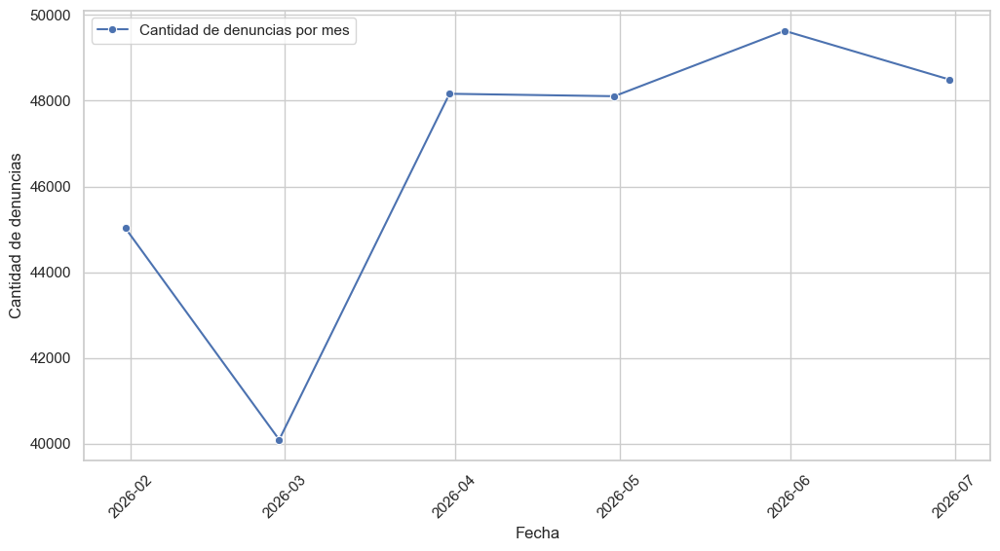

In [331]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=date_counts, x='RPT_DT_FORMATTED', y='count', marker='o', label='Cantidad de denuncias por mes')
plt.xticks(rotation=45)
plt.xlabel("Fecha")
plt.ylabel("Cantidad de denuncias")
plt.grid(True)
plt.show()

In [332]:
pd_cd_counts = plot_df.groupby(['PD_CD'], observed=True).size().reset_index(name='count').sort_values('count', ascending=True)
pd_cd_counts

,PD_CD,count
355,969,1
171,440,1
295,754,1
287,727,1
77,285,1
...,...,...
354,922,9963
9,109,10770
91,333,20251
1,101,22837


### Explorando los códigos KY_CD y PD_CD:

In [252]:
pd_cd_counts_lw_2 = pd_cd_counts[pd_cd_counts['count'] <= 2].sort_values('count', ascending=True)
pd_cd_counts_lw_2['PD_CD'] = pd_cd_counts_lw_2['PD_CD'].cat.remove_unused_categories()
pd_cd_counts_lw_2

,PD_CD,count
355,969,1
331,846,1
117,381,1
324,821,1
325,822,1
327,829,1
17,119,1
78,289,1
309,786,1
251,643,1


In [333]:
filtro = plot_df['PD_CD'].isin(pd_cd_counts_lw_2['PD_CD'])
plot_df.loc[filtro, ['PD_CD', 'PD_DESC']].drop_duplicates()

,PD_CD,PD_DESC
6352,798,FIREARMS LICENSING LAWS
9289,393,"ROBBERY,OF TRUCK DRIVER"
10286,566,"MARIJUANA, POSSESSION"
11132,843,INAPPROPIATE SHELTER DOG LEFT
16337,375,"ROBBERY,PHARMACY"
23662,610,"LOITERING,GAMBLING,OTHER"
27072,595,UNLAWFUL POSS. WEAPON UPON SCH
29153,275,POSTING ADVERTISEMENTS
32732,888,"HEALTH CODE,UNCLASSIFIED MISDE"
33064,568,"MARIJUANA, POSSESSION 1, 2 & 3"


In [254]:
pd_cd_counts_gt_1000 = pd_cd_counts[pd_cd_counts['count'] > 1000].sort_values('count', ascending=True)
pd_cd_counts_gt_1000['PD_CD'] = pd_cd_counts_gt_1000['PD_CD'].cat.remove_unused_categories()
pd_cd_counts_gt_1000

,PD_CD,count
50,213,1035
85,305,1073
169,438,1116
133,397,1118
52,221,1134
63,258,1176
6,106,1177
45,203,1177
199,503,1182
137,402,1195


In [334]:
filtro = plot_df['PD_CD'].isin(pd_cd_counts_gt_1000['PD_CD'])
plot_df.loc[filtro, ['PD_CD', 'PD_DESC']].drop_duplicates()

,PD_CD,PD_DESC
0,106,ASSAULT POLICE/PEACE OFFICER
1,638,"HARASSMENT,SUBD 3,4,5"
4,922,"TRAFFIC,UNCLASSIFIED MISDEMEAN"
5,333,"LARCENY,PETIT FROM STORE-SHOPL"
6,637,"HARASSMENT,SUBD 1,CIVILIAN"
7,305,"LARCENY,PETIT BY CREDIT CARD U"
8,759,"PUBLIC ADMINISTATION,UNCLASS M"
9,105,STRANGULATION 1ST
10,321,"LARCENY,PETIT FROM AUTO"
11,478,"THEFT OF SERVICES, UNCLASSIFIE"


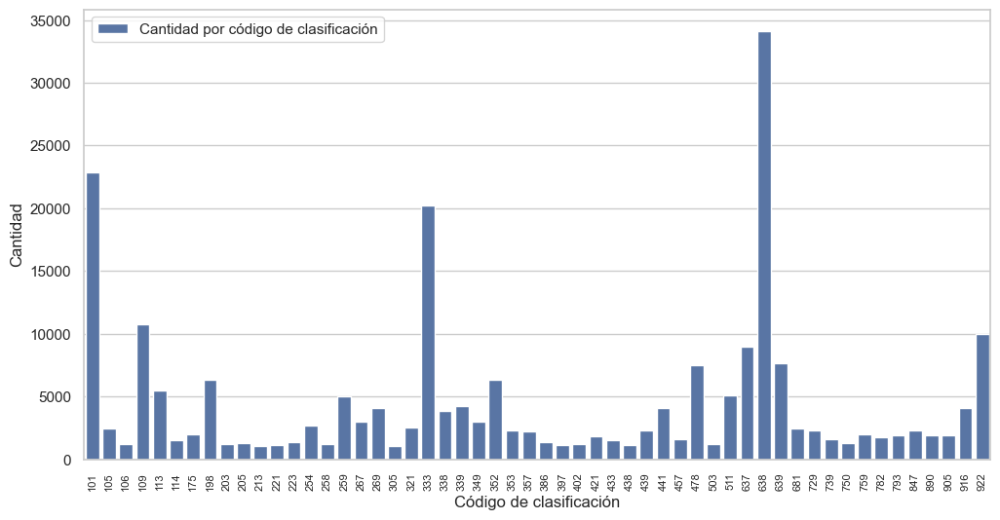

In [335]:
plt.figure(figsize=(12, 6))
sns.barplot(data=pd_cd_counts_gt_1000, x='PD_CD', y='count', label='Cantidad por código de clasificación')
plt.xticks(rotation=90, fontsize=8)
plt.xlabel("Código de clasificación")
plt.ylabel("Cantidad")
plt.show()

In [336]:
pd_cd_counts_lw_10_gt_5 = pd_cd_counts[(pd_cd_counts['count'] < 10) & (pd_cd_counts['count'] > 5)].sort_values('count', ascending=True)
pd_cd_counts_lw_10_gt_5['PD_CD'] = pd_cd_counts_lw_10_gt_5['PD_CD'].cat.remove_unused_categories()
pd_cd_counts_lw_10_gt_5

,PD_CD,count
267,683,6
7,107,6
37,187,6
310,788,6
90,331,7
265,674,7
253,645,7
314,797,7
24,164,7
303,772,7


In [337]:
filtro = plot_df['PD_CD'].isin(pd_cd_counts_lw_10_gt_5['PD_CD'])
plot_df.loc[filtro, ['PD_CD', 'PD_DESC']].drop_duplicates()

,PD_CD,PD_DESC
2506,107,END WELFARE VULNERABLE ELDERLY PERSON
2912,808,TAX LAW
9955,797,CRIM POS WEAP 4
14160,674,EAVESDROPPING
17013,524,"CONTROLLED SUBSTANCE,POSSESS.-"
21204,874,"PEDDLING,UNLAWFUL"
21421,174,"SEXUAL MISCONDUCT,DEVIATE"
22528,788,"FIREWORKS, SALE"
24644,772,COMPUTER TAMPER/TRESSPASS
26435,815,NEGLECT/POISON ANIMAL


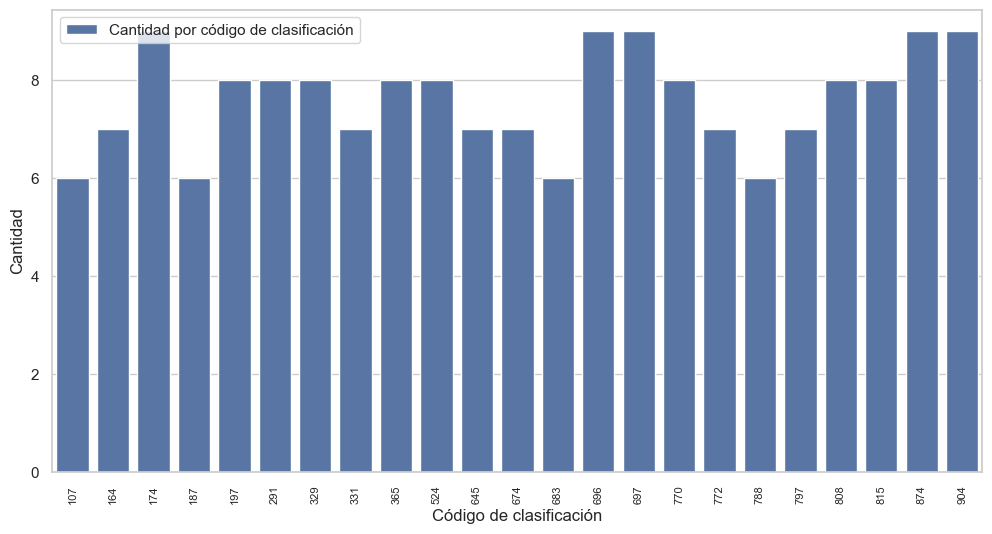

In [338]:
plt.figure(figsize=(12, 6))
sns.barplot(data=pd_cd_counts_lw_10_gt_5, x='PD_CD', y='count', label='Cantidad por código de clasificación')
plt.xticks(rotation=90, fontsize=8)
plt.xlabel("Código de clasificación")
plt.ylabel("Cantidad")
plt.show()

In [364]:
sns.set_theme(style='whitegrid', context='notebook')

# PLOT_STRING_COLUMNS = [
#     'LAW_CAT_CD', 'CRM_ATPT_CPTD_CD', 'LOC_OF_OCCUR_DESC', 'BORO_NM',
#     'SUSP_RACE', 'SUSP_SEX', 'SUSP_AGE_GROUP',
#     'VIC_RACE', 'VIC_SEX', 'VIC_AGE_GROUP', 'PATROL_BORO'
# ]
# for column in PLOT_STRING_COLUMNS:
#     plot_df[column] = df_data[column].astype('string').fillna(UNKNOWN_LABEL).astype(str)

AGE_ORDER = ['<18', '18-24', '25-44', '45-64', '65+', UNKNOWN_LABEL]
# Solo un orden visual, no que sea categoríca ordinal.
WEEKDAY_ORDER = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
WEEKDAY_NAMES = dict(enumerate(WEEKDAY_ORDER))
BOROUGH_ORDER = ['BRONX', 'BROOKLYN', 'MANHATTAN', 'QUEENS', 'STATEN ISLAND']

# Cada codigo se cuenta de forma independiente y se muestra la descripcion asociada más frecuente
# cuando la fuente contiene más de una.
CODE_DESCRIPTION_PAIRS = [
    ('KY_CD', 'OFNS_DESC'),
    ('PD_CD', 'PD_DESC'),
    ('JURISDICTION_CODE', 'JURIS_DESC')
]

def add_code_description_label(code_col, description_col, prefix):
    codes = plot_df[code_col].astype('string')
    descriptions = plot_df[description_col].astype('string')
    pairs = pd.DataFrame({'code': codes, 'description': descriptions})
    description_by_code = (
        pairs.groupby(['code', 'description'], dropna=False).size()
        .rename('count').reset_index()
        .sort_values(['code', 'count', 'description'], ascending=[True, False, True], kind='stable')
        .drop_duplicates('code').set_index('code')['description']
    )
    label_col = f'{prefix}_LABEL_PLOT'
    plot_df[label_col] = (
        codes.map(description_by_code).fillna(UNKNOWN_LABEL) + ' [' + codes + ']'
    )
    return label_col

CODE_LABEL_COLUMNS = {
    code_col: add_code_description_label(code_col, description_col, code_col)
    for code_col, description_col in CODE_DESCRIPTION_PAIRS
}
CRIME_CODE_DESCRIPTION_PAIRS = CODE_DESCRIPTION_PAIRS[:2]

time_delta = pd.to_timedelta(df_data['CMPLNT_FR_TM'].astype('string').str.strip(), errors='coerce')
plot_df['HOUR_PLOT'] = time_delta.dt.components.hours.where(time_delta.notna()).astype('Int64')
plot_df['WEEKDAY_PLOT'] = df_data['CMPLNT_FR_DT_FORMATTED'].dt.dayofweek.map(WEEKDAY_NAMES)

def show_plot(fig):
    fig.tight_layout()
    plt.show()
    plt.close(fig)

def plot_pie(series, title=None, top_n=None):
    counts = series.value_counts()
    title = title or f'Distribución de {plot_label(series.name)}'
    if top_n is not None and len(counts) > top_n:
        top = counts.head(top_n)
        counts = pd.concat([top, pd.Series({'Otros': counts.iloc[top_n:].sum()})])
    fig, ax = plt.subplots(figsize=(9, 7))
    colors = sns.color_palette('tab20', n_colors=len(counts))
    ax.pie(
        counts.values, labels=counts.index, colors=colors,
        autopct=lambda pct: f'{pct:.1f}%' if pct >= 2 else '',
        startangle=90, counterclock=False,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1},
        textprops={'fontsize': 9}
    )
    ax.set_title(title, pad=20)
    ax.axis('equal')
    fig.savefig(f'./plots/pie_{title.replace(" ", "_")}.pdf', format='pdf', dpi=300, bbox_inches='tight')
    fig.savefig(f'./plots/pie_{title.replace(" ", "_")}.png', format='png', dpi=300, bbox_inches='tight')
    show_plot(fig)

def draw_stacked_barh(table, title, row_label, stack_label, figsize=(14, 8),
                      left_margin=0.34, right_margin=0.80, tick_fontsize=8,
                      save_prefix=None):
    fig, ax = plt.subplots(figsize=figsize)
    table.plot(
        kind='barh', stacked=True, ax=ax,
        color=sns.color_palette('tab20', n_colors=max(1, len(table.columns))), width=0.85
    )
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel('Cantidad de denuncias')
    ax.set_ylabel(plot_label(row_label))
    plt.setp(ax.get_yticklabels(), fontsize=tick_fontsize)
    ax.legend(title=plot_label(stack_label), bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
    fig.subplots_adjust(left=left_margin, right=right_margin)
    if save_prefix is not None:
        fig.savefig(f'./plots/{save_prefix}.pdf', format='pdf', dpi=300, bbox_inches='tight')
        fig.savefig(f'./plots/{save_prefix}.png', format='png', dpi=300, bbox_inches='tight')
    show_plot(fig)

def plot_top_stacked(row_col, stack_col, title, top_n=10, stack_order=None,
                     row_label=None, stack_label=None, other_label=None,
                     figsize=None, left_margin=0.34, right_margin=0.80,
                     save_prefix=None):
    values = plot_df[row_col]
    row_order = values.value_counts().head(top_n).index.tolist()
    is_top = values.isin(row_order)
    if other_label is None:
        row_values = values.loc[is_top]
        stack_values = plot_df.loc[is_top, stack_col]
    else:
        row_values = values.where(is_top, other_label)
        stack_values = plot_df[stack_col]
        if (~is_top).any():
            row_order.append(other_label)
        title = f'{title}\nTop {top_n}; el resto se agrupa como {other_label}'

    if stack_order is None:
        stack_order = plot_df[stack_col].value_counts().index.tolist()
    table = pd.crosstab(row_values, stack_values)
    table = table.reindex(index=row_order, columns=stack_order, fill_value=0)
    draw_stacked_barh(
        table, title, row_label or row_col,
        stack_label or stack_col,
        figsize=figsize or (14, 8), left_margin=left_margin,
        right_margin=right_margin, save_prefix=save_prefix
    )

def plot_borough_by_category(category_col, title, top_n=10, category_label=None):
    selected = plot_df.loc[
        plot_df['BORO_NM'].ne(UNKNOWN_LABEL), ['BORO_NM', category_col]
    ]
    if selected.empty:
        print('No hay datos válidos para comparar por borough.')
        return
    category_order = selected[category_col].value_counts().head(top_n).index.tolist()
    borough_order = [b for b in BOROUGH_ORDER if b in selected['BORO_NM'].unique()]
    table = pd.crosstab(selected['BORO_NM'], selected[category_col])
    table = table.reindex(index=borough_order, columns=category_order, fill_value=0)
    draw_stacked_barh(
        table, title + f'\nSolo se incluyen las {top_n} categorías más frecuentes',
        'BORO_NM', category_label or category_col,
        figsize=(14, 8), left_margin=0.16, right_margin=0.80, tick_fontsize=8
    )

def plot_top_premise_heatmap(category_col, category_label=None, top_n=20):
    category_label = plot_label(category_label or category_col)
    values = plot_df[category_col]
    premises = plot_df['PREM_TYP_DESC']
    top_values = values.value_counts().head(top_n).index.tolist()
    top_premises = premises.value_counts().head(top_n).index.tolist()
    is_top_value = values.isin(top_values)
    is_top_premise = premises.isin(top_premises)
    grouped_values = values.where(is_top_value, 'Otros códigos')
    grouped_premises = premises.where(is_top_premise, 'Otros lugares')
    value_order = top_values + (['Otros códigos'] if (~is_top_value).any() else [])
    premise_order = top_premises + (['Otros lugares'] if (~is_top_premise).any() else [])
    counts = pd.crosstab(grouped_values, grouped_premises)
    counts = counts.reindex(index=value_order, columns=premise_order, fill_value=0)
    percentages = counts.div(counts.sum(axis=0).replace(0, np.nan), axis=1) * 100

    fig, ax = plt.subplots(figsize=(17, 9))
    sns.heatmap(
        percentages, cmap='YlOrRd', annot=True, fmt='.1f', vmin=0, vmax=100,
        linewidths=0.4, cbar_kws={'label': f'% dentro de {plot_label("PREM_TYP_DESC")}'}, ax=ax
    )
    ax.set_title(
        f'{category_label} dentro de {plot_label("PREM_TYP_DESC")}\n'
        f'Top {top_n} códigos + otros; cada columna suma 100 %'
    )
    ax.set_xlabel(plot_label('PREM_TYP_DESC'))
    ax.set_ylabel(category_label)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=7)
    plt.setp(ax.get_yticklabels(), fontsize=6)
    show_plot(fig)

### Distribución horaria de los delitos

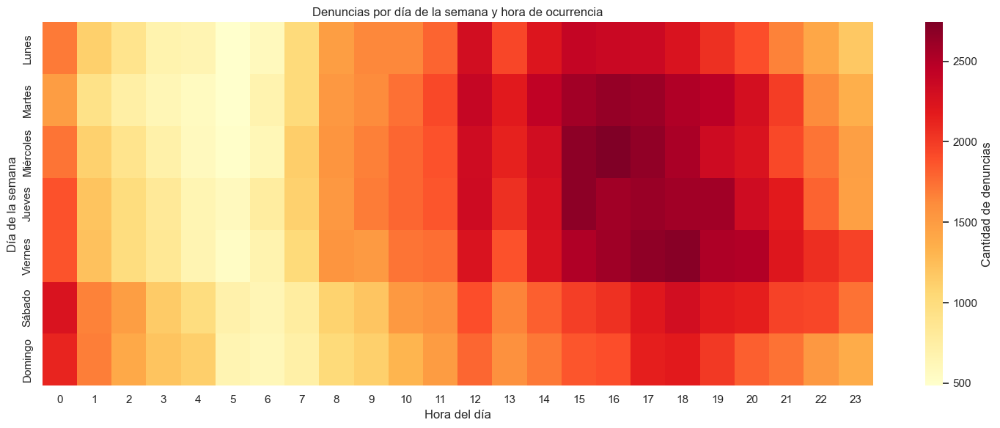

In [341]:
# Día de la semana y hora de ocurrencia
hourday = pd.crosstab(plot_df['WEEKDAY_PLOT'], plot_df['HOUR_PLOT'])
hourday = hourday.reindex(index=WEEKDAY_ORDER, columns=range(24), fill_value=0)
fig, ax = plt.subplots(figsize=(15, 6))
sns.heatmap(hourday, cmap='YlOrRd', ax=ax, cbar_kws={'label': 'Cantidad de denuncias'})
ax.set_title('Denuncias por día de la semana y hora de ocurrencia')
ax.set_xlabel(plot_label('HOUR_PLOT'))
ax.set_ylabel(plot_label('WEEKDAY_PLOT'))
fig.savefig('./plots/hourday.pdf', format='pdf', dpi=300, bbox_inches='tight')
fig.savefig('./plots/hourday.png', format='png', dpi=300, bbox_inches='tight')
show_plot(fig)

### Denuncias por gravedad

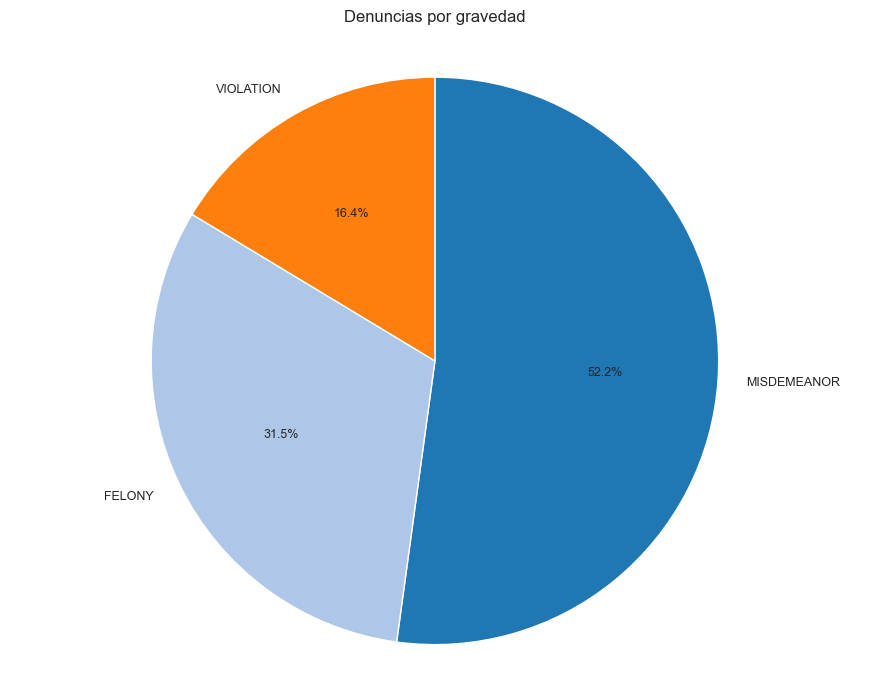

In [365]:
# Distribución por categoría legal
plot_pie(plot_df['LAW_CAT_CD'], 'Denuncias por gravedad')

### Top 10 de códigos con su descripción asociada

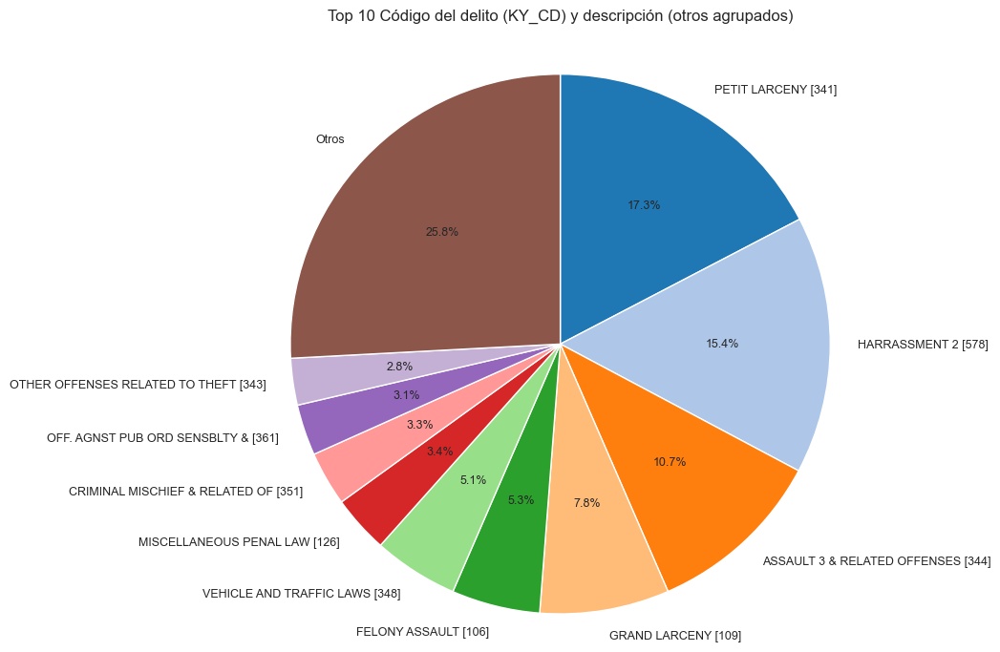

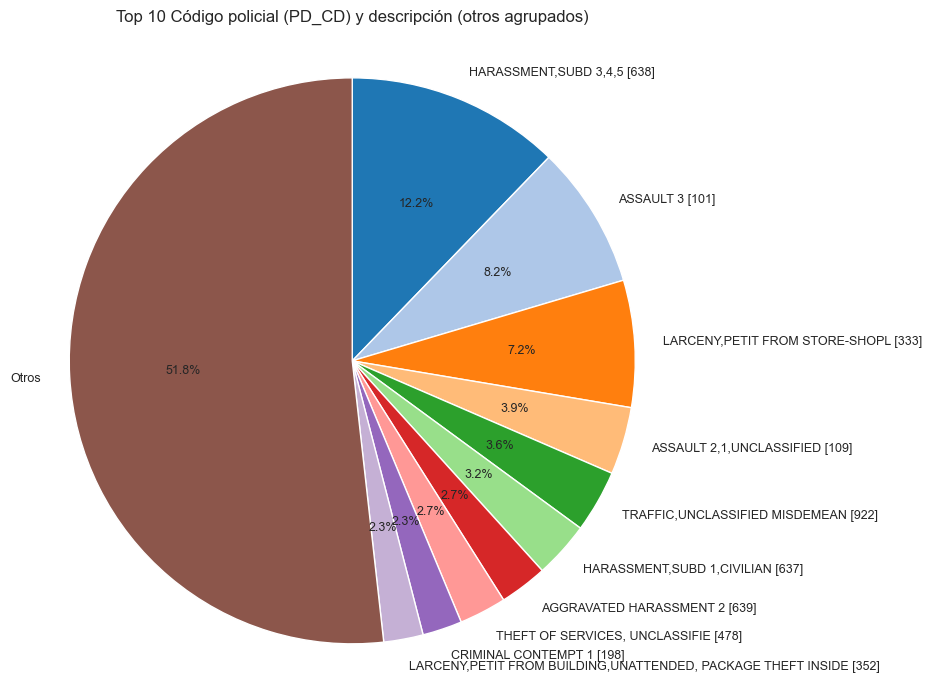

In [366]:
for code_col, description_col in CRIME_CODE_DESCRIPTION_PAIRS:
    label_col = CODE_LABEL_COLUMNS[code_col]
    display_label = plot_label(label_col)
    plot_pie(
        plot_df[label_col],
        f'Top 10 {display_label} (otros agrupados)',
        top_n=10
    )

### Códigos de delito apilados por gravedad

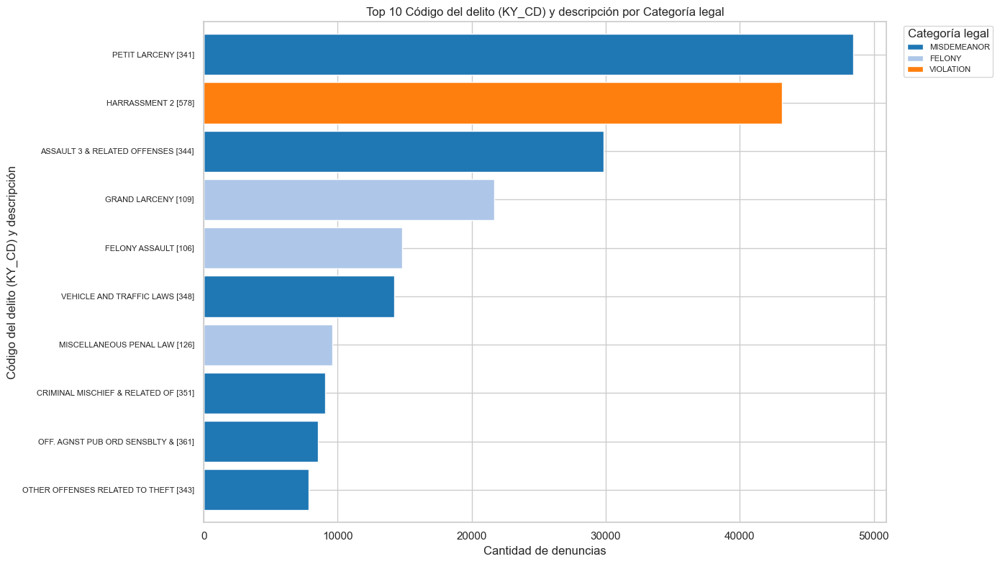

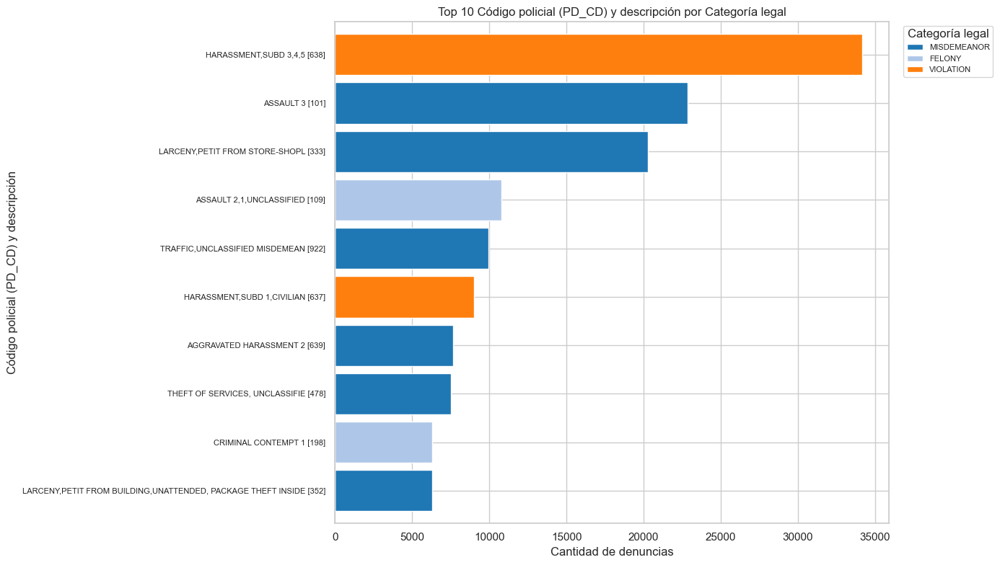

In [347]:
law_order = plot_df['LAW_CAT_CD'].value_counts().index.tolist()
for code_col, description_col in CRIME_CODE_DESCRIPTION_PAIRS:
    label_col = CODE_LABEL_COLUMNS[code_col]
    display_label = plot_label(label_col)
    plot_top_stacked(
        label_col, 'LAW_CAT_CD', f'Top 10 {display_label} por {plot_label("LAW_CAT_CD")}',
        stack_order=law_order, row_label=label_col
    )

### Jurisdicción agrupada por código; la descripción se usa como etiqueta

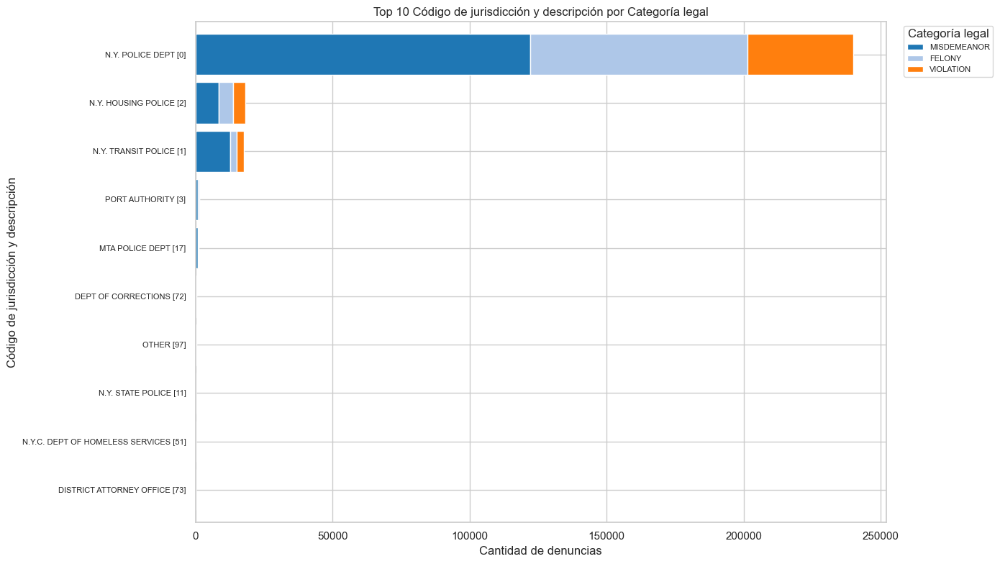

In [348]:
jurisdiction_label = CODE_LABEL_COLUMNS['JURISDICTION_CODE']
jurisdiction_display = plot_label(jurisdiction_label)
plot_top_stacked(
    jurisdiction_label, 'LAW_CAT_CD',
    f'Top 10 {jurisdiction_display} por {plot_label("LAW_CAT_CD")}',
    stack_order=law_order, row_label=jurisdiction_label
)

### Códigos de delito apilados por intento/completado

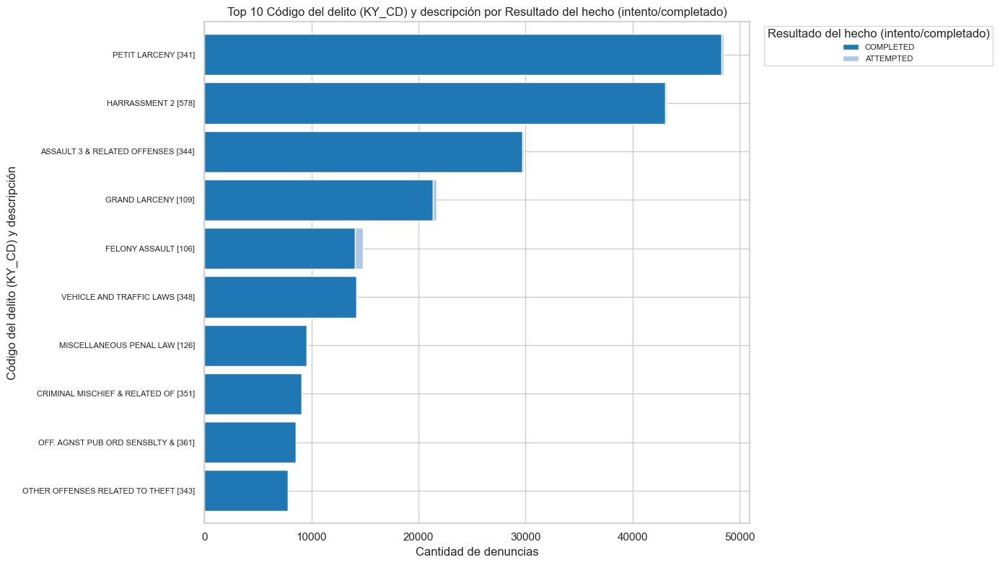

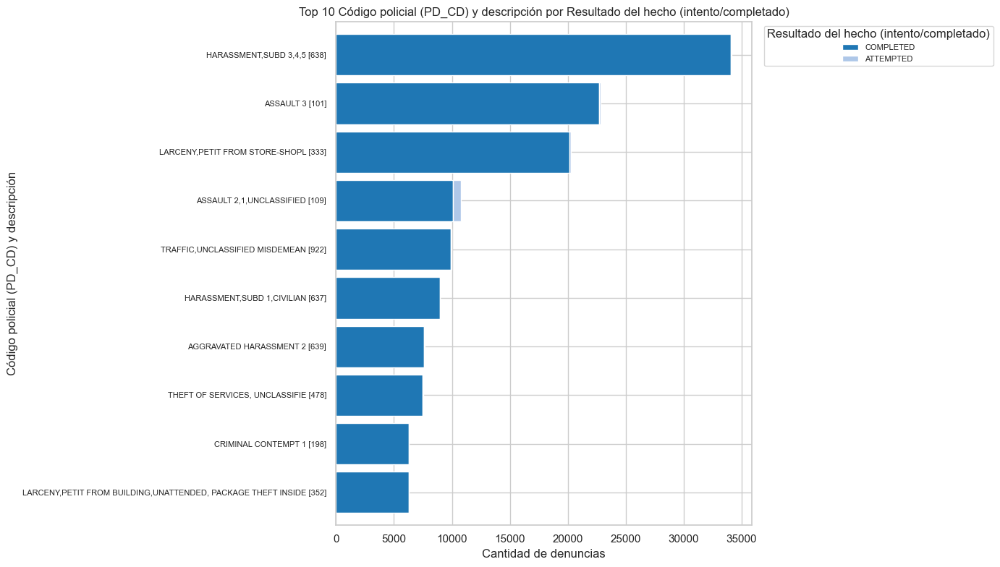

In [349]:
attempt_order = plot_df['CRM_ATPT_CPTD_CD'].value_counts().index.tolist()
for code_col, description_col in CRIME_CODE_DESCRIPTION_PAIRS:
    label_col = CODE_LABEL_COLUMNS[code_col]
    display_label = plot_label(label_col)
    plot_top_stacked(
        label_col, 'CRM_ATPT_CPTD_CD',
        f'Top 10 {display_label} por {plot_label("CRM_ATPT_CPTD_CD")}',
        stack_order=attempt_order, row_label=label_col
    )

### Jurisdicción agrupada por intento/completado

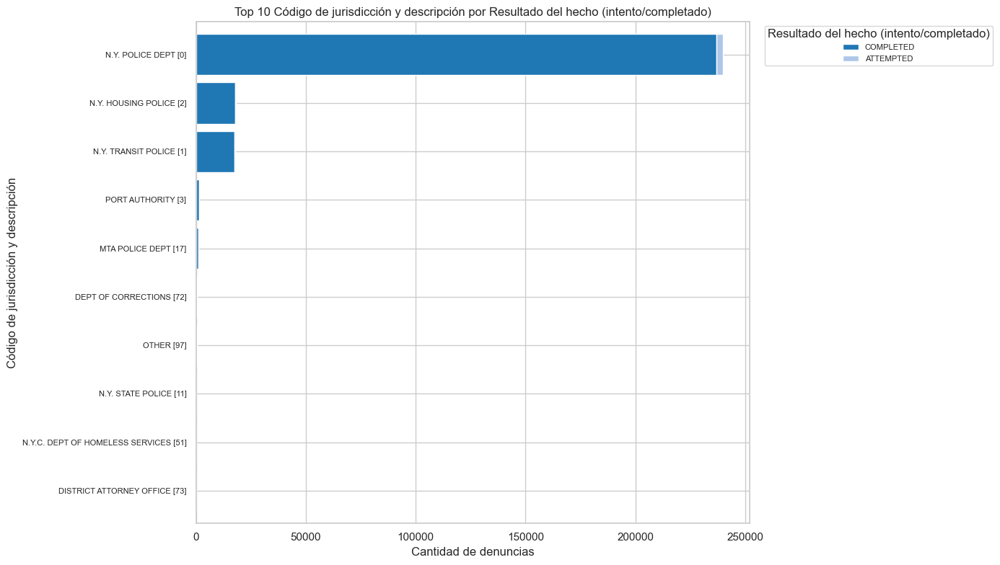

In [350]:
plot_top_stacked(
    jurisdiction_label, 'CRM_ATPT_CPTD_CD',
    f'Top 10 {jurisdiction_display} por {plot_label("CRM_ATPT_CPTD_CD")}',
    stack_order=attempt_order, row_label=jurisdiction_label
)

### Códigos de delito agrupados por lugar de ocurrencia

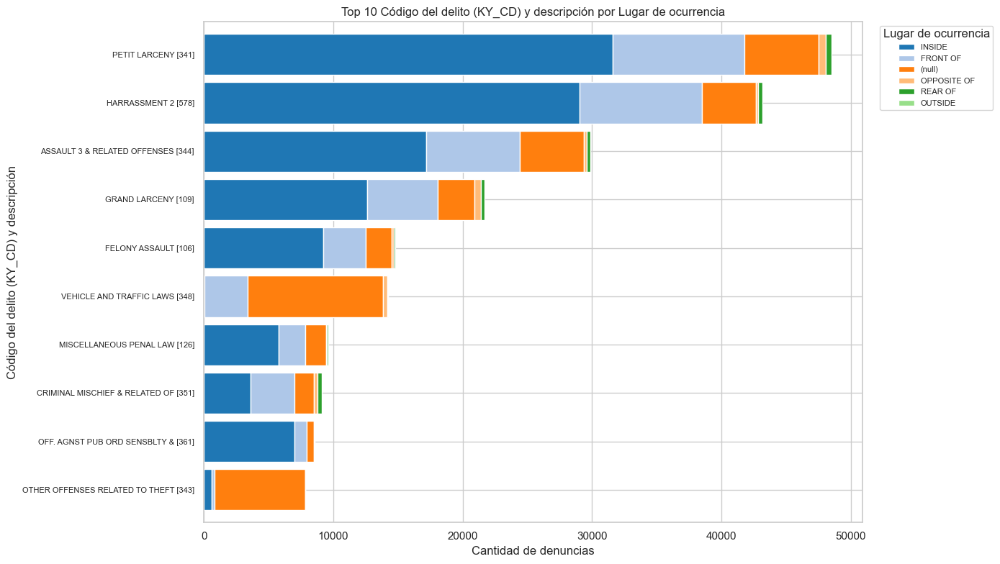

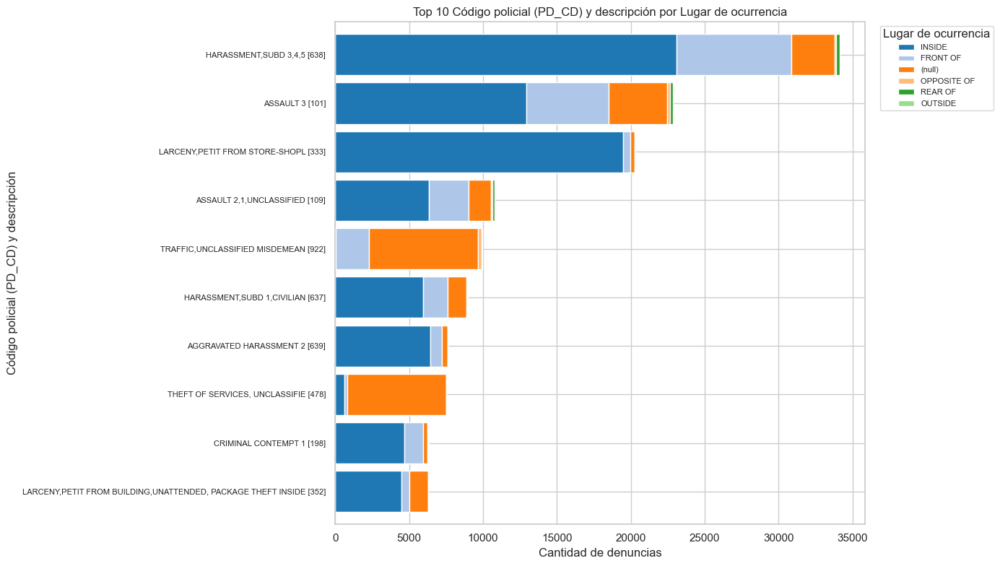

In [351]:
location_order = plot_df['LOC_OF_OCCUR_DESC'].value_counts().index.tolist()
for code_col, description_col in CRIME_CODE_DESCRIPTION_PAIRS:
    label_col = CODE_LABEL_COLUMNS[code_col]
    display_label = plot_label(label_col)
    plot_top_stacked(
        label_col, 'LOC_OF_OCCUR_DESC',
        f'Top 10 {display_label} por {plot_label("LOC_OF_OCCUR_DESC")}',
        stack_order=location_order, row_label=label_col
    )


In [352]:

def build_daily_borough_counts(category_col, top_n=None):
    columns = ['RPT_DT_FORMATTED', 'BORO_NM', category_col]
    valid = plot_df[columns].dropna(subset=['RPT_DT_FORMATTED'])
    valid = valid.loc[valid['BORO_NM'].ne(UNKNOWN_LABEL)]
    if valid.empty:
        return pd.DataFrame(columns=columns + ['daily_count'])

    if top_n is None:
        category_order = valid[category_col].value_counts().index.tolist()
    else:
        category_order = valid[category_col].value_counts().head(top_n).index.tolist()
    borough_order = [b for b in BOROUGH_ORDER if b in valid['BORO_NM'].unique()]
    dates = pd.date_range(valid['RPT_DT_FORMATTED'].min(), valid['RPT_DT_FORMATTED'].max(), freq='D')
    grouped = valid.groupby(columns, observed=True).size()
    full_index = pd.MultiIndex.from_product(
        [dates, borough_order, category_order], names=columns
    )
    return grouped.reindex(full_index, fill_value=0).rename('daily_count').reset_index()

def plot_temporal_by_category(category_col, title, top_n=None, legend_label=None):
    trend = build_daily_borough_counts(category_col, top_n=top_n)
    if trend.empty:
        print(f'No hay datos temporales válidos para {category_col}.')
        return
    fig, ax = plt.subplots(figsize=(15, 7))
    sns.lineplot(
        data=trend, x='RPT_DT_FORMATTED', y='daily_count', hue=category_col,
        estimator='mean', errorbar='sd', ax=ax
    )
    ax.set_title(title + '\nBanda: ±1 desvío estándar entre boroughs')
    ax.set_xlabel(plot_label('RPT_DT_FORMATTED'))
    ax.set_ylabel('Promedio diario de denuncias por borough')
    ax.tick_params(axis='x', rotation=45)
    ax.legend(title=plot_label(legend_label or category_col),
              bbox_to_anchor=(1.02, 1), loc='upper left')
    fig.subplots_adjust(right=0.80, bottom=0.20)
    show_plot(fig)

### Series temporales por categoría legal y por códigos con descripción asociada

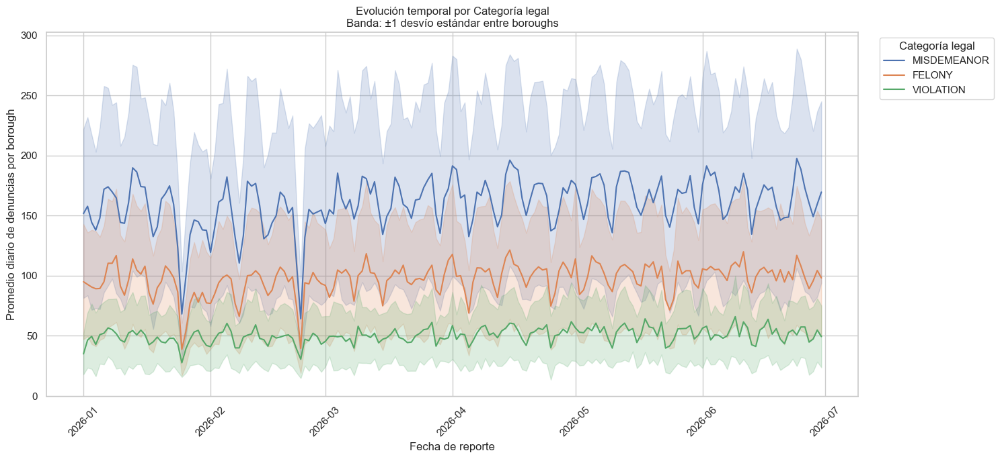

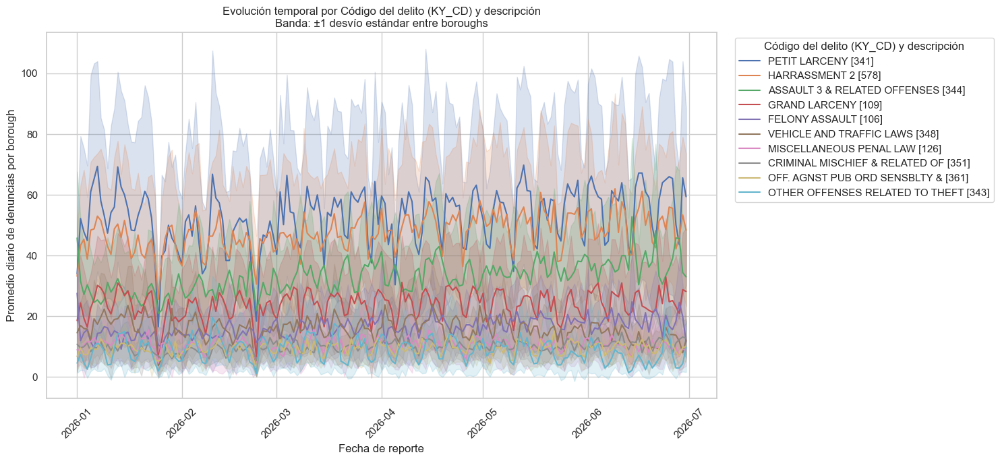

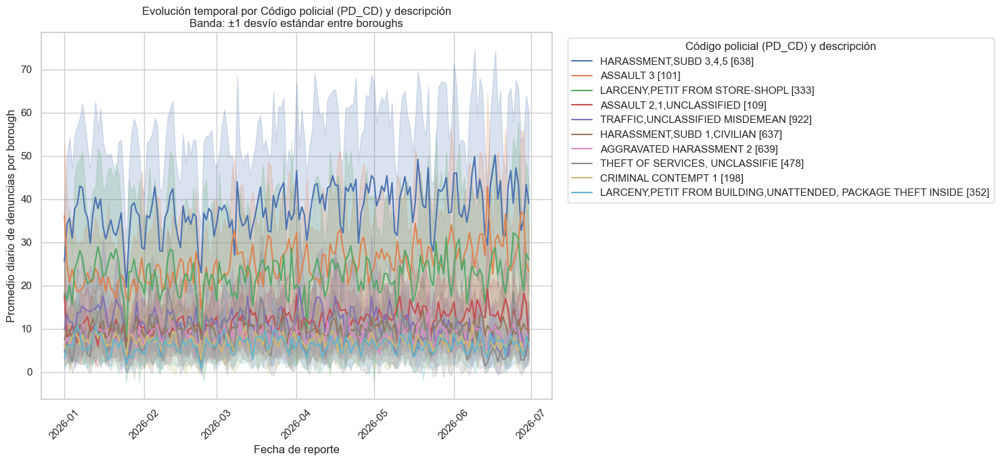

In [353]:
plot_temporal_by_category('LAW_CAT_CD', f'Evolución temporal por {plot_label("LAW_CAT_CD")}')
for code_col, description_col in CRIME_CODE_DESCRIPTION_PAIRS:
    plot_temporal_by_category(
        CODE_LABEL_COLUMNS[code_col],
        f'Evolución temporal por {plot_label(CODE_LABEL_COLUMNS[code_col])}',
        top_n=10,
        legend_label=CODE_LABEL_COLUMNS[code_col]
    )

### Sospechosos y víctimas: raza, sexo y edad:

In [356]:
def plot_stacked_categories(row_col, stack_col, title, row_order=None, stack_order=None, stack_label=None):
    if row_order is None:
        row_order = plot_df[row_col].value_counts().index.tolist()
    if stack_order is None:
        stack_order = plot_df[stack_col].value_counts().index.tolist()
    table = pd.crosstab(plot_df[row_col], plot_df[stack_col])
    table = table.reindex(index=row_order, columns=stack_order, fill_value=0)
    fig, ax = plt.subplots(figsize=(14, 7))
    table.plot(
        kind='bar', stacked=True, ax=ax,
        color=sns.color_palette('tab20', n_colors=max(1, len(table.columns))), width=0.85
    )
    ax.set_title(title)
    ax.set_xlabel(plot_label(row_col))
    ax.set_ylabel('Cantidad de registros')
    plt.setp(ax.get_xticklabels(), rotation=90, ha='center', fontsize=8)
    ax.legend(title=plot_label(stack_label or stack_col), bbox_to_anchor=(1.02, 1), loc='upper left')
    fig.subplots_adjust(right=0.80, bottom=0.22)
    show_plot(fig)

### Sospechosos: distribuciones y relaciones entre variables.

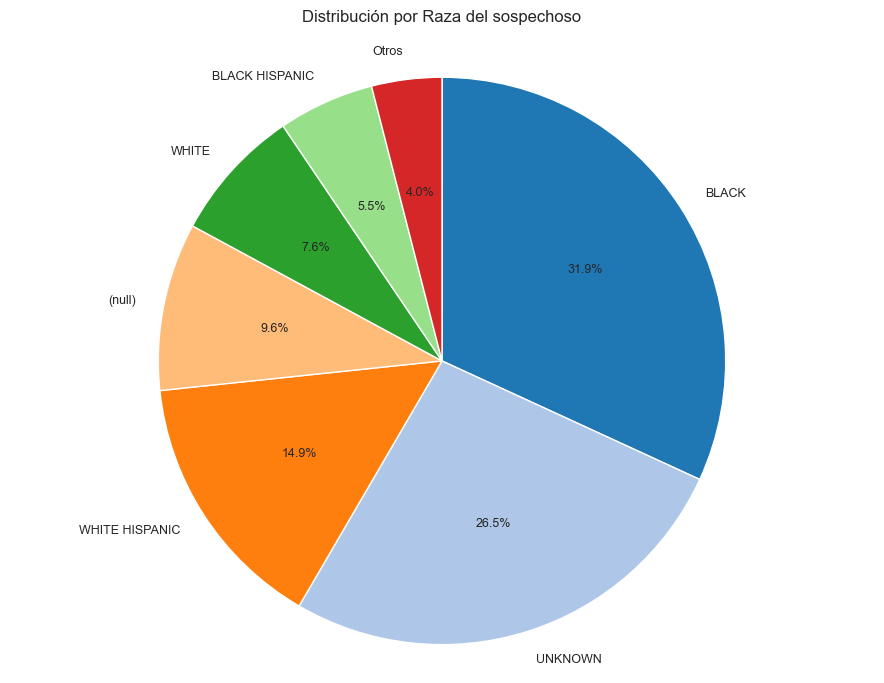

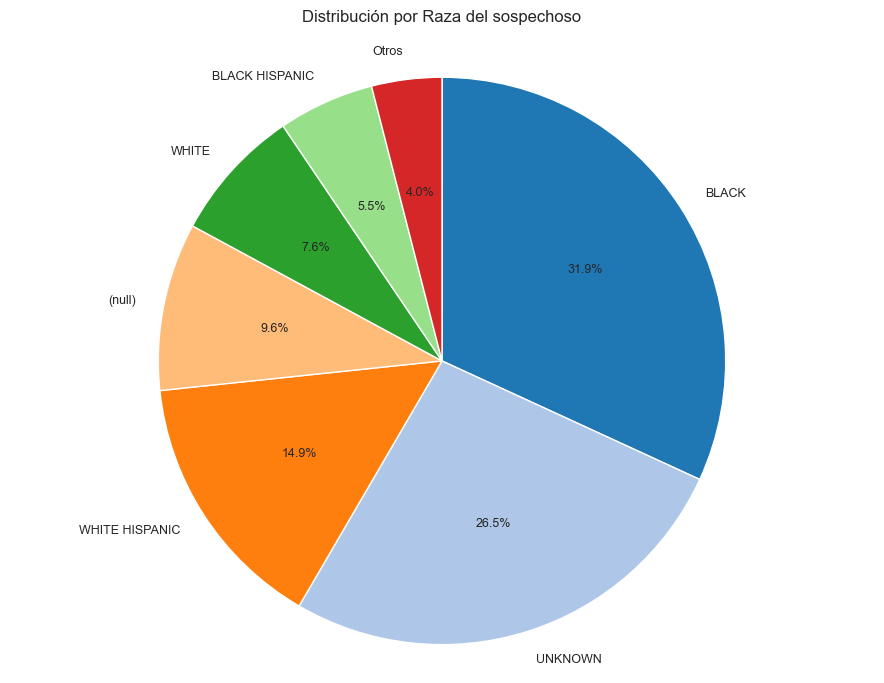

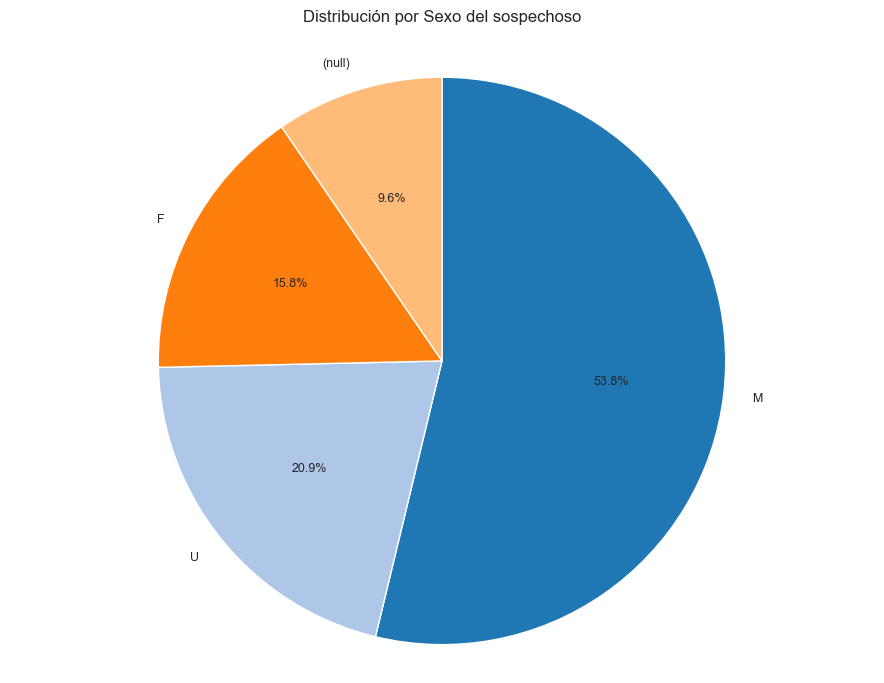

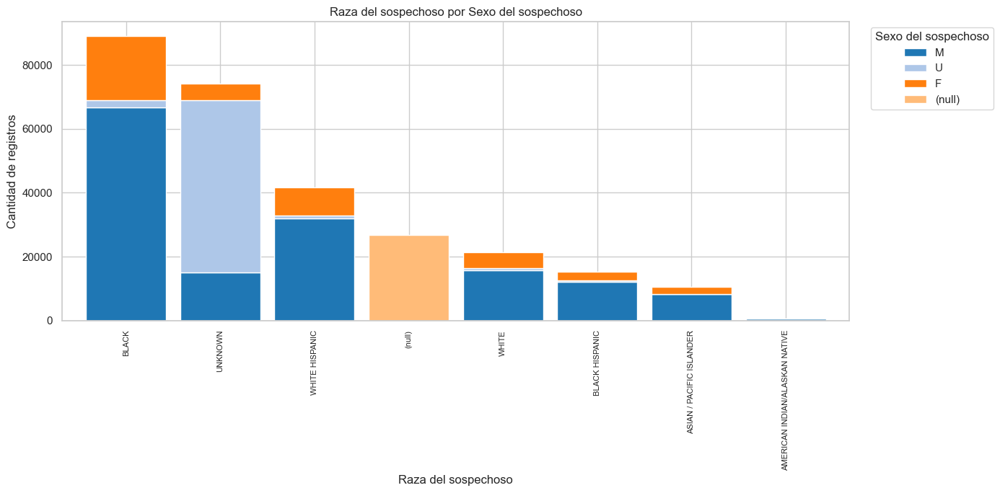

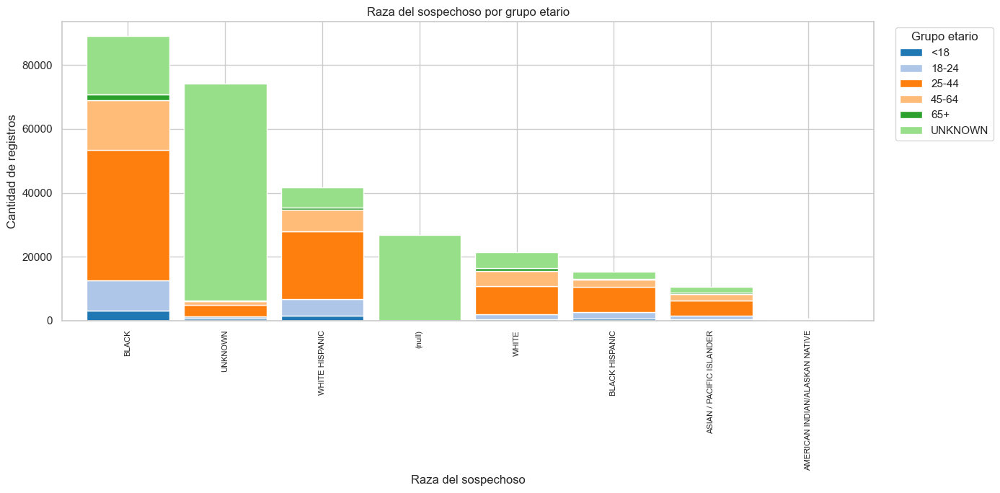

In [369]:
plot_pie(plot_df['SUSP_RACE'], f'Distribución por {plot_label("SUSP_RACE")}', top_n=6)
plot_pie(plot_df['SUSP_RACE'], f'Distribución por {plot_label("SUSP_RACE")}', top_n=6)
plot_pie(plot_df['SUSP_SEX'], f'Distribución por {plot_label("SUSP_SEX")}')
plot_stacked_categories('SUSP_RACE', 'SUSP_SEX',
                        f'{plot_label("SUSP_RACE")} por {plot_label("SUSP_SEX")}')
plot_stacked_categories('SUSP_RACE', 'SUSP_AGE_GROUP',
                        f'{plot_label("SUSP_RACE")} por grupo etario', stack_order=AGE_ORDER,
                        stack_label='Grupo etario')

### Víctimas: distribuciones y relaciones entre variables.

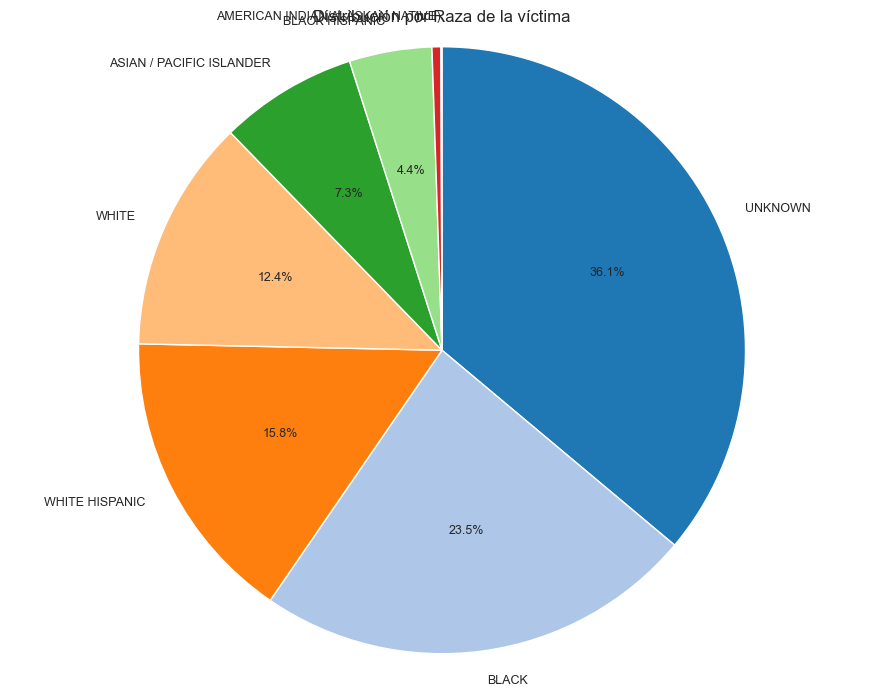

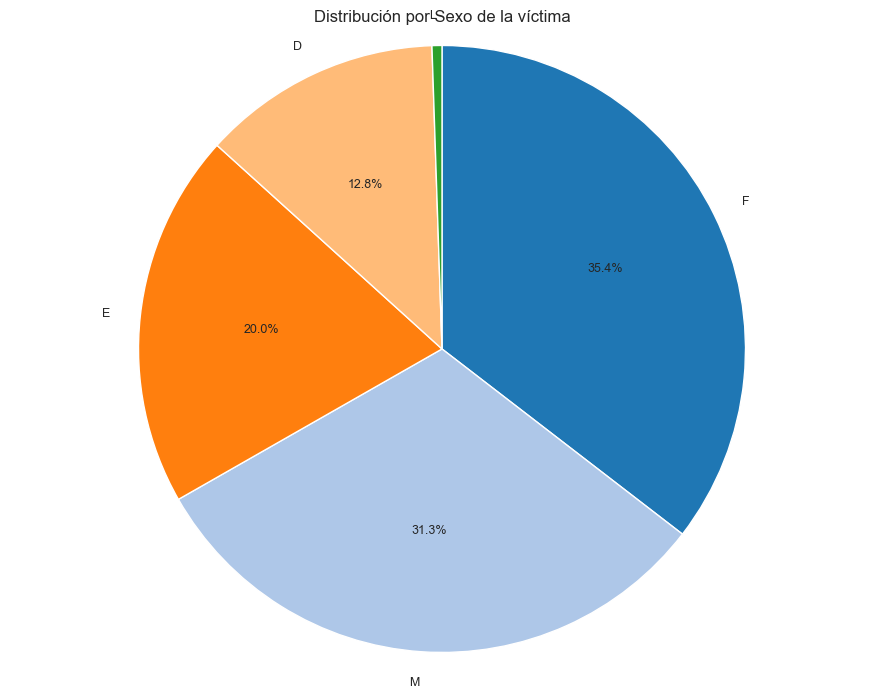

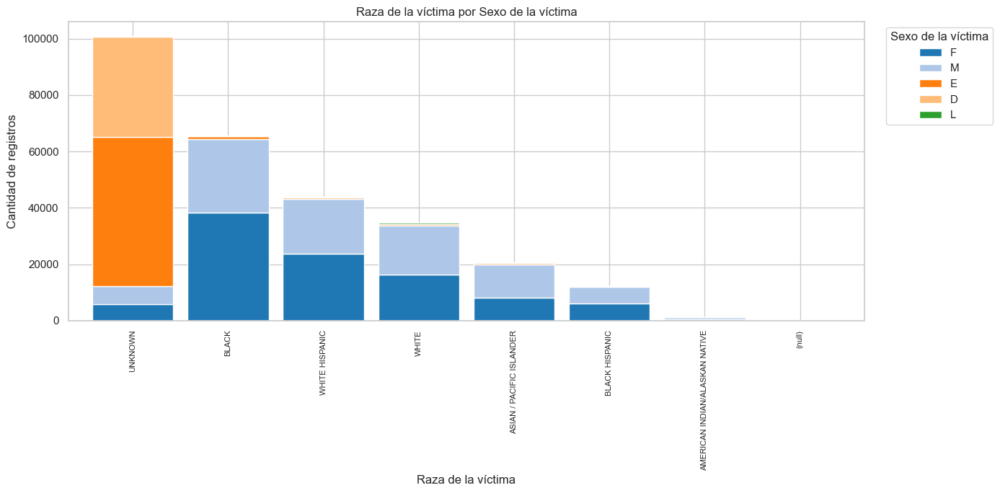

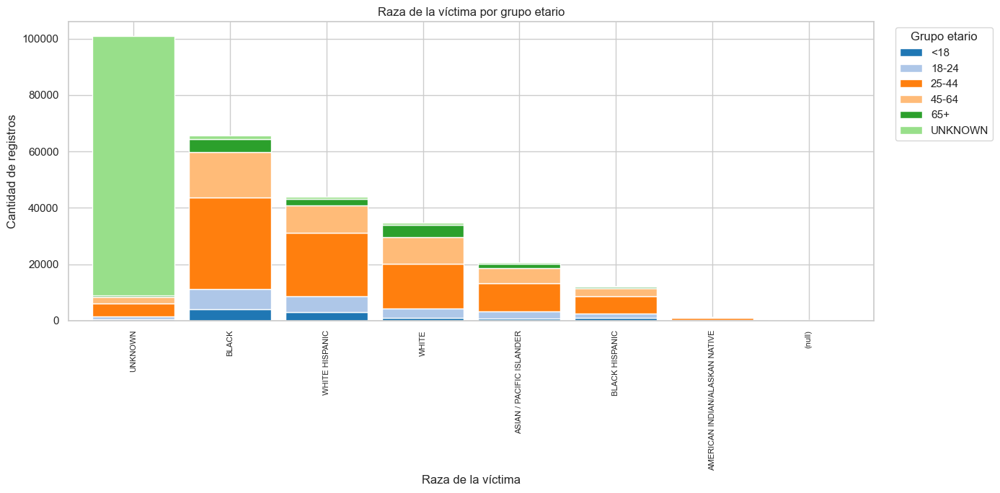

In [358]:
plot_pie(plot_df['VIC_RACE'], f'Distribución por {plot_label("VIC_RACE")}')
plot_pie(plot_df['VIC_SEX'], f'Distribución por {plot_label("VIC_SEX")}')
plot_stacked_categories('VIC_RACE', 'VIC_SEX',
                        f'{plot_label("VIC_RACE")} por {plot_label("VIC_SEX")}')
plot_stacked_categories('VIC_RACE', 'VIC_AGE_GROUP',
                        f'{plot_label("VIC_RACE")} por grupo etario', stack_order=AGE_ORDER,
                        stack_label='Grupo etario')

### Pirámides poblacionales

La pirámide de víctimas compara M/F/L como personas a la izquierda con D/E como entidades a la derecha. Otros valores de `VIC_SEX` no se incluyen en esa última visualización.

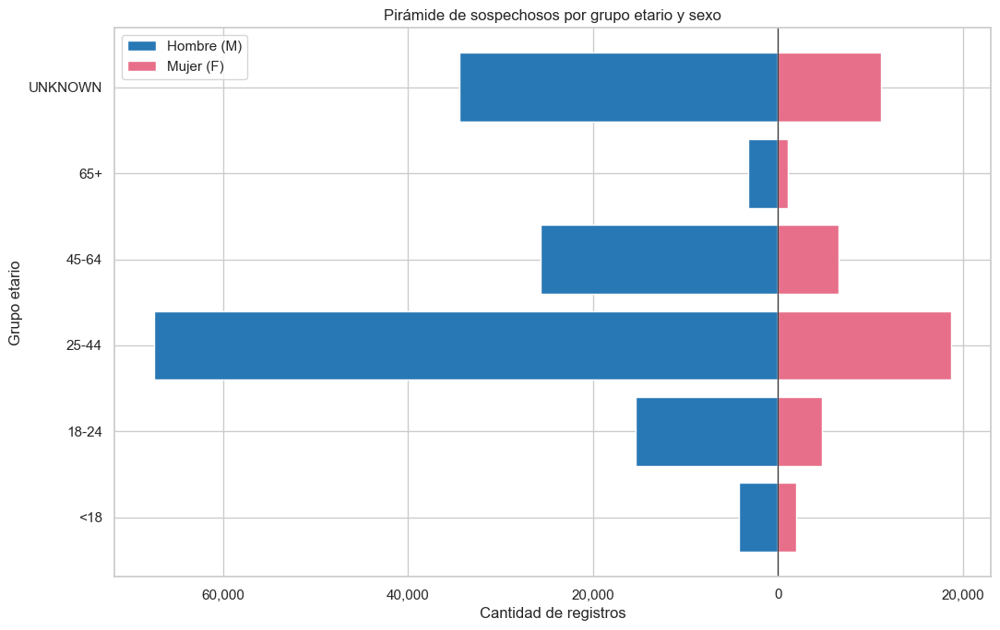

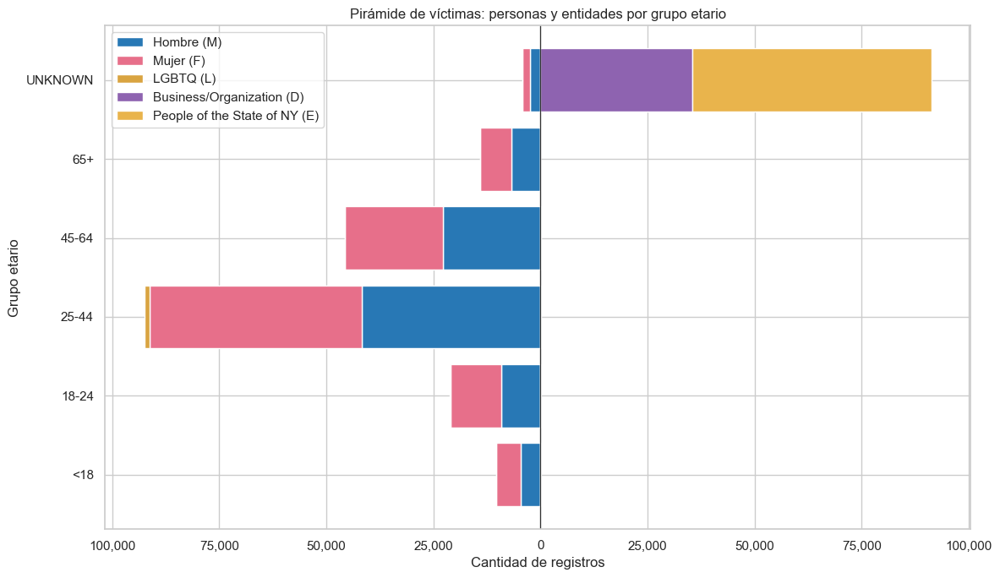

In [363]:
# Sospechosos: hombres a la izquierda, mujeres a la derecha.
suspect_counts = pd.crosstab(
    plot_df['SUSP_AGE_GROUP'], plot_df['SUSP_SEX']
).reindex(index=AGE_ORDER, fill_value=0)
for category in ['M', 'F']:
    if category not in suspect_counts.columns:
        suspect_counts[category] = 0
positions = np.arange(len(AGE_ORDER))
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(positions, -suspect_counts['M'], color='#2878B5', label='Hombre (M)')
ax.barh(positions, suspect_counts['F'], color='#E76F8A', label='Mujer (F)')
ax.axvline(0, color='#333333', linewidth=0.9)
ax.set_yticks(positions, labels=AGE_ORDER)
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{abs(value):,.0f}'))
ax.set_title('Pirámide de sospechosos por grupo etario y sexo')
ax.set_xlabel('Cantidad de registros')
ax.set_ylabel('Grupo etario')
ax.legend(loc='best')
show_plot(fig)

# 35. Víctimas: personas (M/F) a la izquierda y entidades (D/E) a la derecha, ambos lados apilados.
victim_counts = pd.crosstab(
    plot_df['VIC_AGE_GROUP'], plot_df['VIC_SEX']
).reindex(index=AGE_ORDER, fill_value=0)
for category in ['M', 'F', 'D', 'E']:
    if category not in victim_counts.columns:
        victim_counts[category] = 0
male = victim_counts['M'].to_numpy()
female = victim_counts['F'].to_numpy()
lgtbiq = victim_counts['L'].to_numpy()
business = victim_counts['D'].to_numpy()
state_entity = victim_counts['E'].to_numpy()
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(positions, -male, left=0, color='#2878B5', label='Hombre (M)')
ax.barh(positions, -female, left=-male, color='#E76F8A', label='Mujer (F)')
ax.barh(positions, -lgtbiq, left=-male-female, color='#D9A441', label='LGBTQ (L)')
ax.barh(positions, business, left=0, color='#8E63B0', label='Business/Organization (D)')
ax.barh(positions, state_entity, left=business, color='#E9B44C',
        label='People of the State of NY (E)')
ax.axvline(0, color='#333333', linewidth=0.9)
ax.set_yticks(positions, labels=AGE_ORDER)
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{abs(value):,.0f}'))
ax.set_title('Pirámide de víctimas: personas y entidades por grupo etario')
ax.set_xlabel('Cantidad de registros')
ax.set_ylabel('Grupo etario')
ax.legend(loc='best')
show_plot(fig)

### Top 10 códigos de ofensa, etiquetados con su descripción, apilados por características demográficas

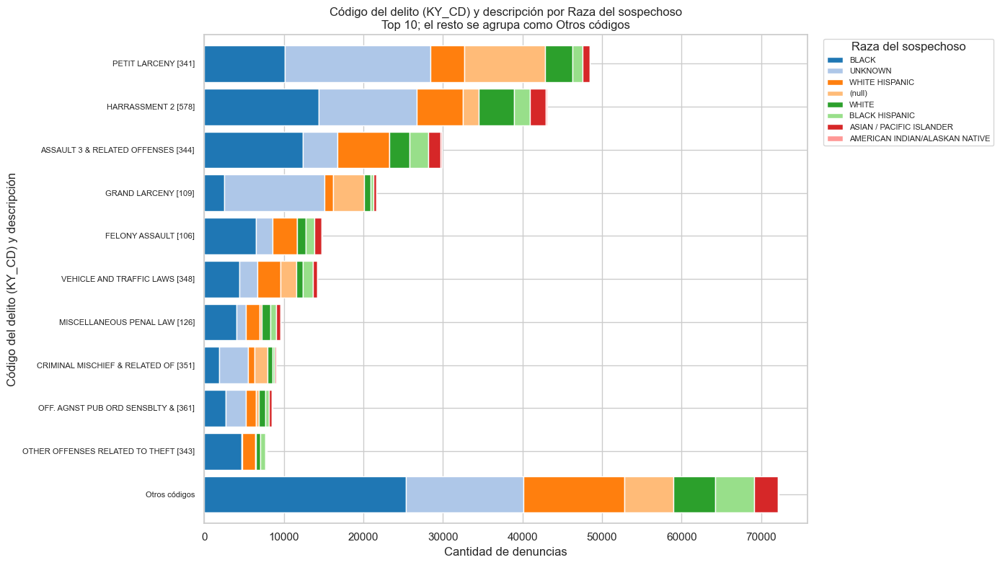

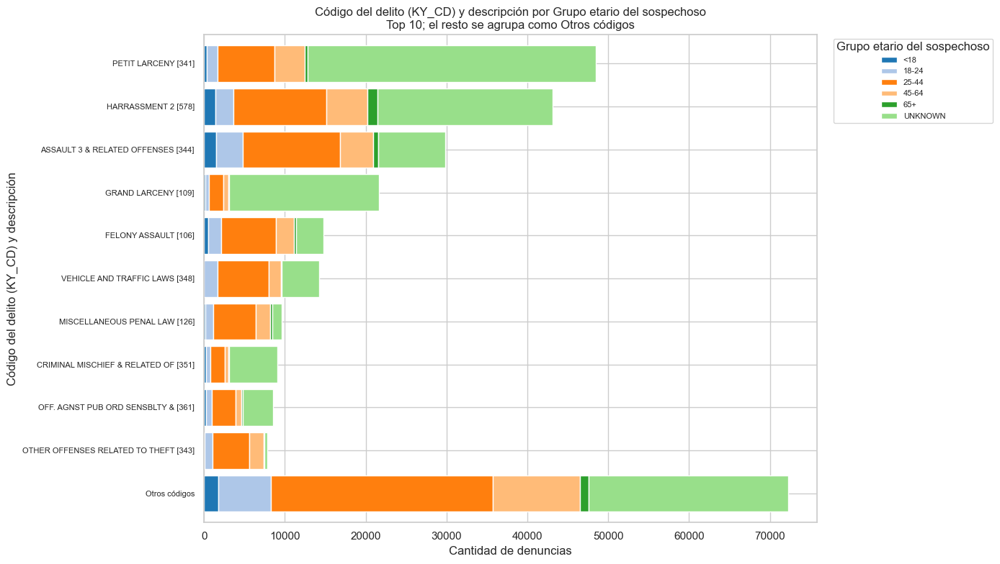

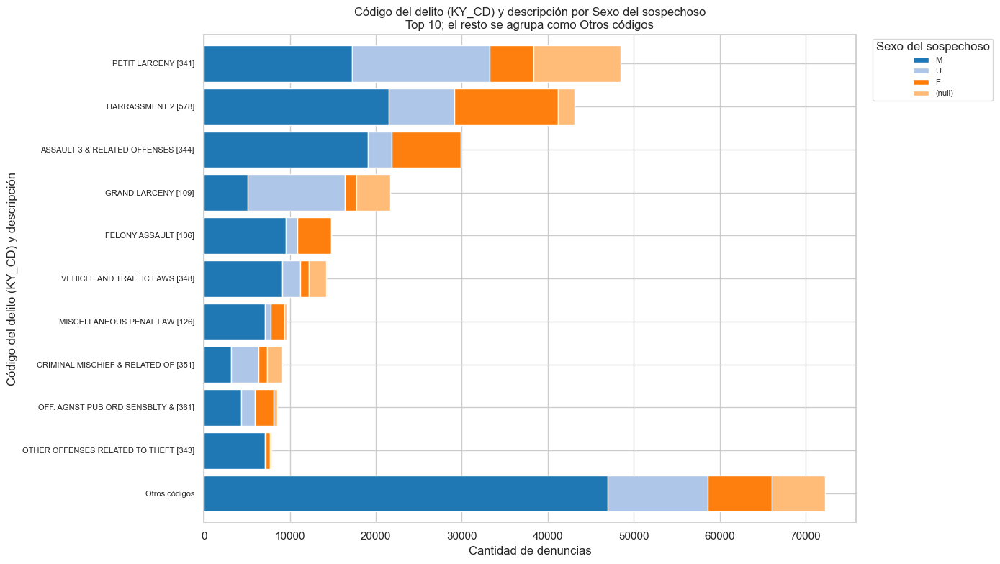

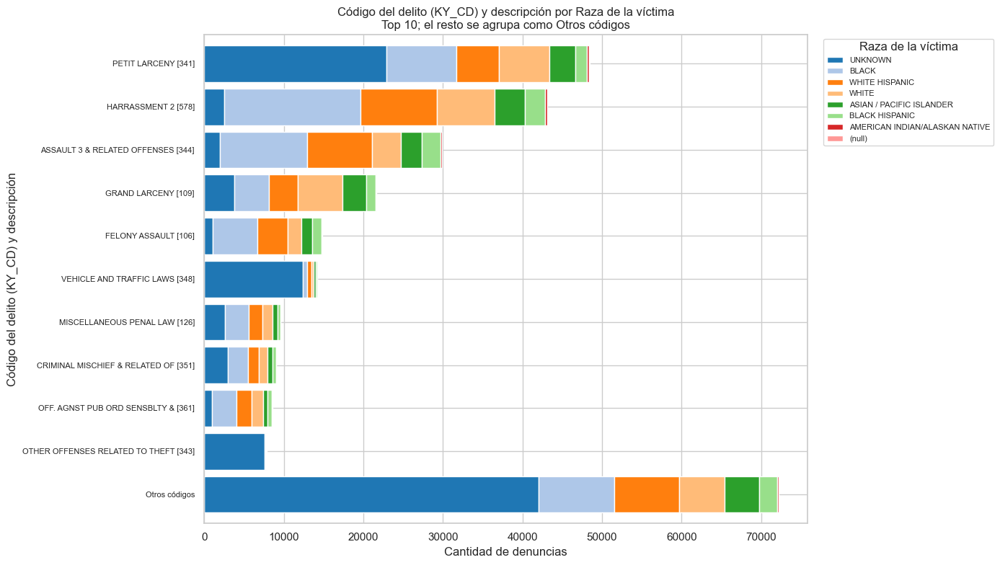

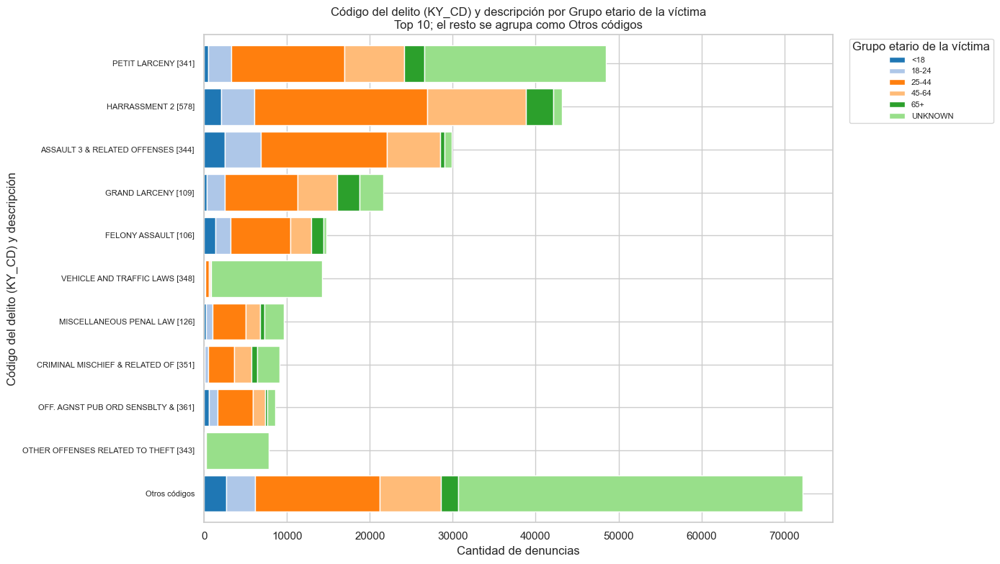

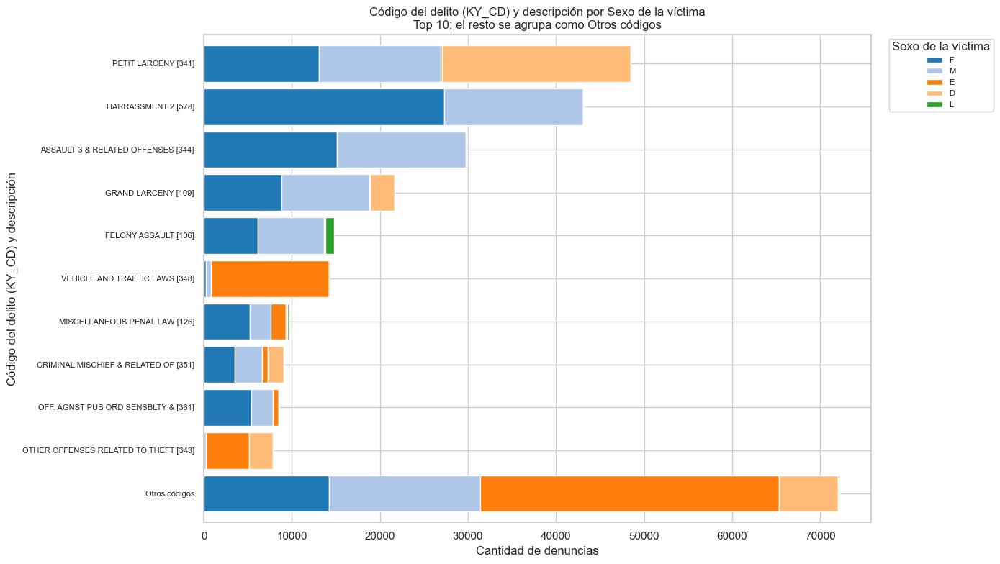

In [359]:
for stack_col, stack_order in [
    ('SUSP_RACE', None),
    ('SUSP_AGE_GROUP', AGE_ORDER),
    ('SUSP_SEX', None),
    ('VIC_RACE', None),
    ('VIC_AGE_GROUP', AGE_ORDER),
    ('VIC_SEX', None)
]:
    plot_top_stacked(
        CODE_LABEL_COLUMNS['KY_CD'], stack_col,
        f'{plot_label(CODE_LABEL_COLUMNS["KY_CD"])} por {plot_label(stack_col)}',
        top_n=10,
        other_label='Otros códigos',
        row_label=CODE_LABEL_COLUMNS['KY_CD'],
        stack_order=stack_order
    )

### Ciudades (boroughs), jurisdicciones y códigos de clasificación:

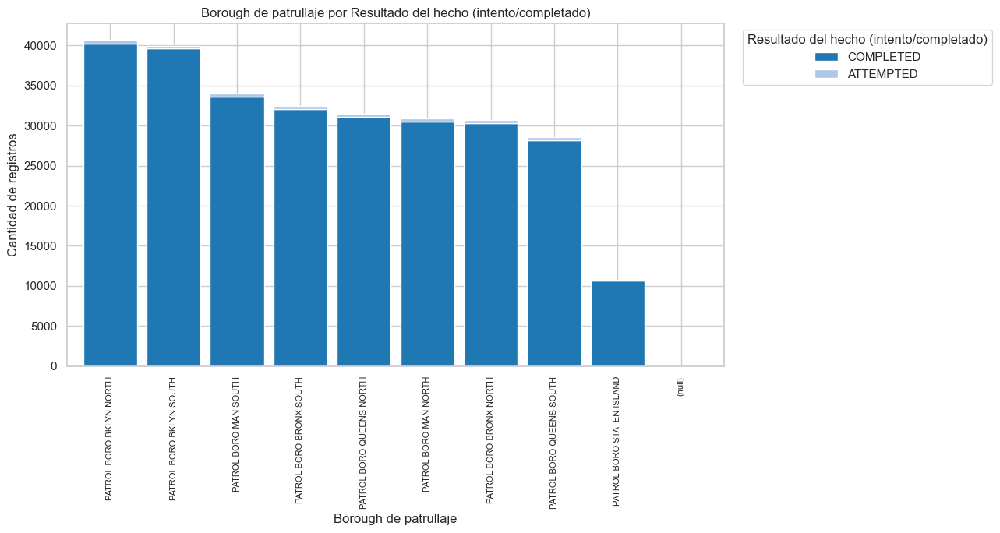

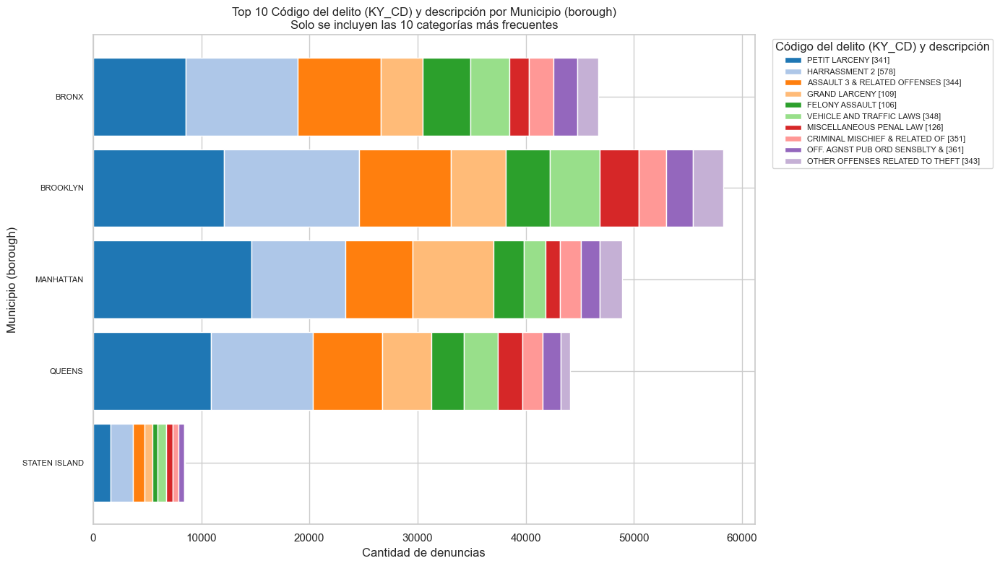

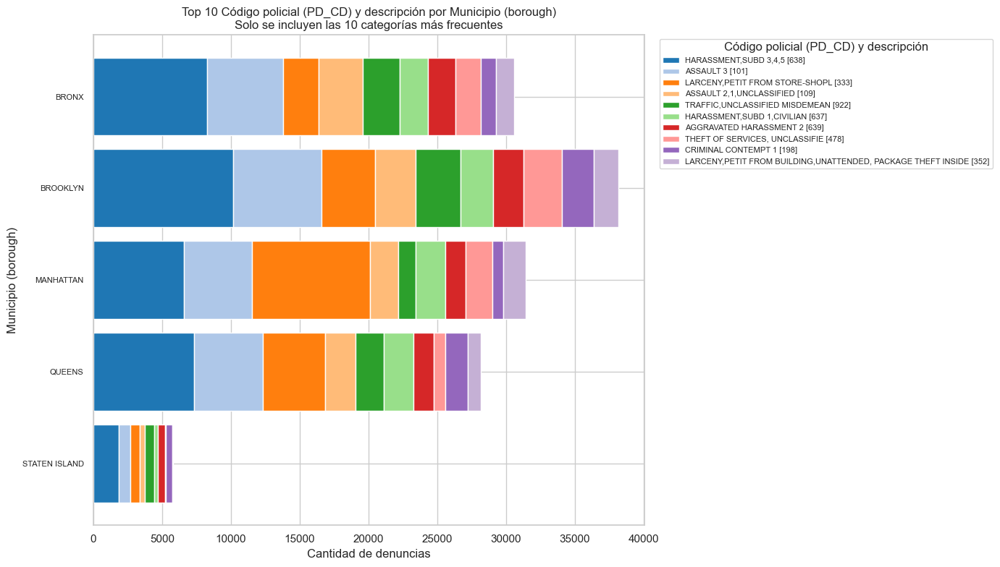

In [ ]:
# 27. Intentos/completados por borough de patrullaje.
plot_stacked_categories('PATROL_BORO', 'CRM_ATPT_CPTD_CD',
                        f'{plot_label("PATROL_BORO")} por {plot_label("CRM_ATPT_CPTD_CD")}')

# Composición por borough, agrupada por código y etiquetada con su descripción
for code_col, description_col in CRIME_CODE_DESCRIPTION_PAIRS:
    label_col = CODE_LABEL_COLUMNS[code_col]
    display_label = plot_label(label_col)
    plot_borough_by_category(
        label_col,
        f'Top 10 {display_label} por {plot_label("BORO_NM")}',
        top_n=10,
        category_label=label_col
    )

### Top 10 tipo de lugar del hecho por gravedad y por intento/cumplimiento del delito

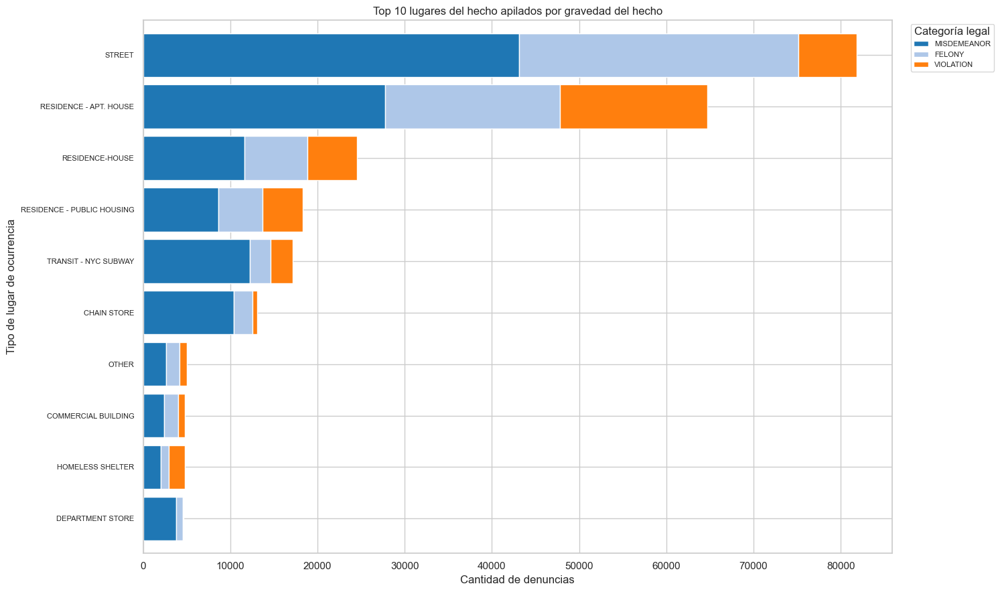

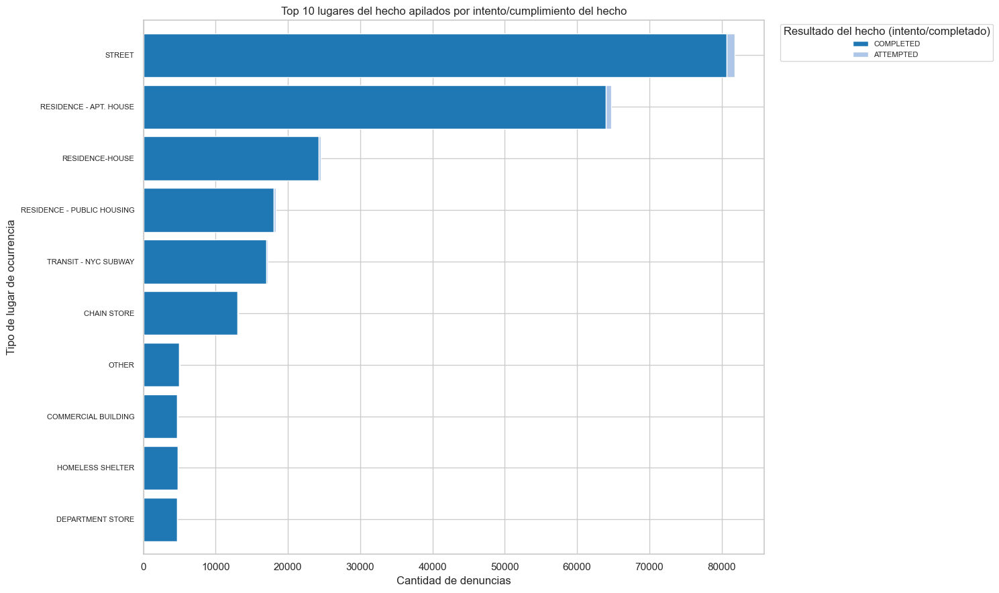

In [324]:
prem_order = plot_df['PREM_TYP_DESC'].value_counts().head(10).index.tolist()

premise_plot_specs = [
    ('LAW_CAT_CD', 'Top 10 lugares del hecho apilados por gravedad del hecho'),
    ('CRM_ATPT_CPTD_CD', 'Top 10 lugares del hecho apilados por intento/cumplimiento del hecho')
]
for stack_col, title in premise_plot_specs:
    save_prefix = f"prem_type_stacked_{title.replace(' ', '_').replace('/', '_')}"
    plot_top_stacked(
        'PREM_TYP_DESC', stack_col, title,
        top_n=10,
        row_label='PREM_TYP_DESC',
        stack_label=stack_col,
        figsize=(15, max(9, 0.30 * len(prem_order))),
        left_margin=0.38,
        save_prefix=save_prefix
    )

### Mapa de calor asociando Ofensa con el tipo de lugar del hecho

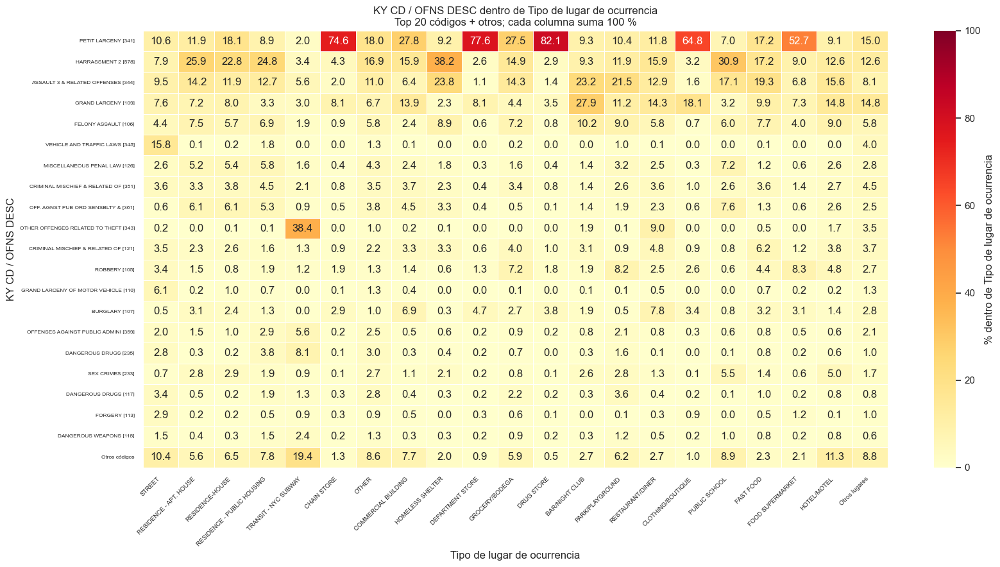

In [325]:
plot_top_premise_heatmap(CODE_LABEL_COLUMNS['KY_CD'], 'KY_CD / OFNS_DESC', top_n=20)

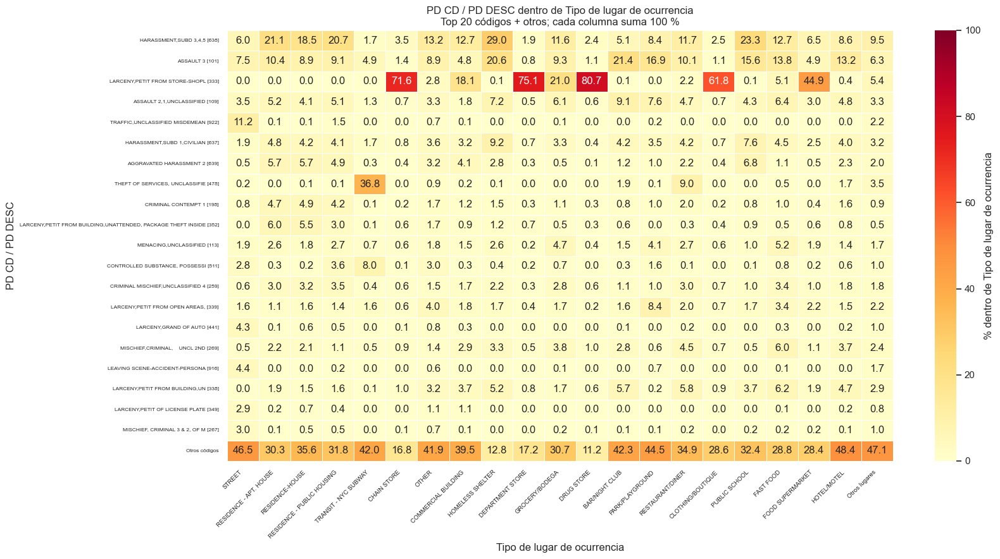

In [326]:
plot_top_premise_heatmap(CODE_LABEL_COLUMNS['PD_CD'], 'PD_CD / PD_DESC', top_n=20)

### Mapas de incidentes:

/tmp/ipykernel_2747609/1551298847.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  centroids = geo.groupby('BORO_NM')[['X_COORD_CD', 'Y_COORD_CD']].mean()


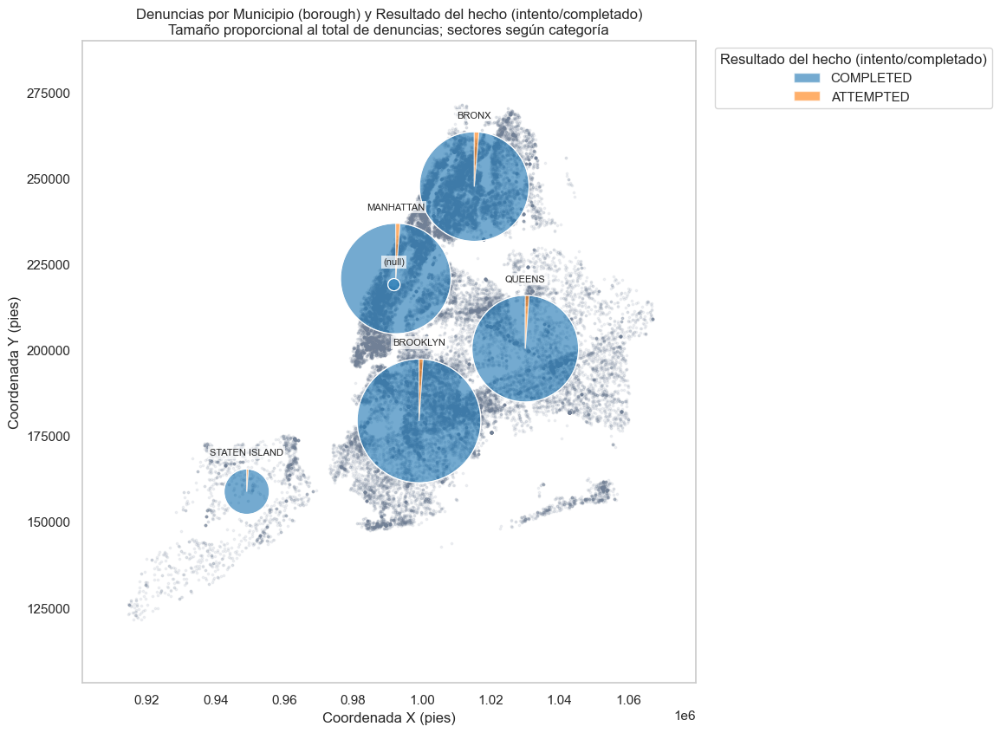

/tmp/ipykernel_2747609/1551298847.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  centroids = geo.groupby('BORO_NM')[['X_COORD_CD', 'Y_COORD_CD']].mean()


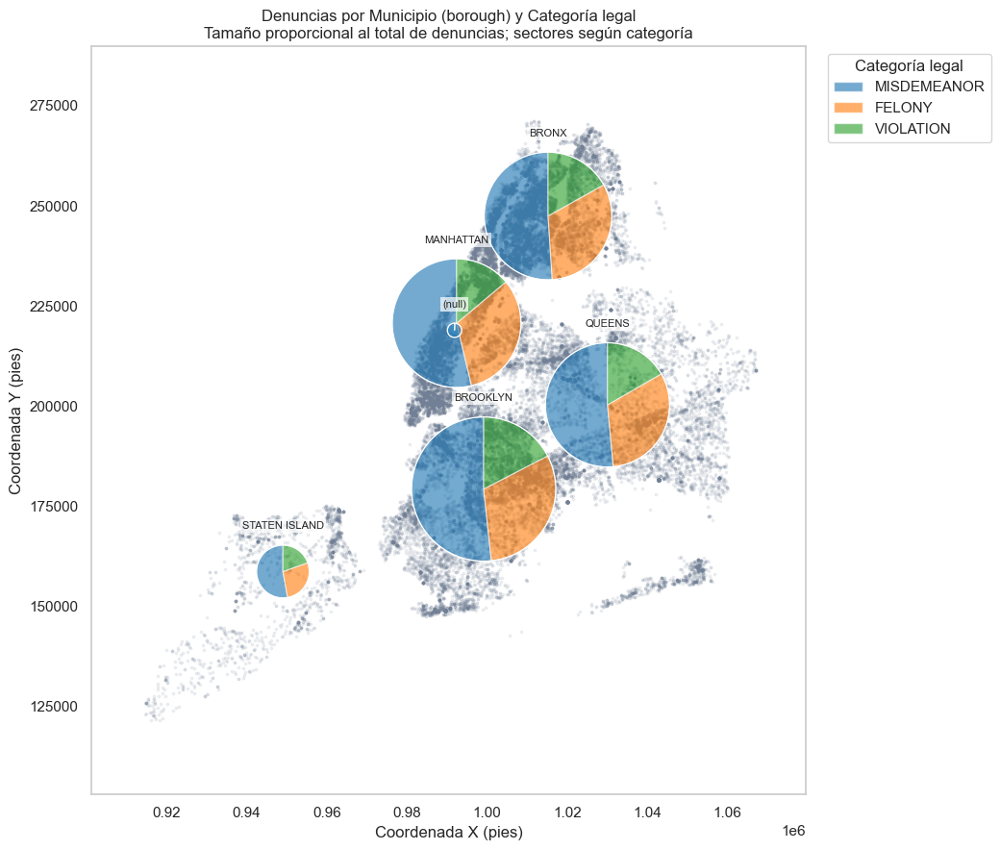

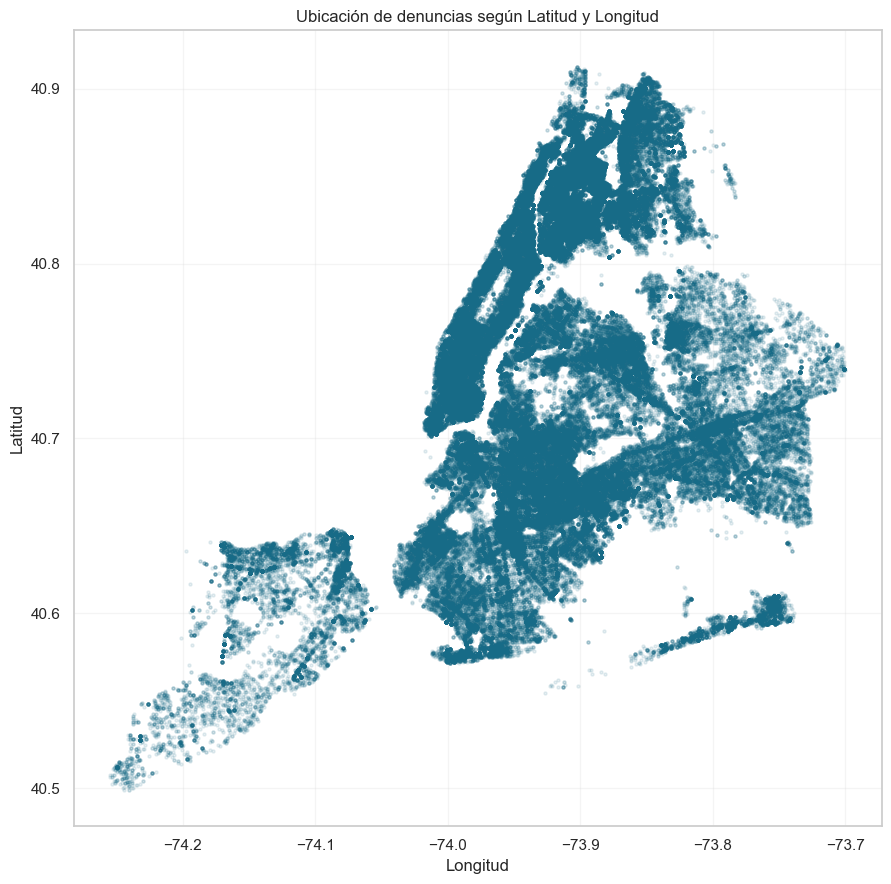

In [ ]:
def plot_borough_pie_map(stack_col, title):
    valid_coords = (
        plot_df['X_COORD_CD'].notna() & plot_df['Y_COORD_CD'].notna()
        & plot_df['X_COORD_CD'].gt(0) & plot_df['Y_COORD_CD'].gt(0)
        & plot_df['BORO_NM'].ne(UNKNOWN_LABEL)
    )
    geo = plot_df.loc[valid_coords]
    if geo.empty:
        print('No hay coordenadas válidas para construir el mapa.')
        return

    centroids = geo.groupby('BORO_NM')[['X_COORD_CD', 'Y_COORD_CD']].mean()
    boroughs = [b for b in BOROUGH_ORDER if b in centroids.index]
    boroughs += [b for b in centroids.index if b not in boroughs]
    totals = plot_df.loc[plot_df['BORO_NM'].ne(UNKNOWN_LABEL), 'BORO_NM'].value_counts()
    category_order = geo[stack_col].value_counts().index.tolist()
    colors = sns.color_palette('tab10', n_colors=max(1, len(category_order)))
    color_by_category = dict(zip(category_order, colors))

    fig, ax = plt.subplots(figsize=(11, 9))
    background = geo.sample(n=min(50000, len(geo)), random_state=42)
    ax.scatter(
        background['X_COORD_CD'], background['Y_COORD_CD'],
        s=3, color='#718096', alpha=0.10, rasterized=True, zorder=1
    )
    max_total = totals.reindex(boroughs).dropna().max()
    max_radius = 18000

    for borough in boroughs:
        center = (centroids.loc[borough, 'X_COORD_CD'], centroids.loc[borough, 'Y_COORD_CD'])
        radius = max_radius * np.sqrt(totals.get(borough, 0) / max_total)
        counts = geo.loc[geo['BORO_NM'].eq(borough), stack_col].value_counts()
        counts = counts.reindex(category_order, fill_value=0)
        counts = counts[counts.gt(0)]
        pie_total = counts.sum()
        angle_start = 90
        for category, value in counts.items():
            angle_end = angle_start + 360 * value / pie_total
            ax.add_patch(Wedge(
                center, radius, angle_start, angle_end,
                facecolor=color_by_category[category], edgecolor='white',
                linewidth=0.8, alpha=0.62, zorder=3
            ))
            angle_start = angle_end
        ax.add_patch(Circle(center, radius, fill=False, edgecolor='white', linewidth=0.8, zorder=4))
        ax.annotate(
            borough, (center[0], center[1] + radius + 3500),
            ha='center', va='bottom', fontsize=8,
            bbox={'facecolor': 'white', 'alpha': 0.70, 'edgecolor': 'none', 'pad': 1.5}, zorder=5
        )

    handles = [
        Patch(facecolor=color_by_category[label], edgecolor='white', alpha=0.62, label=label)
        for label in category_order
    ]
    ax.legend(handles=handles, title=plot_label(stack_col),
              bbox_to_anchor=(1.02, 1), loc='upper left')
    x_range = geo['X_COORD_CD'].max() - geo['X_COORD_CD'].min()
    y_range = geo['Y_COORD_CD'].max() - geo['Y_COORD_CD'].min()
    ax.set_xlim(geo['X_COORD_CD'].min() - x_range * 0.08,
                geo['X_COORD_CD'].max() + x_range * 0.08)
    ax.set_ylim(geo['Y_COORD_CD'].min() - y_range * 0.12,
                geo['Y_COORD_CD'].max() + y_range * 0.12)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title + '\nTamaño proporcional al total de denuncias; sectores según categoría')
    ax.set_xlabel(plot_label('X_COORD_CD'))
    ax.set_ylabel(plot_label('Y_COORD_CD'))
    ax.grid(False)
    fig.subplots_adjust(right=0.79)
    show_plot(fig)

# Cada borough se ubica por el centro promedio de sus coordenadas NY State Plane.
plot_borough_pie_map('CRM_ATPT_CPTD_CD', f'Denuncias por {plot_label("BORO_NM")} y {plot_label("CRM_ATPT_CPTD_CD")}')
plot_borough_pie_map('LAW_CAT_CD', f'Denuncias por {plot_label("BORO_NM")} y {plot_label("LAW_CAT_CD")}')

# Cada punto representa una coordenada de incidente; se descartan coordenadas fuera del área de NYC.
latlon = plot_df[['Longitude', 'Latitude']].dropna()
latlon = latlon[
    latlon['Latitude'].between(40.4, 41.1)
    & latlon['Longitude'].between(-74.3, -73.6)
]
fig, ax = plt.subplots(figsize=(11, 9))
ax.scatter(
    latlon['Longitude'], latlon['Latitude'],
    s=5, marker='o', color='#176B87', alpha=0.10, rasterized=True
)
ax.set_aspect(1 / np.cos(np.deg2rad(40.7)), adjustable='box')
ax.set_title(f'Ubicación de denuncias según {plot_label("Latitude")} y {plot_label("Longitude")}')
ax.set_xlabel(plot_label('Longitude'))
ax.set_ylabel(plot_label('Latitude'))
ax.grid(alpha=0.2)
show_plot(fig)

### Mapas con OpenStreetMap:

Estas son versiones adicionales de los tres mapas anteriores: los mapas originales se mantienen intactos. Al ejecutar la celda de gráficos, se descargan tiles de OpenStreetMap, que se guardan en memoria durante la sesión para reutilizarlos. Se muestra la atribución requerida a OpenStreetMap.

In [ ]:
import time
from io import BytesIO
import requests
from matplotlib.patches import Circle, Patch, Wedge

OSM_TILE_URL = 'https://tile.openstreetmap.org/{z}/{x}/{y}.png'
OSM_ZOOM = 11
OSM_BOUNDS = (-74.30, 40.48, -73.65, 40.95)  # west, south, east, north
OSM_MAX_TILES = 64
WEB_MERCATOR_RADIUS = 6378137.0
OSM_TILE_CACHE = {}
OSM_SESSION = requests.Session()
OSM_SESSION.headers.update({'User-Agent': 'CEIA-Analisis-de-datos/1.0 (Jupyter notebook)'})

def lonlat_to_web_mercator(longitude, latitude):
    latitude = np.clip(np.asarray(latitude, dtype=float), -85.05112878, 85.05112878)
    longitude = np.asarray(longitude, dtype=float)
    x = WEB_MERCATOR_RADIUS * np.deg2rad(longitude)
    y = WEB_MERCATOR_RADIUS * np.log(np.tan(np.pi / 4 + np.deg2rad(latitude) / 2))
    return x, y

def lonlat_to_osm_tile(longitude, latitude, zoom):
    latitude = np.clip(latitude, -85.05112878, 85.05112878)
    tile_count = 2 ** zoom
    x = int((longitude + 180.0) / 360.0 * tile_count)
    latitude_rad = np.deg2rad(latitude)
    y = int((1.0 - np.arcsinh(np.tan(latitude_rad)) / np.pi) / 2.0 * tile_count)
    return min(max(x, 0), tile_count - 1), min(max(y, 0), tile_count - 1)

def osm_tile_extent(tile_x, tile_y, zoom):
    tile_count = 2 ** zoom
    world_width = 2 * np.pi * WEB_MERCATOR_RADIUS
    west = tile_x / tile_count * world_width - np.pi * WEB_MERCATOR_RADIUS
    east = (tile_x + 1) / tile_count * world_width - np.pi * WEB_MERCATOR_RADIUS
    north = np.pi * WEB_MERCATOR_RADIUS - tile_y / tile_count * world_width
    south = np.pi * WEB_MERCATOR_RADIUS - (tile_y + 1) / tile_count * world_width
    return west, east, south, north

def fetch_osm_tile(zoom, tile_x, tile_y):
    key = (zoom, tile_x, tile_y)
    if key not in OSM_TILE_CACHE:
        if OSM_TILE_CACHE:
            time.sleep(0.55)  # Keep requests below two tiles per second.
        url = OSM_TILE_URL.format(z=zoom, x=tile_x, y=tile_y)
        response = OSM_SESSION.get(url, timeout=20)
        response.raise_for_status()
        OSM_TILE_CACHE[key] = plt.imread(BytesIO(response.content), format='png')
    return OSM_TILE_CACHE[key]

def draw_osm_basemap(ax, bounds=OSM_BOUNDS, zoom=OSM_ZOOM):
    west, south, east, north = bounds
    first_x, first_y = lonlat_to_osm_tile(west, north, zoom)
    last_x, last_y = lonlat_to_osm_tile(east, south, zoom)
    requested_tiles = (last_x - first_x + 1) * (last_y - first_y + 1)
    if requested_tiles > OSM_MAX_TILES:
        raise ValueError(f'El área requiere {requested_tiles} tiles; reduce el zoom o el área.')

    for tile_x in range(first_x, last_x + 1):
        for tile_y in range(first_y, last_y + 1):
            extent = osm_tile_extent(tile_x, tile_y, zoom)
            ax.imshow(
                fetch_osm_tile(zoom, tile_x, tile_y), extent=extent,
                origin='upper', interpolation='bilinear', zorder=0
            )

    x_min, y_min = lonlat_to_web_mercator(west, south)
    x_max, y_max = lonlat_to_web_mercator(east, north)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_aspect('equal', adjustable='box')
    ax.set_axis_off()
    ax.text(
        0.01, 0.01, '© OpenStreetMap contributors', transform=ax.transAxes,
        fontsize=8, color='#222222',
        bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none', 'pad': 2}, zorder=10
    )

# Prepare a map-only copy; the original dataframe and existing maps remain unchanged.
osm_points = plot_df[[
    'BORO_NM', 'CRM_ATPT_CPTD_CD', 'LAW_CAT_CD',
    'Latitude', 'Longitude'
]].dropna(subset=['Latitude', 'Longitude']).copy()
west, south, east, north = OSM_BOUNDS
inside_nyc = (
    osm_points['Longitude'].between(west, east)
    & osm_points['Latitude'].between(south, north)
)
osm_points = osm_points.loc[inside_nyc].copy()
osm_points['X_OSM'], osm_points['Y_OSM'] = lonlat_to_web_mercator(
    osm_points['Longitude'], osm_points['Latitude']
)
print(f'Incidentes con coordenadas dentro del mapa: {len(osm_points):,}')

Incidentes con coordenadas dentro del mapa: 279,512


/tmp/ipykernel_2747609/585494878.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  centroids = pie_data.groupby('BORO_NM')[['X_OSM', 'Y_OSM']].mean()


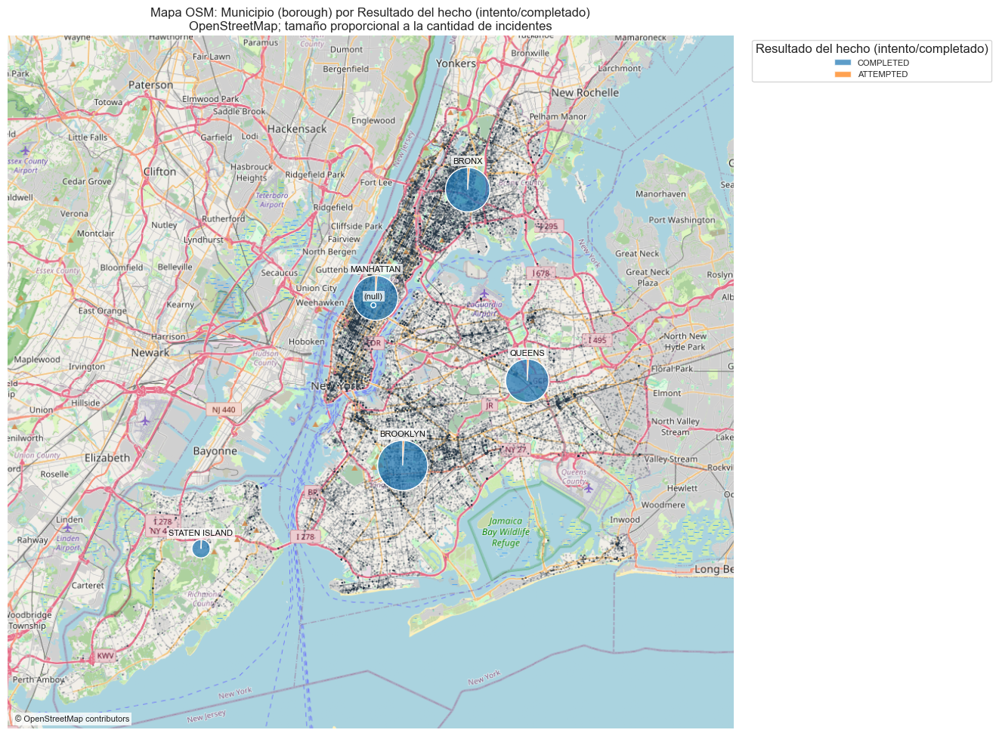

/tmp/ipykernel_2747609/585494878.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  centroids = pie_data.groupby('BORO_NM')[['X_OSM', 'Y_OSM']].mean()


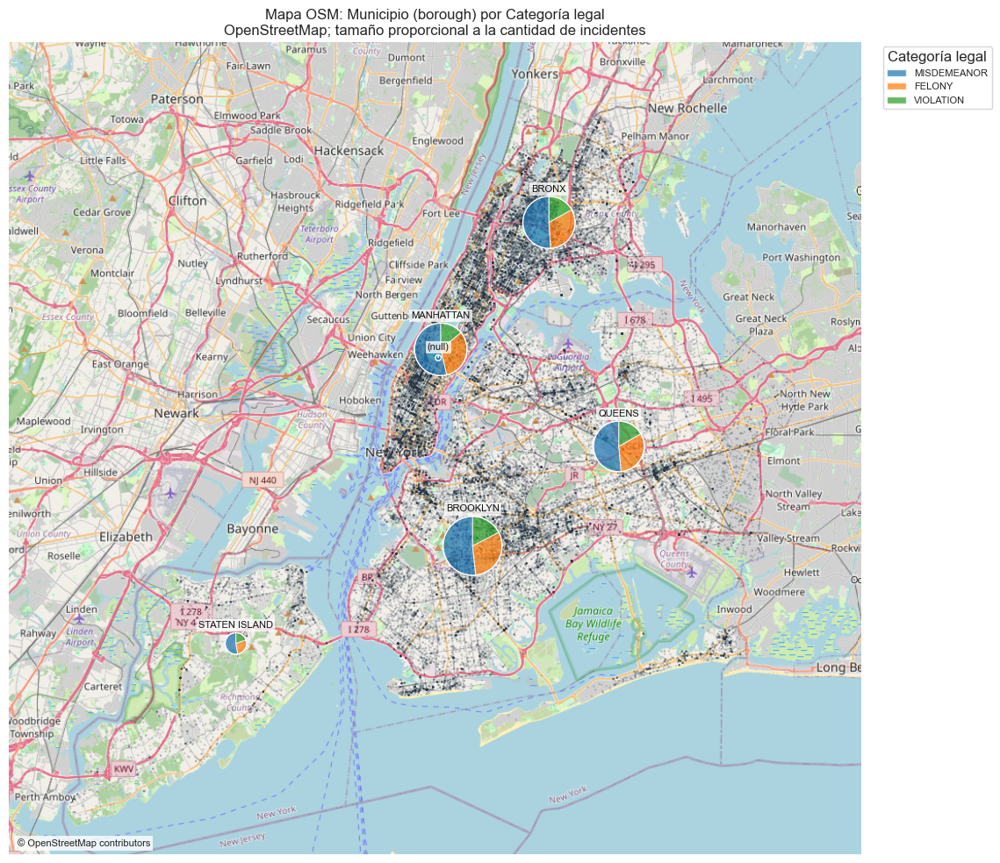

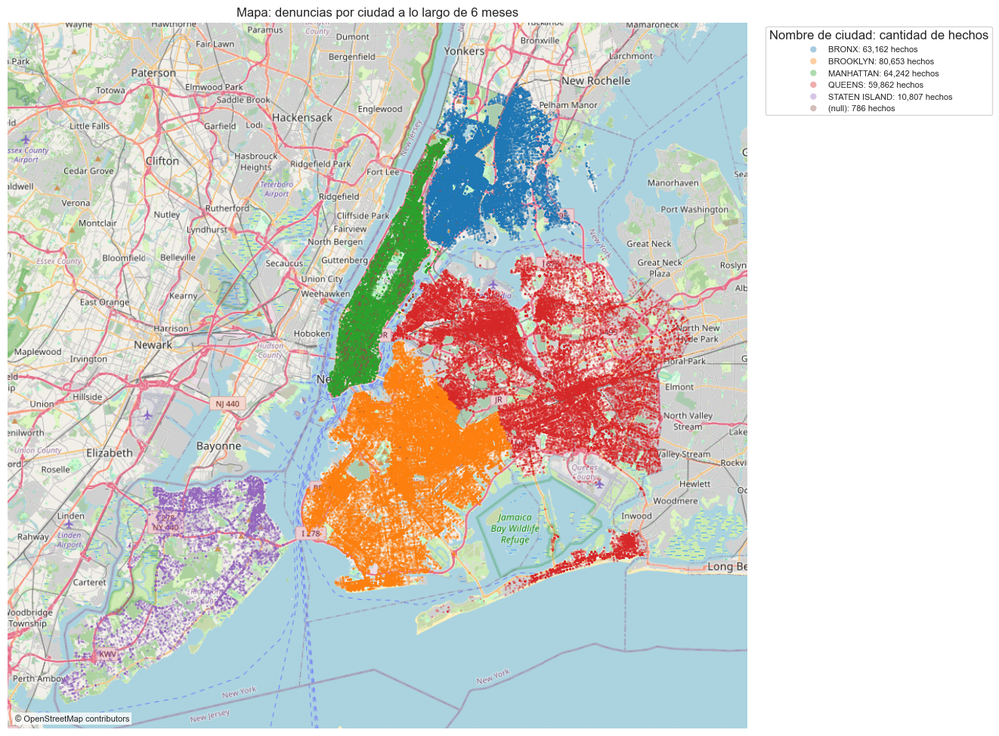

In [ ]:
def plot_borough_osm_pies(stack_col, title):
    pie_data = osm_points.loc[osm_points['BORO_NM'].ne(UNKNOWN_LABEL)]
    centroids = pie_data.groupby('BORO_NM')[['X_OSM', 'Y_OSM']].mean()
    boroughs = [borough for borough in BOROUGH_ORDER if borough in centroids.index]
    boroughs += [borough for borough in centroids.index if borough not in boroughs]
    totals = pie_data['BORO_NM'].value_counts()
    category_order = pie_data[stack_col].value_counts().index.tolist()
    colors = sns.color_palette('tab10', n_colors=max(1, len(category_order)))
    color_by_category = dict(zip(category_order, colors))

    fig, ax = plt.subplots(figsize=(13, 10))
    draw_osm_basemap(ax)
    background = osm_points.sample(n=min(50000, len(osm_points)), random_state=42)
    ax.scatter(
        background['X_OSM'], background['Y_OSM'], s=3,
        color='#263746', alpha=0.20, edgecolors='none', rasterized=True, zorder=2
    )
    max_total = totals.reindex(boroughs).max()

    for borough in boroughs:
        center = (centroids.loc[borough, 'X_OSM'], centroids.loc[borough, 'Y_OSM'])
        radius = 2500 * np.sqrt(totals.loc[borough] / max_total)
        counts = pie_data.loc[pie_data['BORO_NM'].eq(borough), stack_col].value_counts()
        counts = counts.reindex(category_order, fill_value=0)
        counts = counts[counts.gt(0)]
        angle_start = 90
        for category, count in counts.items():
            angle_end = angle_start + 360 * count / counts.sum()
            ax.add_patch(Wedge(
                center, radius, angle_start, angle_end,
                facecolor=color_by_category[category], edgecolor='white',
                linewidth=0.8, alpha=0.72, zorder=4
            ))
            angle_start = angle_end
        ax.add_patch(Circle(center, radius, fill=False, edgecolor='white', linewidth=0.9, zorder=5))
        ax.annotate(
            borough, (center[0], center[1] + radius + 250),
            ha='center', va='bottom', fontsize=8, color='#111111',
            bbox={'facecolor': 'white', 'alpha': 0.75, 'edgecolor': 'none', 'pad': 1.5}, zorder=6
        )

    handles = [
        Patch(facecolor=color_by_category[label], edgecolor='white', alpha=0.72, label=label)
        for label in category_order
    ]
    ax.legend(handles=handles, title=plot_label(stack_col),
              bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
    ax.set_title(title + '\nOpenStreetMap; tamaño proporcional a la cantidad de incidentes')
    fig.subplots_adjust(right=0.80)
    show_plot(fig)

# Nuevas versiones de los mapas con gráficos de torta, con tiles de OpenStreetMap como fondo.
plot_borough_osm_pies('CRM_ATPT_CPTD_CD', f'Mapa OSM: {plot_label("BORO_NM")} por {plot_label("CRM_ATPT_CPTD_CD")}')
plot_borough_osm_pies('LAW_CAT_CD', f'Mapa OSM: {plot_label("BORO_NM")} por {plot_label("LAW_CAT_CD")}')

# Nueva versión del mapa scatter; puntos coloreados por borough.
fig, ax = plt.subplots(figsize=(13, 10))
draw_osm_basemap(ax)
map_borough_counts = osm_points['BORO_NM'].value_counts()
map_borough_order = [b for b in BOROUGH_ORDER if b in map_borough_counts.index]
map_borough_order += [b for b in map_borough_counts.index if b not in map_borough_order]
map_borough_palette = sns.color_palette('tab10', n_colors=len(map_borough_order))
map_borough_colors = dict(zip(map_borough_order, map_borough_palette))
if UNKNOWN_LABEL in map_borough_colors:
    map_borough_colors[UNKNOWN_LABEL] = '#7f7f7f'

for borough in map_borough_order:
    borough_points = osm_points.loc[osm_points['BORO_NM'].eq(borough)]
    ax.scatter(
        borough_points['X_OSM'], borough_points['Y_OSM'], s=4,
        color=map_borough_colors[borough], alpha=0.38, edgecolors='none',
        rasterized=True, zorder=2,
        label=f'{borough}: {len(borough_points):,} hechos'
    )
ax.set_title('Mapa: denuncias por ciudad a lo largo de 6 meses')
ax.legend(title='Nombre de ciudad: cantidad de hechos', bbox_to_anchor=(1.02, 1),
          loc='upper left', fontsize=8, markerscale=3)
fig.subplots_adjust(right=0.80)
fig.savefig('mapa_denuncias_por_ciudad.pdf', format='pdf', dpi=300, bbox_inches='tight')
fig.savefig('mapa_denuncias_por_ciudad.png', format='png', dpi=300, bbox_inches='tight')
show_plot(fig)

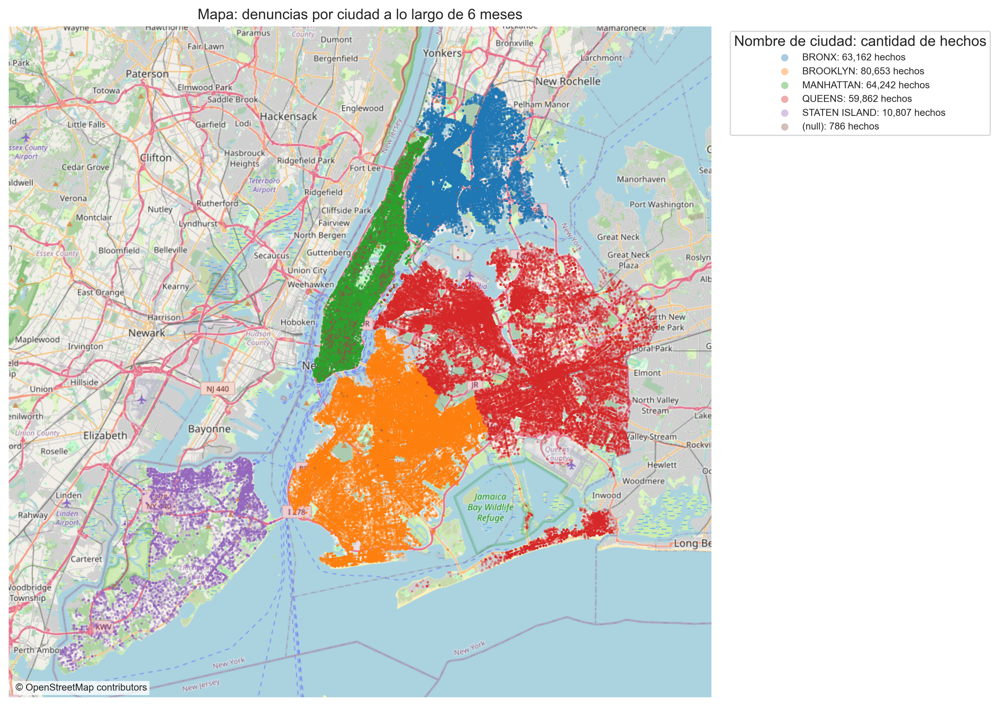

In [ ]:
image_path = 'mapa_denuncias_por_ciudad.png'
Image(filename=image_path)

/tmp/ipykernel_2747609/2065266409.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  centroids = geo[geo['BORO_NM'].ne(UNKNOWN_LABEL)].groupby(


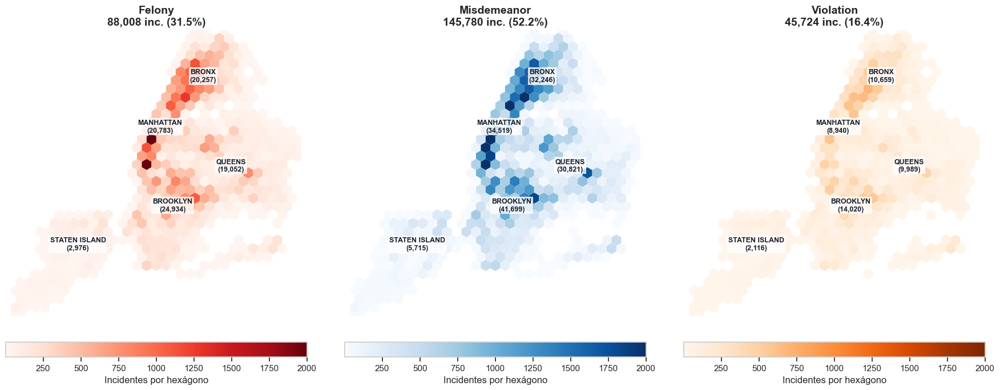

In [328]:
def plot_hexbin_spatial_by_law():
    valid = (
        plot_df['Longitude'].notna() & plot_df['Latitude'].notna()
        & plot_df['Latitude'].between(40.4, 41.1)
        & plot_df['Longitude'].between(-74.3, -73.6)
        & plot_df['LAW_CAT_CD'].ne(UNKNOWN_LABEL)
    )
    geo = plot_df.loc[valid, ['Longitude', 'Latitude', 'LAW_CAT_CD', 'BORO_NM']].copy()

    total = len(geo)
    law_order = [l for l in ['FELONY', 'MISDEMEANOR', 'VIOLATION']
                 if l in geo['LAW_CAT_CD'].unique()]
    cmaps = {'FELONY': 'Reds', 'MISDEMEANOR': 'Blues', 'VIOLATION': 'Oranges'}
    titles = {'FELONY': 'Felony', 'MISDEMEANOR': 'Misdemeanor', 'VIOLATION': 'Violation'}

    centroids = geo[geo['BORO_NM'].ne(UNKNOWN_LABEL)].groupby(
        'BORO_NM')[['Longitude', 'Latitude']].mean()
    boroughs = [b for b in BOROUGH_ORDER if b in centroids.index]

    extent = [
        geo['Longitude'].min(), geo['Longitude'].max(),
        geo['Latitude'].min(), geo['Latitude'].max()
    ]

    fig, axes = plt.subplots(1, 3, figsize=(18, 7), facecolor='white')

    for ax, law in zip(axes, law_order):
        sub = geo[geo['LAW_CAT_CD'] == law]
        hb = ax.hexbin(
            sub['Longitude'], sub['Latitude'],
            gridsize=30, cmap=cmaps[law], mincnt=1,
            vmax=2000, extent=extent, edgecolors='none'
        )

        ax.set_aspect(1 / np.cos(np.deg2rad(40.7)))
        ax.set_xlim(extent[0], extent[1])
        ax.set_ylim(extent[2], extent[3])
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

        cat_total = len(sub)
        pct = 100 * cat_total / total if total else 0
        ax.set_title(f'{titles[law]}\n{cat_total:,} inc. ({pct:.1f}%)', fontsize=14, fontweight='bold')

        cbar = fig.colorbar(hb, ax=ax, orientation='horizontal', pad=0.08, fraction=0.046)
        cbar.set_label('Incidentes por hexágono')

        b_counts = sub['BORO_NM'].value_counts()
        for b in boroughs:
            x, y = centroids.loc[b]
            cnt = b_counts.get(b, 0)
            ax.text(
                x, y, f'{b}\n({cnt:,})',
                ha='center', va='center', fontsize=9, fontweight='bold', color='#1a202c',
                bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none', 'pad': 1.5}
            )

    plt.tight_layout()
    fig.savefig('../Analisis-de-datos-tp-final/infographic/images/mapa_espacial_gravedad_1.png', format='png', dpi=300, bbox_inches='tight')
    fig.savefig('../Analisis-de-datos-tp-final/infographic/images/mapa_espacial_gravedad_1.pdf', format='pdf', dpi=300, bbox_inches='tight')
    show_plot(fig)

plot_hexbin_spatial_by_law()

## Exportar el gráfico de PREM_TYP_DESC a LaTeX

La celda siguiente usa los 10 lugares más frecuentes, ordenados de mayor a menor de arriba hacia abajo, y conserva los conteos absolutos del gráfico apilado. Imprime la tabla de conteos y el bloque TikZ/PGFPlots completo.

In [ ]:
"""
LAW_ORDER_LATEX = ['FELONY', 'MISDEMEANOR', 'VIOLATION']
law_values_latex = plot_df['LAW_CAT_CD'].astype('string').str.upper()
unexpected_law_categories = sorted(set(law_values_latex.dropna()) - set(LAW_ORDER_LATEX))
if unexpected_law_categories:
    raise ValueError(
        'Hay categorías LAW_CAT_CD no contempladas por la leyenda del LaTeX: '
        + ', '.join(unexpected_law_categories)
    )

top_premises_latex = (
    plot_df['PREM_TYP_DESC'].value_counts()
    .sort_values(ascending=False).head(10).index.tolist()
)
law_counts_latex = pd.crosstab(
    plot_df['PREM_TYP_DESC'], law_values_latex
).reindex(index=top_premises_latex, columns=LAW_ORDER_LATEX, fill_value=0)
law_row_totals = law_counts_latex.sum(axis=1)
xmax_latex = int(np.ceil(law_row_totals.max() * 1.05 / 1000) * 1000)

print('Conteos usados:')
print(law_counts_latex.to_string())

bs = chr(92)
latex_replacements = {
    '&': bs + '&', '%': bs + '%', '$': bs + '$', '#': bs + '#',
    '_': bs + '_', '{': bs + '{', '}': bs + '}'
}

def escape_latex_label(label):
    return ''.join(latex_replacements.get(char, char) for char in str(label))

latex_lines = [
    bs + 'begin{center}',
    '    ' + bs + 'begin{tikzpicture}',
    '        ' + bs + 'begin{axis}[',
    '            xbar stacked,',
    '            width=6.5cm,',
    '            height=5.6cm,',
    '            bar width=4.5pt,',
    '            xmin=0, xmax=' + str(xmax_latex) + ',',
    '            scaled x ticks=false,',
    '            enlarge y limits=0.04,',
    '            symbolic y coords={'
]
for index, premise in enumerate(top_premises_latex):
    comma = ',' if index < len(top_premises_latex) - 1 else ''
    latex_lines.append('                ' + escape_latex_label(premise) + comma)
latex_lines.extend([
    '            },',
    '            ytick=data,',
    '            y dir=reverse,',
    '            yticklabel style={font=' + bs + 'fontsize{5}{6}' + bs + 'selectfont, text=primary, text width=3.4cm, align=right, inner sep=0pt},',
    '            xticklabel style={font=' + bs + 'tiny, text=primary},',
    '            xlabel={Cantidad de denuncias},',
    '            xlabel style={font=' + bs + 'scriptsize, text=primary},',
    '            legend style={at={(0.5,-0.2)}, anchor=north, legend columns=3, font=' + bs + 'tiny, draw=none, fill=none, column sep=1ex},',
    '            reverse legend=true,',
    '            axis lines*=left,',
    '            ymajorgrids=true,',
    '            grid style=dashed',
    '        ]'
])

law_plot_styles = [
    ('FELONY', 'primary'),
    ('MISDEMEANOR', 'graymid'),
    ('VIOLATION', 'secondary')
]
for law_category, fill_color in law_plot_styles:
    latex_lines.append('            ' + bs + 'addplot[fill=' + fill_color + ', draw=none] coordinates {')
    for premise in top_premises_latex:
        value = law_counts_latex.loc[premise, law_category]
        latex_lines.append(
            f'                ({int(value)},{escape_latex_label(premise)})'
        )
    latex_lines.append('            };')
    latex_lines.append('')

latex_lines.extend([
    '            ' + bs + 'legend{Felony, Misdemeanor, Violation}',
    '        ' + bs + 'end{axis}',
    '    ' + bs + 'end{tikzpicture}',
    bs + 'end{center}'
])
print('\nLaTeX completo:\n')
print(chr(10).join(latex_lines))
"""

"\nLAW_ORDER_LATEX = ['FELONY', 'MISDEMEANOR', 'VIOLATION']\nlaw_values_latex = plot_df['LAW_CAT_CD'].astype('string').str.upper()\nunexpected_law_categories = sorted(set(law_values_latex.dropna()) - set(LAW_ORDER_LATEX))\nif unexpected_law_categories:\n    raise ValueError(\n        'Hay categorías LAW_CAT_CD no contempladas por la leyenda del LaTeX: '\n        + ', '.join(unexpected_law_categories)\n    )\n\ntop_premises_latex = (\n    plot_df['PREM_TYP_DESC'].value_counts()\n    .sort_values(ascending=False).head(10).index.tolist()\n)\nlaw_counts_latex = pd.crosstab(\n    plot_df['PREM_TYP_DESC'], law_values_latex\n).reindex(index=top_premises_latex, columns=LAW_ORDER_LATEX, fill_value=0)\nlaw_row_totals = law_counts_latex.sum(axis=1)\nxmax_latex = int(np.ceil(law_row_totals.max() * 1.05 / 1000) * 1000)\n\nprint('Conteos usados:')\nprint(law_counts_latex.to_string())\n\nbs = chr(92)\nlatex_replacements = {\n    '&': bs + '&', '%': bs + '%', '$': bs + '$', '#': bs + '#',\n    '_': bs

## Convertir nuestra mini-infografía pdf a ppt

In [329]:
"""
from pdf2image import convert_from_path
from pptx import Presentation
from pptx.util import Inches
import os
 
pdf_path = "../Analisis-de-datos-tp-final/infographic/TP_Report_2026.pdf"
pptx_path = "../Analisis-de-datos-tp-final/infographic/TP_Report_2026.pptx"
 
images = convert_from_path(pdf_path, dpi=300, fmt="png")
output_dir = "/tmp/report_slides"
os.makedirs(output_dir, exist_ok=True)
 
prs = Presentation()
prs.slide_width = Inches(13.333)
prs.slide_height = Inches(7.5)
blank_layout = prs.slide_layouts[6]
 
for i, img in enumerate(images):
    img_path = os.path.join(output_dir, f"slide_{i:02d}.png")
    img.save(img_path)
    slide = prs.slides.add_slide(blank_layout)
    # Add picture preserving aspect, fit to slide height or width
    picture = slide.shapes.add_picture(img_path, Inches(0), Inches(0))
    img_aspect = img.width / img.height
    slide_aspect = prs.slide_width / prs.slide_height
    if img_aspect > slide_aspect:
        picture.width = prs.slide_width
        picture.height = int(prs.slide_width / img_aspect)
        picture.top = (prs.slide_height - picture.height) // 2
        picture.left = 0
    else:
        picture.height = prs.slide_height
        picture.width = int(prs.slide_height * img_aspect)
        picture.left = (prs.slide_width - picture.width) // 2
        picture.top = 0
 
prs.save(pptx_path)
print(f"Guardado en {pptx_path}")
"""

'\nfrom pdf2image import convert_from_path\nfrom pptx import Presentation\nfrom pptx.util import Inches\nimport os\n\npdf_path = "../Analisis-de-datos-tp-final/infographic/TP_Report_2026.pdf"\npptx_path = "../Analisis-de-datos-tp-final/infographic/TP_Report_2026.pptx"\n\nimages = convert_from_path(pdf_path, dpi=300, fmt="png")\noutput_dir = "/tmp/report_slides"\nos.makedirs(output_dir, exist_ok=True)\n\nprs = Presentation()\nprs.slide_width = Inches(13.333)\nprs.slide_height = Inches(7.5)\nblank_layout = prs.slide_layouts[6]\n\nfor i, img in enumerate(images):\n    img_path = os.path.join(output_dir, f"slide_{i:02d}.png")\n    img.save(img_path)\n    slide = prs.slides.add_slide(blank_layout)\n    # Add picture preserving aspect, fit to slide height or width\n    picture = slide.shapes.add_picture(img_path, Inches(0), Inches(0))\n    img_aspect = img.width / img.height\n    slide_aspect = prs.slide_width / prs.slide_height\n    if img_aspect > slide_aspect:\n        picture.width = prs